In [1]:
source(here::here('MG3.functions1.R')) # reloading the get the handles created


In [10]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM interestinggenes'
interestingGenes=dbGetQuery(mydbRO, queryTxt)[[1]]
processedGenes=readLines('~/data/lambda/output/step9Trees/plot_interesting_genes-2026-02-12_12.12.00.119328.swarm')
processedGenes=processedGenes[-1]
processedGenes=unlist(lapply(str_split(string = processedGenes, pattern = " "),FUN = function(x) return(x[[length(x)]]) ))

In [12]:
setdiff( processedGenes, interestingGenes)

[1] "ENSG00000140374"

In [13]:
setdiff(interestingGenes, processedGenes)

character(0)

In [5]:
queryTxt='SELECT COUNT( DISTINCT ensembl_gene_id ) FROM positively_ided_using_context'
dbGetQuery(mydbRO, queryTxt)

COUNT( DISTINCT ensembl_gene_id )
<int>
9608


# Prev field

In [2]:
inSp="hsapiens"
queryTxt=sprintf('SELECT DISTINCT gene_id, gene_version, transcript_id, transcript_version FROM gene_transcripts WHERE specie="%s" AND tag="Ensembl_canonical"', inSp)
tmp_transcriptsDF=dbGetQuery(EntrezdbRO, queryTxt)

In [8]:
tmp_transcriptsDF=tmp_transcriptsDF %>% group_by(gene_id) %>% filter(gene_version==max(gene_version)) %>% ungroup() %>% 
    group_by(transcript_id) %>% filter(transcript_version==max(transcript_version))

In [12]:
queryTxt=sprintf('SELECT DISTINCT peptide_id, peptide_ver, transcript_id, transcript_ver, peptide, LENGTH(peptide) AS peptide_length FROM peptides WHERE specie="%s"', inSp)
tmp_peptidesDF=dbGetQuery(EntrezdbRO, queryTxt)


In [13]:
tmp_peptidesDF = tmp_peptidesDF %>% group_by(peptide_id) %>% filter(peptide_ver == max(peptide_ver))

In [15]:
tmp_peptidesDF = as.data.table(tmp_peptidesDF %>% group_by(peptide_id) %>% filter(peptide_length == max(peptide_length)))

In [17]:
nrow(tmp_peptidesDF)

[1] 245535

In [19]:
length(unique(tmp_peptidesDF$transcript_id))

[1] 245535

In [26]:
retrieveSpecieProteinsLocalSQL(inSp, c("ENSG00000000003", "ENSG00000000005", "ENSG00000000419", "ENSG00000000457", "ENSG00000000460"))

hsapiens

Peptides query

Length filter

Key 2

Key 3

Merge in function



ensembl_transcript_id,ensembl_gene_id,gene_version,transcript_version,ensembl_peptide_id,peptide_version,transcript_ver,peptide,peptide_length,specie
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<int>,<chr>
ENST00000359326,ENSG00000000460,18,9,ENSP00000352276,4,9,MFLPHMNHLTLEQTFFSQVLPKTVKLFDDMMYELTSQARGLSSQNLEIQTTLRNILQTMVQLLGALTGCVQHICATQESIILENIQSLPSSVLHIIKSTFVHCKNSESVYSGCLHLVSDLLQALFKEAYSLQKQLMELLDMVCMDPLVDDNDDILNMVIVIHSLLDICSVISSMDHAFHANTWKFIIKQSLKHQSIIKSQLKHKDIITSLCEDILFSFHSCLQLAEQMTQSDAQDNADYRLFQKTLKLCRFFANSLLHYAKEFLPFLSDSCCTLHQLYLQIHSKFPPSLYATRISKAHQEEIAGAFLVTLDPLISQLLTFQPFMQVVLDSKLDLPCELQFPQCLLLVVVMDKLPSQPKEVQTLWCTDSQVSETTTRISLLKAVFYSFEQCSGELSLPVHLQGLKSKGKAEVAVTLYQHVCVHLCTFITSFHPSLFAELDAALLNAVLSANMITSLLAMDAWCFLARYGTAELCAHHVTIVAHLIKSCPGECYQLINLSILLKRLFFFMAPPHQLEFIQKFSPKEAENLPLWQHISFQALPPELREQTVHEVTTVGTAECRKWLSRSRTLGELESLNTVLSALLAVCNSAGEALDTGKQTAIIEVVSQLWAFLNIKQVADQPYVQQTFSLLLPLLGFFIQTLDPKLILQAVTLQTSLLKLELPDYVRLAMLDFVSSLGKLFIPEAIQDRILPNLSCMFALLLADRSWLLEQHTLEAFTQFAEGTNHEEIVPQCLSSEETKNKVVSFLEKTGFVDETEAAKVERVKQEKGIFWEPFANVTVEEAKRSSLQPYAKRARQEFPWEEEYRSALHTIAGALEATESLLQKGPAPAWLSMEMEALQERMDKLKRYIHTLG,853,hsapiens
ENST00000367771,ENSG00000000457,15,11,ENSP00000356745,5,11,MGSENSALKSYTLREPPFTLPSGLAVYPAVLQDGKFASVFVYKRENEDKVNKAAKHLKTLRHPCLLRFLSCTVEADGIHLVTERVQPLEVALETLSSAEVCAGIYDILLALIFLHDRGHLTHNNVCLSSVFVSEDGHWKLGGMETVCKVSQATPEFLRSIQSIRDPASIPPEEMSPEFTTLPECHGHARDAFSFGTLVESLLTILNEQVSADVLSSFQQTLHSTLLNPIPKCRPALCTLLSHDFFRNDFLEVVNFLKSLTLKSEEEKTEFFKFLLDRVSCLSEELIASRLVPLLLNQLVFAEPVAVKSFLPYLLGPKKDHAQGETPCLLSPALFQSRVIPVLLQLFEVHEEHVRMVLLSHIEAYVEHFTQEQLKKVILPQVLLGLRDTSDSIVAITLHSLAVLVSLLGPEVVVGGERTKIFKRTAPSFTKNTDLSLEGDPFSQPIKFPINGLSDVKNTSEDSENFPSSSKKSEEWPDWSEPEEPENQTVNIQIWPREPCDDVKSQCTTLDVEESSWDDCEPSSLDTKVNPGGGITATKPVTSGEQKPIPALLSLTEESMPWKSSLPQKISLVQRGDDADQIEPPKVSSQERPLKVPSELGLGEEFTIQVKKKPVKDPEMDWFADMIPEIKPSAAFLILPELRTEMVPKKDDVSPVMQFSSKFAAAEITEGEAEGWEEEGELNWEDNNW,688,hsapiens
ENST00000371588,ENSG00000000419,15,10,ENSP00000360644,5,10,MASLEVSRSPRRSRRELEVRSPRQNKYSVLLPTYNERENLPLIVWLLVKSFSESGINYEIIIIDDGSPDGTRDVAEQLEKIYGSDRILLRPREKKLGLGTAYIHGMKHATGNYIIIMDADLSHHPKFIPEFIRKQKEGNFDIVSGTRYKGNGGVYGWDLKRKIISRGANFLTQILLRPGASDLTGSFRLYRKEVLEKLIEKCVSKGYVFQMEMIVRARQLNYTIGEVPISFVDRVYGESKLGGNEIVSFLKGLLTLFATT,260,hsapiens
ENST00000373020,ENSG00000000003,17,9,ENSP00000362111,4,9,MASPSRRLQTKPVITCFKSVLLIYTFIFWITGVILLAVGIWGKVSLENYFSLLNEKATNVPFVLIATGTVIILLGTFGCFATCRASAWMLKLYAMFLTLVFLVELVAAIVGFVFRHEIKNSFKNNYEKALKQYNSTGDYRSHAVDKIQNTLHCCGVTDYRDWTDTNYYSEKGFPKSCCKLEDCTPQRDADKVNNEGCFIKVMTIIESEMGVVAGISFGVACFQLIGIFLAYCLSRAITNNQYEIV,245,hsapiens
ENST00000373031,ENSG00000000005,6,5,ENSP00000362122,4,5,MAKNPPENCEDCHILNAEAFKSKKICKSLKICGLVFGILALTLIVLFWGSKHFWPEVPKKAYDMEHTFYSNGEKKKIYMEIDPVTRTEIFRSGNGTDETLEVHDFKNGYTGIYFVGLQKCFIKTQIKVIPEFSEPEEEIDENEEITTTFFEQSVIWVPAEKPIENRDFLKNSKILEICDNVTMYWINPTLISVSELQDFEEEGEDLHFPANEKKGIEQNEQWVVPQVKVEKTRHARQASEEELPINDYTENGIEFDPMLDERGYCCIYCRRGNRYCRRVCEPLLGYYPYPYCYQGGRVICRVIMPCNWWVARMLGRV,317,hsapiens


In [28]:
if ("keyAAsequences" %in% dbListTables(mydbRW)) dbExecute(mydbRW, 'DROP TABLE keyAAsequences')


[1] 0

In [29]:
for (sp in KeySpDF$HomologueTable[2]){
    if (nchar(sp)==0){
        spname="hsapiens"
        queryTxt='SELECT DISTINCT ensembl_gene_id FROM homology'
        geneListTMP=dbGetQuery(mydbRO, queryTxt)[[1]]
    }else{
        spname=sp
        queryTxt=sprintf('SELECT DISTINCT homolog FROM homology WHERE specie="%s"', spname)
        geneListTMP=dbGetQuery(mydbRO, queryTxt)[[1]]
    }
    message(spname)
    if ("keyAAsequences" %in% dbListTables(mydbRW)){
        queryTxt=sprintf('SELECT COUNT(ensembl_gene_id) FROM keyAAsequences WHERE specie="%s"', spname) 
        retval=dbGetQuery(mydbRW, queryTxt)
        if (retval[1,1]>0){
            message("Found in DB")
            next
        }
    }
    message("Requesting the data")
    tmp_aaDT=retrieveSpecieProteinsLocalSQL(spname, geneListTMP)
    #dbWriteTable(mydbRW, "keyAAsequences", tmp_aaDT, append=TRUE)
}


mmusculus

Requesting the data

mmusculus

Peptides query

Length filter

Key 2

Key 3

Merge in function



In [31]:
KeySpDF

common,taxon,HomologueTable,genome,EnsemblGTF,EnsemblePepFA,ScientificName
<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
Human,9606,,GCF_009914755.1,Homo_sapiens.GRCh38.115.gtf,Homo_sapiens.GRCh38.pep.all.fa,homo_sapiens
Mouse,10090,mmusculus,GCF_000001635.27,Mus_musculus.GRCm39.115.gtf,Mus_musculus.GRCm39.pep.all.fa,mus_musculus
Dog,9615,clfamiliaris,GCF_011100685.1,Canis_lupus_familiaris.ROS_Cfam_1.0.115.gtf,Canis_lupus_familiaris.ROS_Cfam_1.0.pep.all.fa,canis_lupus_familiaris
Cat,9685,fcatus,GCF_018350175.1,Felis_catus.F.catus_Fca126_mat1.0.115.gtf,Felis_catus.F.catus_Fca126_mat1.0.pep.all.fa,felis_catus
Cow,9913,btaurus,GCF_002263795.3,Bos_taurus.ARS-UCD2.0.115.gtf,Bos_taurus.ARS-UCD2.0.pep.all.fa,bos_taurus
Camel,9838,cdromedarius,GCF_036321535.1,Camelus_dromedarius.CamDro2.115.gtf,Camelus_dromedarius.CamDro2.pep.all.fa,camelus_dromedarius
AfricanSavannaElephant,9785,lafricana,GCF_030014295.1,Loxodonta_africana.loxAfr3.115.gtf,Loxodonta_africana.loxAfr3.pep.all.fa,loxodonta_africana
Pig,9823,sscrofa,GCF_000003025.6,Sus_scrofa.Sscrofa11.1.115.gtf,Sus_scrofa.Sscrofa11.1.pep.all.fa,sus_scrofa
BlueWhale,9771,bmusculus,GCF_009873245.2,Balaenoptera_musculus.mBalMus1.v2.115.gtf,Balaenoptera_musculus.mBalMus1.v2.pep.all.fa,balaenoptera_musculus


In [33]:
i=5
martid = KeySpDF$HomologueTable[i]
    scientific_name= KeySpDF$ScientificName[i]
    s_name=martid
    if (nchar(s_name)==0) s_name="hsapiens"
    message(martid)
    queryTxt=sprintf('SELECT DISTINCT gene_stable_id AS ensembl_gene_id, homology_gene_stable_id AS homolog FROM entrez_homology WHERE species="homo_sapiens" AND homology_species="%s" AND homology_gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="%s")', scientific_name, s_name)
    tmpDF=dbGetQuery(EntrezdbRO, queryTxt)
    tmpDF=tmpDF[tmpDF$homolog!="",]
    tmpDF=tmpDF[!is.na(tmpDF$homolog),]
    tmpDF$specie=martid
    queryTxt=sprintf('SELECT DISTINCT gene_stable_id AS homolog, homology_gene_stable_id AS ensembl_gene_id FROM entrez_homology WHERE homology_species="homo_sapiens" AND species="%s" AND gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="%s")', scientific_name, s_name)
    tmpDF2=dbGetQuery(EntrezdbRO, queryTxt)
    if (nrow(tmpDF2)>0){
        tmpDF2=tmpDF2[tmpDF2$homolog!="",]
        tmpDF2=tmpDF2[!is.na(tmpDF2$homolog),]
        tmpDF2$specie=martid
        tmpDF3= rbind(tmpDF, tmpDF2)
    }else{
        tmpDF3=tmpDF
    }
    tmpDF3= tmpDF3 %>% distinct()


btaurus



In [37]:
tmpDF[ tmpDF$homolog=="ENSBTAG00000069806",]

ensembl_gene_id,homolog,specie
<chr>,<chr>,<chr>


In [115]:
## comparing 2 BosTaurus annotations
V112.DT=getGenesTranscripsCharacteristicsFromGTFs("~/data/lambda/data/keySpecies/Bos_taurus.ARS-UCD1.3.112.gtf")
V112.DT=V112.DT[ V112.DT$tag=="Ensembl_canonical",]
V112.DT=V112.DT[ V112.DT$transcript_biotype=="protein_coding",]
V115.DT=getGenesTranscripsCharacteristicsFromGTFs("~/data/lambda/data/keySpecies/Bos_taurus.ARS-UCD2.0.115.gtf")
V115.DT=V115.DT[ V115.DT$tag=="Ensembl_canonical",]
V115.DT=V115.DT[ V115.DT$transcript_biotype=="protein_coding",]

Warning message in `[<-.factor`(`*tmp*`, is.na(TMP.GTF$type), value = ""):
“invalid factor level, NA generated”
Warning message in `[<-.factor`(`*tmp*`, is.na(TMP.GTF$type), value = ""):
“invalid factor level, NA generated”


In [116]:
genefields=c("gene_id", "gene_name")
V112.genes=V112.DT[, ..genefields]
V115.genes=V115.DT[, ..genefields]

In [117]:
V112.genes = V112.genes %>% distinct()
V115.genes = V115.genes %>% distinct()

In [118]:
library(VennDiagram)
data_list <- list(
  Set1 = V112.genes$gene_id,
  Set2 = V115.genes$gene_id)

In [119]:
venn.plot <- venn.diagram(
  x = data_list,
  category.names = c("112", "115"),
  output = TRUE,
    filename = NULL,
  col = "black",
  fill = c("skyblue", "pink"),
  cex = 2,
  cat.cex = 1.5,
  cat.pos = c(-20, 20)
)

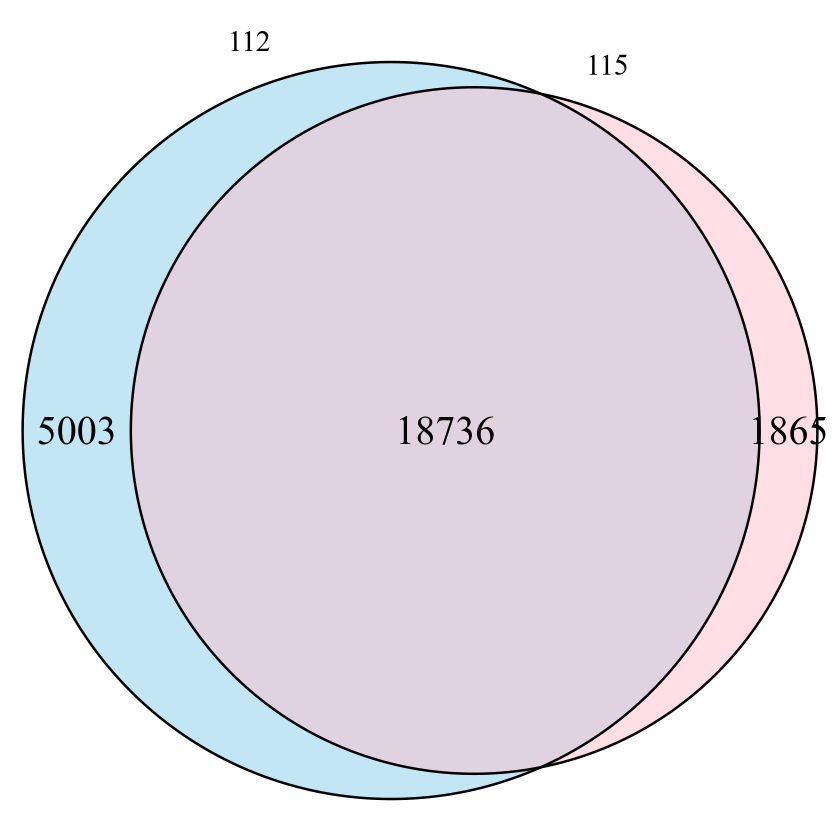

In [120]:
venn.plot

In [66]:
V112.genes$found=TRUE
V115.genes$found=TRUE

mergedDT=merge(V112.genes, V115.genes, by = "gene_id", all = TRUE)

In [68]:
mergedDT$found.x[ is.na(mergedDT$found.x)]=FALSE
mergedDT$found.y[ is.na(mergedDT$found.y)]=FALSE

In [71]:
mergedDTproblem=mergedDT[ (! mergedDT$found.x )|(! mergedDT$found.y ),]

In [73]:
mergedDTproblem$gene_name=mergedDTproblem$gene_name.x

In [74]:
mergedDTproblem$gene_name[ is.na(mergedDTproblem$gene_name)]= mergedDTproblem$gene_name.y[is.na(mergedDTproblem$gene_name)]

In [78]:
gene_names_table=table(mergedDTproblem$gene_name)

In [85]:
gene_names_DF=data.frame(genename=names(gene_names_table), count=gene_names_table)
gene_names_DF=gene_names_DF[ gene_names_DF$count.Freq<10,]

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


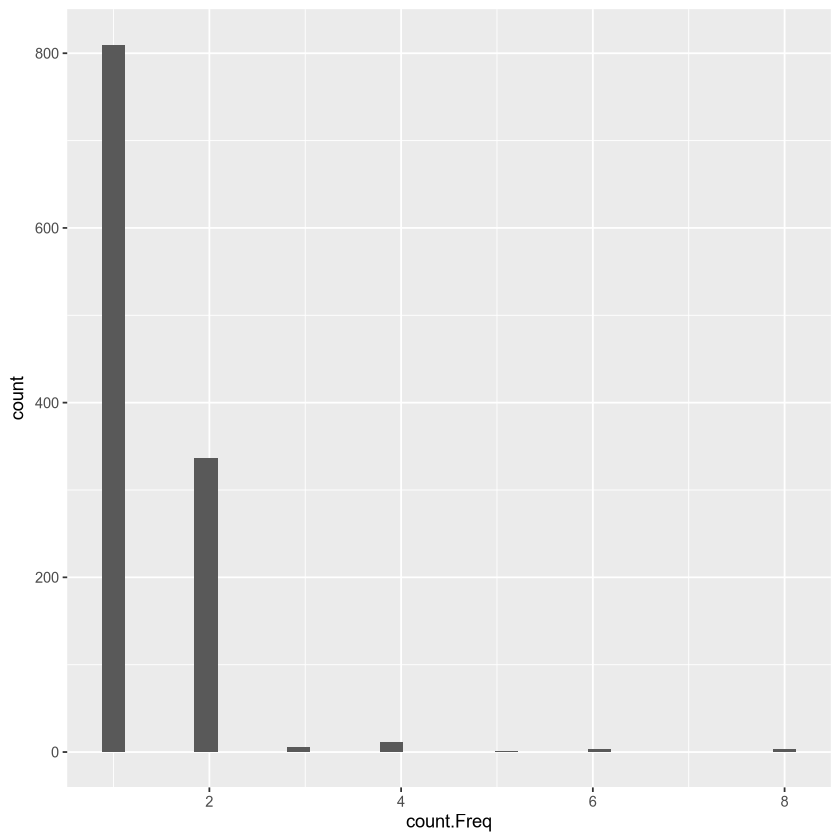

In [86]:
ggplot(gene_names_DF, aes(x=count.Freq))+geom_histogram()

In [90]:
mergedDTproblemBIG=mergedDTproblem[ mergedDTproblem$gene_name %in% gene_names_DF$genename[ gene_names_DF$count.Freq==2],]

In [92]:
mergedDTproblemBIG=mergedDTproblemBIG[ order(mergedDTproblemBIG$gene_name),]

In [ ]:
mergedDTproblemBIG

In [95]:
TMP.GTF=import.gff("~/data/lambda/data/keySpecies/Bos_taurus.ARS-UCD2.0.115.gtf")

In [108]:
probeGR=GRanges(seqnames = c("11"), ranges = IRanges(start = 5467324, end=5493545))

In [109]:
probeGR

GRanges object with 1 range and 0 metadata columns:
      seqnames          ranges strand
         <Rle>       <IRanges>  <Rle>
  [1]       11 5467324-5493545      *
  -------
  seqinfo: 1 sequence from an unspecified genome; no seqlengths

In [110]:
TMP.GTF_subset=subsetByOverlaps(TMP.GTF, probeGR)

In [112]:
TMP.GTF_subset

GRanges object with 48 ranges and 21 metadata columns:
       seqnames          ranges strand |   source            type     score
          <Rle>       <IRanges>  <Rle> | <factor>        <factor> <numeric>
   [1]       11 5493519-5522943      - |  ensembl gene                   NA
   [2]       11 5493519-5520350      - |  ensembl transcript             NA
   [3]       11 5493519-5493714      - |  ensembl exon                   NA
   [4]       11 5493519-5493598      - |  ensembl three_prime_utr        NA
   [5]       11 5484563-5491791      - |  ensembl gene                   NA
   ...      ...             ...    ... .      ...             ...       ...
  [44]       11 5490161-5491017      - |  ensembl            exon        NA
  [45]       11 5483300-5483422      - |  ensembl            exon        NA
  [46]       11 5482480-5482641      - |  ensembl            exon        NA
  [47]       11 5481379-5481580      - |  ensembl            exon        NA
  [48]       11 5478378-5479690  

In [113]:
TMP.GTF_subset[ TMP.GTF_subset$type=="transcript"]

GRanges object with 9 ranges and 21 metadata columns:
      seqnames          ranges strand |   source       type     score     phase
         <Rle>       <IRanges>  <Rle> | <factor>   <factor> <numeric> <integer>
  [1]       11 5493519-5520350      - |  ensembl transcript        NA      <NA>
  [2]       11 5484563-5491791      - |  ensembl transcript        NA      <NA>
  [3]       11 5485471-5491791      - |  ensembl transcript        NA      <NA>
  [4]       11 5447116-5468958      + |  ensembl transcript        NA      <NA>
  [5]       11 5459549-5490851      - |  ensembl transcript        NA      <NA>
  [6]       11 5459549-5490851      - |  ensembl transcript        NA      <NA>
  [7]       11 5462876-5490988      - |  ensembl transcript        NA      <NA>
  [8]       11 5468104-5490851      - |  ensembl transcript        NA      <NA>
  [9]       11 5478378-5491017      - |  ensembl transcript        NA      <NA>
                 gene_id gene_version   gene_name gene_source   ge

In [121]:
for (i in 2:nrow(KeySpDF)){
    martid = KeySpDF$HomologueTable[i]
    scientific_name= KeySpDF$ScientificName[i]
    s_name=martid
    if (nchar(s_name)==0) s_name="hsapiens"
    message(s_name)
    queryTxt=sprintf('SELECT DISTINCT gene_stable_id AS ensembl_gene_id, homology_gene_stable_id AS homolog FROM entrez_homology WHERE species="homo_sapiens" AND homology_species="%s" AND homology_gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="%s" AND gene_biotype="protein_coding") AND homology_identity>65', scientific_name, s_name)
    message(queryTxt)
    queryTxt=sprintf('SELECT DISTINCT gene_stable_id AS homolog, homology_gene_stable_id AS ensembl_gene_id FROM entrez_homology WHERE homology_species="homo_sapiens" AND species="%s" AND gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="%s" AND gene_biotype="protein_coding") AND homology_identity>65', scientific_name, s_name)
    message(queryTxt)
    message("\n\n\n-----\n")
}

mmusculus

SELECT DISTINCT gene_stable_id AS ensembl_gene_id, homology_gene_stable_id AS homolog FROM entrez_homology WHERE species="homo_sapiens" AND homology_species="mus_musculus" AND homology_gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="mmusculus" AND gene_biotype="protein_coding") AND homology_identity>65

SELECT DISTINCT gene_stable_id AS homolog, homology_gene_stable_id AS ensembl_gene_id FROM entrez_homology WHERE homology_species="homo_sapiens" AND species="mus_musculus" AND gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="mmusculus" AND gene_biotype="protein_coding") AND homology_identity>65




-----


clfamiliaris

SELECT DISTINCT gene_stable_id AS ensembl_gene_id, homology_gene_stable_id AS homolog FROM entrez_homology WHERE species="homo_sapiens" AND homology_species="canis_lupus_familiaris" AND homology_gene_stable_id IN (SELECT gene_id FROM gene_transcripts WHERE specie="clfamiliaris" AND gene_biotype="protein_coding") AND h

In [6]:
paste0(KeySpDF$ScientificName, collapse ='", ')

[1] "homo_sapiens\", mus_musculus\", canis_lupus_familiaris\", felis_catus\", bos_taurus\", camelus_dromedarius\", loxodonta_africana\", sus_scrofa\", balaenoptera_musculus"

# Checking key species HMM crosshits

In [2]:
HMMkeySpecieCrossHitsDF=dbGetQuery(mydbRO,"SELECT * FROM HMMkeySpecieCrossHits")

In [5]:
head(HMMkeySpecieCrossHitsDF)

,HMM,hit,specie,Evalue,score,bias
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,ENSG00000000003,ENSG00000156298,hsapiens,2.1e-101,337.6,5.5
2,ENSG00000000005,ENSG00000136110,hsapiens,4.7e-60,202.2,0.0
3,ENSG00000000938,ENSG00000010810,hsapiens,9.4e-279,924.6,0.0
4,ENSG00000000938,ENSG00000176105,hsapiens,3.6e-274,909.5,0.0
5,ENSG00000000938,ENSG00000197122,hsapiens,8.3e-262,868.7,0.0
6,ENSG00000000938,ENSG00000101336,hsapiens,1.3e-209,696.4,0.0


In [4]:
any(HMMkeySpecieCrossHitsDF$HMM == HMMkeySpecieCrossHitsDF$hit)

[1] FALSE

In [37]:
HMMkeySpecieCrossHitsDFraw=NULL
for (sp in c("hsapiens", relevantSpecies)){
    message(sp)
    SpecieOutDir=paste0(OutputDir, "HMMsKeySpeciesResults/", sp,"/")
    HMMouts=list.files(path = SpecieOutDir, pattern = paste0("*.hmm.out"), full.names = TRUE)
    specieDTtmp=NULL
    for ( i in 1:length(HMMouts)){
        if (i %% 1000 == 0){
            message(paste("\t", i,"/",length(HMMouts)))
        }
        HMMfname=HMMouts[i]
        #message(HMMfname)
        HMM.DT=readHMMout(HMMfname)
        if (!is.null(HMM.DT)){
            #HMM.DT=HMM.DT[ HMM.DT$score >= max(HMM.DT$score)*minHMMscoreRatioKeySpecies, ]
            specieDTtmp=addToDF(specieDTtmp, HMM.DT)
        }
    }
    specieDTtmp=renameDFcolumn(specieDTtmp, "targetname", "hit")
    specieDTtmp=renameDFcolumn(specieDTtmp, "queryname", "HMM")
    specieDTtmp$specie=sp
    specieDTtmp=specieDTtmp[, c("HMM", "hit", "specie", "Evalue", "score", "bias")]
    specieDTtmp$HMM=str_remove_all(specieDTtmp$HMM, pattern = "\\.faa\\.MSA")
    HMMkeySpecieCrossHitsDFraw=addToDF(HMMkeySpecieCrossHitsDFraw, specieDTtmp)
}

hsapiens

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 / 9952

	 9000 / 9952

mmusculus

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 / 9952

	 9000 / 9952

clfamiliaris

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 / 9952

	 9000 / 9952

fcatus

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 / 9952

	 9000 / 9952

btaurus

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 / 9952

	 9000 / 9952

cdromedarius

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 / 9952

	 9000 / 9952

lafricana

	 1000 / 9952

	 2000 / 9952

	 3000 / 9952

	 4000 / 9952

	 5000 / 9952

	 6000 / 9952

	 7000 / 9952

	 8000 /

In [38]:
getWellDefined=function(inDF){
    badHMMs=inDF$HMM[ inDF$HMM!=inDF$hit]
    return(inDF[ ! (inDF$HMM %in% badHMMs),])
}

getIllDefined=function(inDF){
    badHMMs=inDF$HMM[ inDF$HMM!=inDF$hit]
    return(inDF[ (inDF$HMM %in% badHMMs),])
}


In [39]:
HMMkeySpecieCrossHitsDFraw=HMMkeySpecieCrossHitsDFraw %>% group_by(HMM, specie) %>% mutate(maxscore=max(score), minE=min(Evalue)) %>% ungroup()
tmpout=getWellDefined(HMMkeySpecieCrossHitsDFraw)
length(unique(tmpout$HMM))

[1] 2348

In [40]:
tmpBad=getIllDefined(HMMkeySpecieCrossHitsDFraw)

In [41]:
tmpBad %>% filter(HMM!=hit) %>% mutate(scoreRatio=score/maxscore) %>% group_by(specie) %>% 
            summarise(numHMMs=length(unique(HMM)), minscoreRatio=min(scoreRatio), maxscoreRatio=max(scoreRatio)) 

specie,numHMMs,minscoreRatio,maxscoreRatio
<chr>,<int>,<dbl>,<dbl>
bmusculus,7497,0.002396812,1
btaurus,7498,0.002134657,1
cdromedarius,7498,0.002361869,1
clfamiliaris,7514,0.002360521,1
fcatus,7494,0.002215395,1
hsapiens,7506,0.002071499,1
lafricana,7478,0.002570885,1
mmusculus,7514,0.002209815,1
sscrofa,7496,0.002396516,1


In [42]:
scoreRatioDF=tmpBad %>% filter(HMM!=hit) %>% mutate(scoreRatio=score/maxscore)


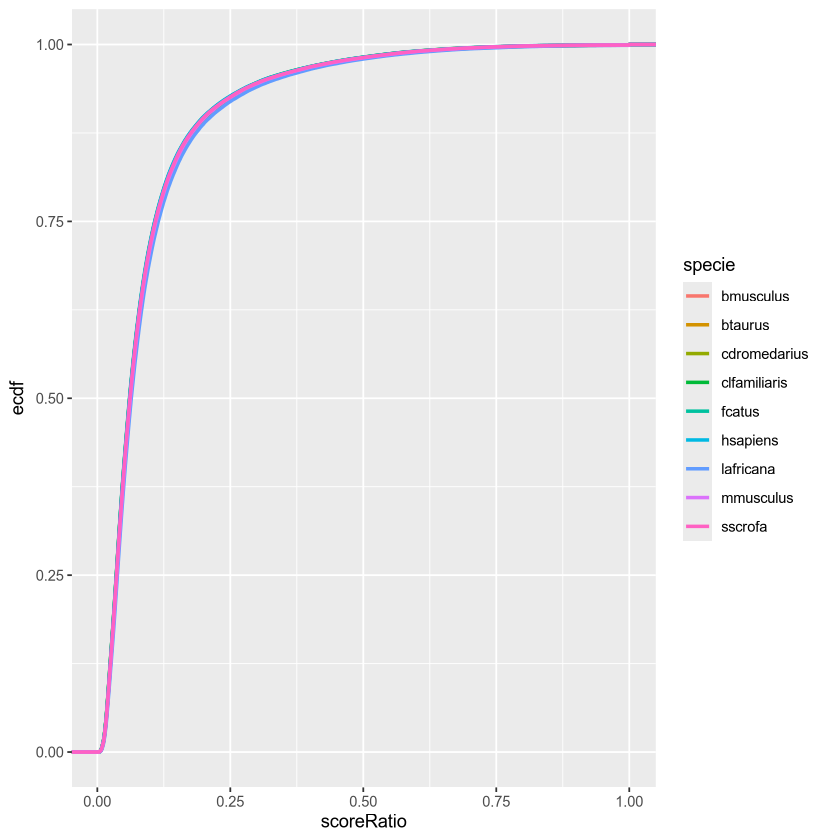

In [43]:
ggplot(scoreRatioDF, aes(x=scoreRatio, fill=specie, color=specie))+stat_ecdf(geom = "step", size=1)

In [64]:
resultsDF=NULL
HMMkeySpecieCrossHitsDFraw$scoreRatio= HMMkeySpecieCrossHitsDFraw$score/ HMMkeySpecieCrossHitsDFraw$maxscore
for (thld in seq(from = 0.1, to = 1, by=0.05)){
    subsetDF=HMMkeySpecieCrossHitsDFraw[ HMMkeySpecieCrossHitsDFraw$scoreRatio >= thld, ]
    tmpBad=getIllDefined(subsetDF)
    tmpGood=getWellDefined(subsetDF)
    nummatches=length(unique(tmpGood$HMM))
    numerrors=length(unique(tmpBad$HMM))
    tmpDF=data.frame(thld=thld, value= c(nummatches, numerrors), type= c("nummatches", "numerrors") )
    resultsDF=addToDF(resultsDF, tmpDF)
}

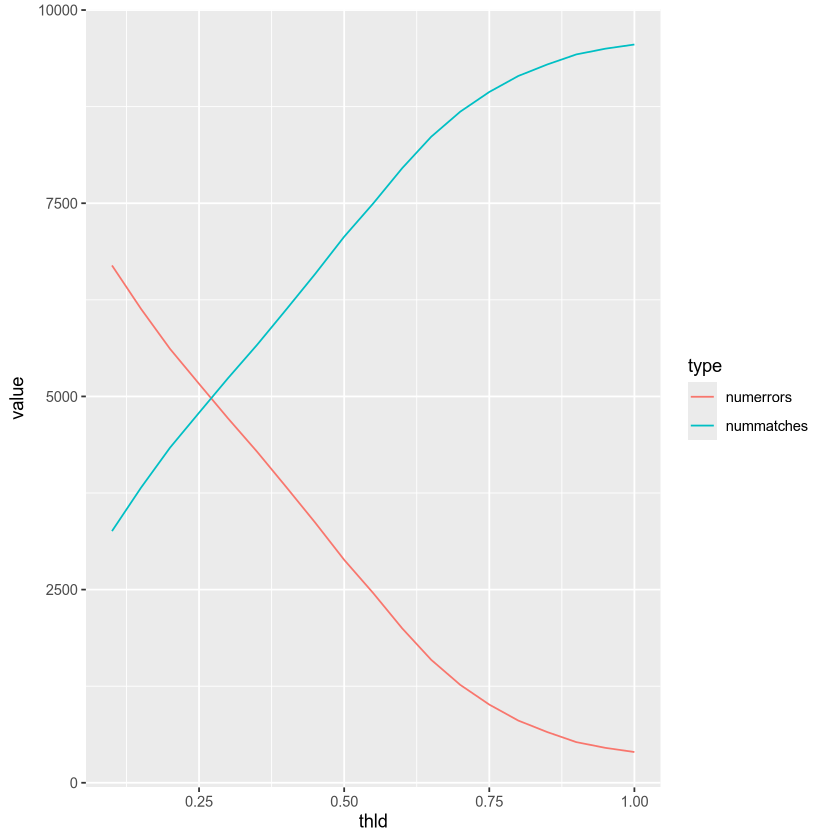

In [65]:
ggplot(resultsDF, aes(x=thld, y=value, color=type, fill=type))+geom_line()

In [66]:
subsetDF=HMMkeySpecieCrossHitsDFraw[ HMMkeySpecieCrossHitsDFraw$scoreRatio > 0.9, ]

In [67]:
subsetDF %>% filter(HMM!=hit)

HMM,hit,specie,Evalue,score,bias,maxscore,minE,scoreRatio
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000002834,ENSG00000183091,hsapiens,2.0e-302,996.7,373.8,996.7,2.0e-302,1.0000000
ENSG00000008128,ENSG00000248333,hsapiens,0.0e+00,1763.4,62.2,1763.4,0.0e+00,1.0000000
ENSG00000065371,ENSG00000114547,hsapiens,5.8e-136,449.8,0.0,452.4,8.8e-137,0.9942529
ENSG00000072062,ENSG00000142875,hsapiens,1.3e-229,760.2,1.7,833.0,9.4e-252,0.9126050
ENSG00000072401,ENSG00000131508,hsapiens,2.9e-96,318.3,0.2,352.7,7.4e-107,0.9024667
ENSG00000078114,ENSG00000183091,hsapiens,0.0e+00,2508.7,450.9,2508.7,0.0e+00,1.0000000
ENSG00000078369,ENSG00000172354,hsapiens,9.4e-220,727.5,8.8,799.3,1.4e-241,0.9101714
ENSG00000079332,ENSG00000152700,hsapiens,1.9e-127,421.7,0.0,459.7,4.4e-139,0.9173374
ENSG00000079974,ENSG00000144134,hsapiens,7.7e-148,489.1,1.7,489.5,5.8e-148,0.9991828


In [44]:
BadGenesDF=tmpBad %>% filter(HMM!=hit) %>% mutate(scoreRatio=score/maxscore) %>% group_by(HMM) %>% 
                summarise(numSpecies=length(unique(specie)), minscoreRatio=min(scoreRatio), maxscoreRatio=max(scoreRatio)) 

In [ ]:
BadGenesDF

In [45]:
HMMkeySpecieCrossHitsDFraw[ HMMkeySpecieCrossHitsDFraw$HMM=="ENSG00000000005", ]

HMM,hit,specie,Evalue,score,bias,maxscore,minE
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000000005,ENSG00000000005,hsapiens,6.7e-231,763.5,8.9,763.5,6.7e-231
ENSG00000000005,ENSG00000136110,hsapiens,4.7e-60,202.2,0.0,763.5,6.7e-231
ENSG00000000005,ENSG00000000005,mmusculus,4.8e-230,760.7,8.2,760.7,4.8e-230
ENSG00000000005,ENSG00000136110,mmusculus,5.2e-62,208.7,0.0,760.7,4.8e-230
ENSG00000000005,ENSG00000000005,clfamiliaris,1.7e-231,765.5,8.7,765.5,1.7e-231
ENSG00000000005,ENSG00000136110,clfamiliaris,4.1e-59,199.2,1.2,765.5,1.7e-231
ENSG00000000005,ENSG00000000005,fcatus,1.5e-231,765.6,8.6,765.6,1.5e-231
ENSG00000000005,ENSG00000136110,fcatus,3.6e-59,199.3,1.3,765.6,1.5e-231
ENSG00000000005,ENSG00000000005,btaurus,9.9e-230,759.7,8.9,759.7,9.9e-230


In [2]:
sp="fcatus"
chrname="B3"
queryTxt=sprintf('SELECT * FROM keySpeciesGenomicCoords WHERE specie="%s" 
                     AND seqnames="%s" AND type="CDS" AND ( ( specie_gene_id IN 
                     (SELECT DISTINCT ensembl_gene_id FROM HomologyBijectiveWellDefined) )
                    OR 
                     ( specie_gene_id IN  (SELECT DISTINCT homolog FROM HomologyBijectiveWellDefined) ))', sp, chrname) 
        CDS.GR=GRanges(dbGetQuery(mydbRO, queryTxt))

In [4]:
'ENSFCTG00005013171' %in% CDS.GR$specie_gene_id

[1] TRUE

In [2]:
tmpdf=dbGetQuery(mydbRO, "SELECT DISTINCT ensembl_gene_id FROM HomologyBijectiveWellDefined")

In [3]:
c('ENSG00000100554', "ENSG00000151131", "ENSG00000100554", "ENSG00000170500") %in% tmpdf$ensembl_gene_id

[1] TRUE TRUE TRUE TRUE

In [14]:
dbGetQuery(mydbRO, "SELECT * FROM HMMkeySpecieCrossHitsCount WHERE HMM='ENSG00000170500'")

HMM,specie,C
<chr>,<chr>,<int>
ENSG00000170500,btaurus,2


In [2]:
tmpdf=dbGetQuery(mydbRO, "SELECT DISTINCT ensembl_gene_id FROM positively_ided_using_context")

In [3]:
geneNamesDF=dbGetQuery(mydbRO, "SELECT * FROM AllSpeciesFoundGeneNames5MB")

In [4]:
tmpDF2=geneNamesDF %>% group_by(ensembl_gene_id) %>% summarize(num_genomes=n())

In [6]:
tmpDF2[ tmpDF2$ensembl_gene_id %in% c('ENSG00000100554', "ENSG00000151131", "ENSG00000170500", "ENSG00000091651"), ]

ensembl_gene_id,num_genomes
<chr>,<int>
ENSG00000091651,172
ENSG00000100554,180
ENSG00000151131,175
ENSG00000170500,159


# Analysis of the families

In [2]:
library(latex2exp)
library(fpc)

In [3]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM HMMstats5MB'
HMMs=dbGetQuery(mydbRO, queryTxt)[[1]]
interestingGenes2=NULL



In [4]:
length(HMMs)

[1] 9518

In [8]:
queryTxt='SELECT * FROM HMMstats5MB'
HMMstatsALL.DT=as.data.table(dbGetQuery(mydbRO, queryTxt))


In [ ]:
options(repr.plot.width = 20, repr.plot.height = 16)

In [290]:
analyzeTheFamilies<-function(inDF, incolX=(inDF$DSlen)/median(inDF$DSlen),
                             incolY=2*(inDF$asRMSKlen-inDF$sRMSKlen)/inDF$DSlen, colYthreshold=0.75, Ymask=inDF$DSlen<(4000), epsilon=0.2,
                            minOddsRatio=2, minMeanDSforTopCluster=25000, MinPts = 10, verbose=FALSE){
    incolY[ Ymask] =0
    inDF$colX=incolX
    inDF$colY=incolY
    inDF=inDF[ !(is.na(incolX) | is.na(incolY)) ,]

    Dbscan_cl=dbscan(inDF[, c("colX", "colY")], eps = epsilon, MinPts = MinPts) 
    inDF$cluster=Dbscan_cl$cluster
    clustersNormDF=inDF %>% group_by(cluster) %>% summarize(numGenomes=n(), numFamilies=length(unique(familyID)), meanColY=mean(colY),
                                                           meanColX=mean(colX), meanDSlen=mean(DSlen))

    if (all(clustersNormDF$meanColY<colYthreshold)){
        if (verbose) message('all(clustersNormDF$meanColY<colYthreshold)')
        return(FALSE)
    }
    if (all(clustersNormDF$meanDSlen<minMeanDSforTopCluster)){
        if (verbose) message('all(clustersNormDF$meanDSlen<minMeanDSforTopCluster)')
        return(FALSE)
    }
    interestingGene=TRUE
    # 1) there should 2 or more clusters. 

    if (nrow(clustersNormDF)==1){
        if (verbose) message('nrow(clustersNormDF)==1')
        return(FALSE)
    }
    # probability that families are randomly distributed across clusters
    familyNormDF=inDF %>% group_by(familyID) %>% summarize(numGenomes=n(), weight=numGenomes/nrow(inDF), .groups="drop_last")
    familyVSclusterStat=inDF %>% group_by(familyID, cluster) %>% summarize(numGenomes=n(), .groups="drop_last")

    for (clusterID in clustersNormDF$cluster){
        familyNormDF[[paste0("cluster", clusterID,"weight")]]=0.0
    }
    
    for ( i in 1:nrow(familyNormDF)){
        famID=familyNormDF$familyID[i]
        familyTMP=inDF[ inDF$familyID==famID,]
        for (j in 1:nrow(clustersNormDF)){
            clustersNormDFtmp=clustersNormDF[ j,]
            familyClusterTMP=familyTMP[ familyTMP$cluster==clustersNormDFtmp$cluster,]
            tmpColname=paste0("cluster", clustersNormDFtmp$cluster,"weight")
            familyNormDF[i, colnames(familyNormDF)==tmpColname]=nrow(familyClusterTMP)/clustersNormDFtmp$numGenomes
        }
    }

    for ( colnum in which(grepl(pattern = "cluster\\d+weight$", colnames(familyNormDF))) ){
        familyNormDF[, ncol(familyNormDF)+1]=familyNormDF[, colnum]/familyNormDF$weight
        tmpColnames=colnames(familyNormDF)
        tmpColnames[ncol(familyNormDF)]=paste0(colnames(familyNormDF)[colnum], "ratio", collapse = "")
        colnames(familyNormDF)<-tmpColnames
    }
    #print(familyNormDF)

    # 2) At least one of the families should have more that 2x weight (odds) ratio in one of the clusters
    tmpDF=as.data.frame(familyNormDF[ ,grepl(pattern = "familyID|cluster\\d+weightratio", x = colnames(familyNormDF))]) %>% 
    rowwise() %>% filter(any(c_across(starts_with('cl'))>=minOddsRatio)) 
    
    if (nrow(tmpDF)==0){
        if (verbose) message('nrow(tmpDF)==0')
        return(FALSE)
    }
    
    overreppresentedFamiliesDF= data.frame(matrix(ncol = 2, nrow = 0))
    colnames(overreppresentedFamiliesDF) <- c("familyID", "cluster")
    #print(overreppresentedFamiliesDF)
    for (i in 1:nrow(tmpDF)){
        familyID=tmpDF$familyID[i]
        tmpDF2=tmpDF[i,grepl(pattern = "cluster\\d+weight", x = colnames(tmpDF))]
        clusterNames=colnames(tmpDF2)[tmpDF2[1,]>=minOddsRatio]
        clusterNames=str_remove_all(string = clusterNames, pattern = "[a-z]")
        for (clname in clusterNames){
            overreppresentedFamiliesDF[nrow(overreppresentedFamiliesDF)+1, ]=c(familyID, as.integer(clname))
        }
    }
    
    # 3) That family should have at least 50% of the members in that cluster
    fractionOfOverreprFamiliesInCorrCluster=NULL
    for (i in 1:nrow(overreppresentedFamiliesDF)){
        familyID=overreppresentedFamiliesDF$familyID[i]
        cluster=overreppresentedFamiliesDF$cluster[i]
        FamGenomesInCluster=familyVSclusterStat$numGenomes[ familyVSclusterStat$familyID==familyID & familyVSclusterStat$cluster==cluster]
        numGenomesInFamily=familyNormDF$numGenomes[ familyNormDF$familyID == familyID]
        fractionOfOverreprFamiliesInCorrCluster=addToVec(fractionOfOverreprFamiliesInCorrCluster, FamGenomesInCluster/numGenomesInFamily)
    }
    #print(fractionOfOverreprFamiliesInCorrCluster)
    if (!any(fractionOfOverreprFamiliesInCorrCluster>0.5)){
        if (verbose) message('!any(fractionOfOverreprFamiliesInCorrCluster>0.5)')
        return(FALSE)
    }
    return(TRUE)
}

In [296]:
#c('ENSG00000100554', "ENSG00000151131", "ENSG00000170500", "ENSG00000091651")
HMMid='ENSG00000170500'
HMMstatsDT=HMMstatsALL.DT[ HMMstatsALL.DT$ensembl_gene_id==HMMid,]

statsDFtmp = HMMstatsDT %>% group_by(ensembl_gene_id, familyID) %>% filter(n()>2)
analyzeTheFamilies(statsDFtmp, verbose = TRUE)


all(clustersNormDF$meanColY<colYthreshold)



[1] FALSE

In [300]:
analyzeTheFamilies(statsDFtmp, incolY=2*(statsDFtmp$asRMSKlen50K-statsDFtmp$sRMSKlen50K)/50000, 
                 epsilon = 0.2, verbose = TRUE)

all(clustersNormDF$meanColY<colYthreshold)



[1] FALSE

In [272]:
length(unique(HMMstatsDT$familyName))

[1] 48

In [273]:
#mycolors=c('#000000', '#FF0000', '#00FF00', '#0000FF')
mycolors=c('#FF0000', '#0000FF', '#FFFF00', '#00FF00', '#FF00FF', '#FF8000', '#00FFFF', '#000000')
myfills=c('#FF0000', '#0000FF', '#FFFF00', '#00FF00', '#FF00FF', '#FF8000', '#00FFFF', '#000000', '#FFFFFF')

In [274]:
length(mycolors)*length(myfills)*5


[1] 360

In [275]:
visDF=expand.grid(color=mycolors, fill=myfills, shape=21:25)
visDF <- visDF[sample(nrow(visDF)),]


In [276]:
factor(HMMstatsDT$familyName)

[1] Muridae          Bovidae          Hominidae        Cebidae         
  [5] Muridae          Hominidae        Muridae          Canidae         
  [9] Equidae          Suidae           Bovidae          Bovidae         
 [13] Leporidae        Cebidae          Hominidae        Cheirogaleidae  
 [17] Bovidae          Hominidae        Cercopithecidae  Bovidae         
 [21] Hominidae        Cercopithecidae  Cercopithecidae  Cercopithecidae 
 [25] Camelidae        Bovidae          Ursidae          Phocidae        
 [29] Bovidae          Bovidae          Cercopithecidae  Physeteridae    
 [33] Equidae          Hominidae        Bovidae          Canidae         
 [37] Cercopithecidae  Cercopithecidae  Bovidae          Cricetidae      
 [41] Cricetidae       Rhinolophidae    Canidae          Herpestidae     
 [45] Felidae          Cercopithecidae  Hominidae        Muridae         
 [49] Phocoenidae      Cercopithecidae  Otariidae        Leporidae       
 [53] Mustelidae       Camelidae        Balaenopteridae  Muridae         
 [57] Canidae          Muridae          Delphinidae      Cercopithecidae 
 [61] Canidae          Ochotonidae      Megalonychidae   Muridae         
 [65] Equidae          Felidae          Bovidae          Sciuridae       
 [69] Suidae           Canidae          Felidae          Felidae         
 [73] Felidae          Felidae          Cervidae         Bovidae         
 [77] Bovidae          Mustelidae       Lemuridae        Dipodidae       
 [81] Rhinocerotidae   Equidae          Mustelidae       Phyllostomidae  
 [85] Felidae          Ursidae          Bovidae          Heteromyidae    
 [89] Felidae          Myrmecophagidae  Elephantidae     Cercopithecidae 
 [93] Ziphiidae        Physeteridae     Lorisidae        Cynocephalidae  
 [97] Felidae          Vespertilionidae Bovidae          Soricidae       
[101] Felidae          Eschrichtiidae   Balaenopteridae  Felidae         
[105] Balaenidae       Hominidae        Hominidae        Hominidae       
[109] Bovidae          Bovidae          Elephantidae     Manidae         
[113] Hippopotamidae   Muridae          Ochotonidae      Mustelidae      
[117] Dasypodidae      Bovidae          Bovidae          Leporidae       
[121] Cervidae         Camelidae        Rhinolophidae    Emballonuridae  
[125] Emballonuridae   Cricetidae       Delphinidae      Manidae         
[129] Cheirogaleidae   Lemuridae        Equidae          Bovidae         
[133] Sciuridae        Castoridae       Sciuridae        Cercopithecidae 
[137] Canidae          Canidae          Camelidae        Cebidae         
[141] Sciuridae        Sciuridae        Camelidae        Cricetidae      
[145] Tenrecidae       Sciuridae        Canidae          Muridae         
[149] Muridae          Mustelidae       Sciuridae        Cricetidae      
[153] Cricetidae       Muridae          Cervidae         Mustelidae      
[157] Delphinidae      Delphinidae      Cricetidae       Delphinidae     
[161] Balaenopteridae  Cricetidae       Erinaceidae      Vespertilionidae
[165] Delphinidae      Phocoenidae      Cervidae         Leporidae       
[169] Phocidae        
48 Levels: Balaenidae Balaenopteridae Bovidae Camelidae Canidae ... Ziphiidae

In [277]:
visDF$familyName=''
visDF$familyName[1:length(unique(HMMstatsDT$familyName))]=levels(factor(HMMstatsDT$familyName))
visDF=visDF[1:length(unique(HMMstatsDT$familyName)),]

In [278]:
colorList=as.list(setNames(as.character(visDF$color),visDF$familyName))


In [279]:
fillList=as.list(setNames(as.character(visDF$fill),visDF$familyName))


In [280]:
shapeList=as.list(setNames(visDF$shape,visDF$familyName))
shapeListClusters=list()
shapeListClusters[['0']]=NA
shapeListClusters[['1']]=0
shapeListClusters[['2']]=1
shapeListClusters[['3']]=2
shapeListClusters[['4']]=5
shapeListClusters[['5']]=6

In [281]:
as.integer(factor(HMMstatsDT$familyName))

[1] 31  3 25  7 31 25 31  5 18 44  3  3 27  7 25 10  3 25  8  3 25  8  8  8  4
 [26]  3 46 36  3  3  8 39 18 25  3  5  8  8  3 11 11 41  5 22 21  8 25 31 37  8
 [51] 35 27 32  4  2 31  5 31 14  8  5 34 30 31 18 21  3 42 44  5 21 21 21 21  9
 [76]  3  3 32 26 15 40 18 32 38 21 46  3 23 21 33 16  8 48 39 28 12 21 47  3 43
[101] 21 20  2 21  1 25 25 25  3  3 16 29 24 31 34 32 13  3  3 27  9  4 41 17 17
[126] 11 14 29 10 26 18  3 42  6 42  8  5  5  4  7 42 42  4 11 45 42  5 31 31 32
[151] 42 11 11 31  9 32 14 14 11 14  2 11 19 47 14 37  9 27 36

In [282]:
library(ggnewscale)


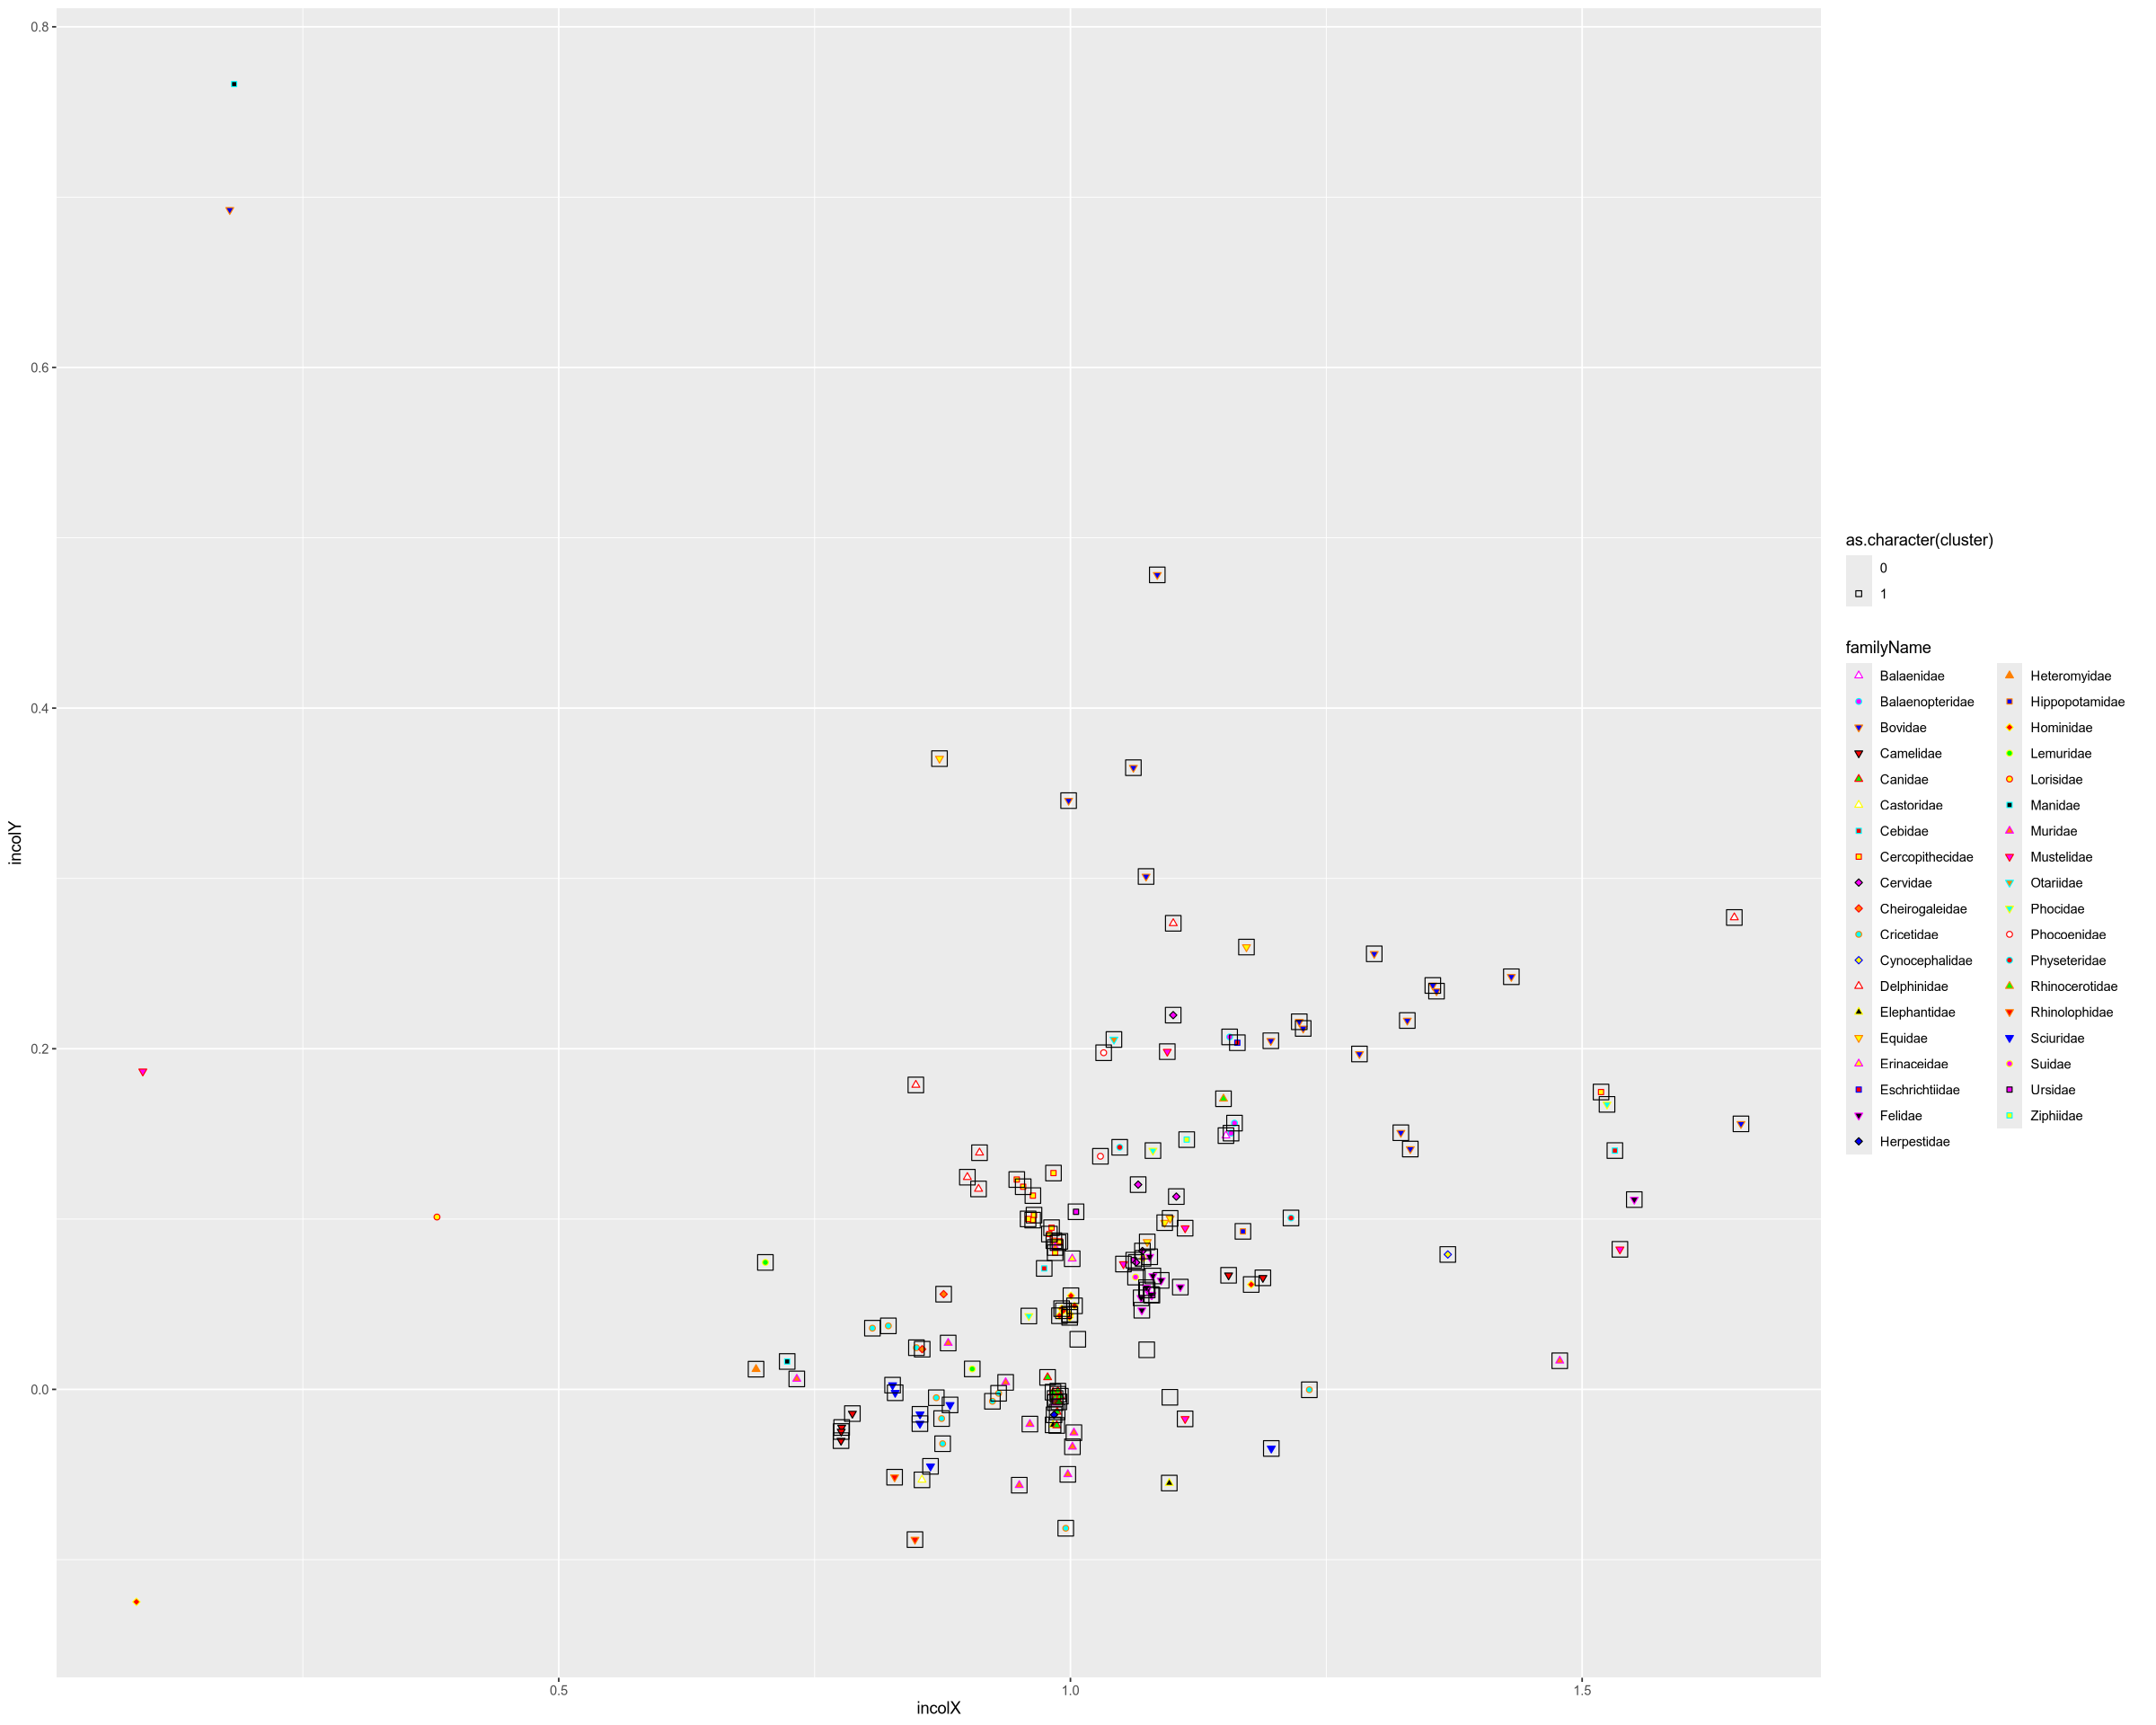

In [311]:
HMMstatsDT$incolX=HMMstatsDT$DSlen/median(HMMstatsDT$DSlen)#(HMMstatsDT$DSlen)^0.35
HMMstatsDT$incolY=2*(HMMstatsDT$asRMSKlen-HMMstatsDT$sRMSKlen)/HMMstatsDT$DSlen
colYthreshold=10
#Ymask=HMMstatsDT$incolX<(4000^0.35)
epsilon=0.2
minOddsRatio=2
minMeanXforTopCluster=(30000^0.35)
#HMMstatsDT$incolY[ Ymask] =0
HMMstatsDT=HMMstatsDT[ !(is.na(HMMstatsDT$incolX) | is.na(HMMstatsDT$incolY)) ,]

Dbscan_cl=dbscan(HMMstatsDT[, c("incolX", "incolY")], eps = epsilon, MinPts = 10) 
HMMstatsDT$cluster=Dbscan_cl$cluster

ggplot() + geom_point(data = HMMstatsDT, aes(y=incolY, x=incolX, color=familyName, fill=familyName, shape=familyName)) +
scale_shape_manual(values = shapeList)+
scale_colour_manual(values = colorList)+
scale_fill_manual(values = fillList) + # adding clusters
new_scale_colour()+new_scale_fill()+new_scale("shape")+
geom_point(data = HMMstatsDT, aes(y=incolY, x=incolX, shape=as.character(cluster), size=3))+
scale_shape_manual(values = shapeListClusters) + scale_size(guide = 'none')


In [305]:
HMMstatsDT[ HMMstatsDT$cluster==3,]

accession,ensembl_gene_id,geneName,singleGene,familyName,familyID,passedIndividualAnalysis,DSlen,GapLen,sRMSKlen,asRMSKlen,sRMSKlen10K,asRMSKlen10K,sRMSKlen50K,asRMSKlen50K,sRMSKlen100K,asRMSKlen100K,incolX,incolY,cluster
<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>


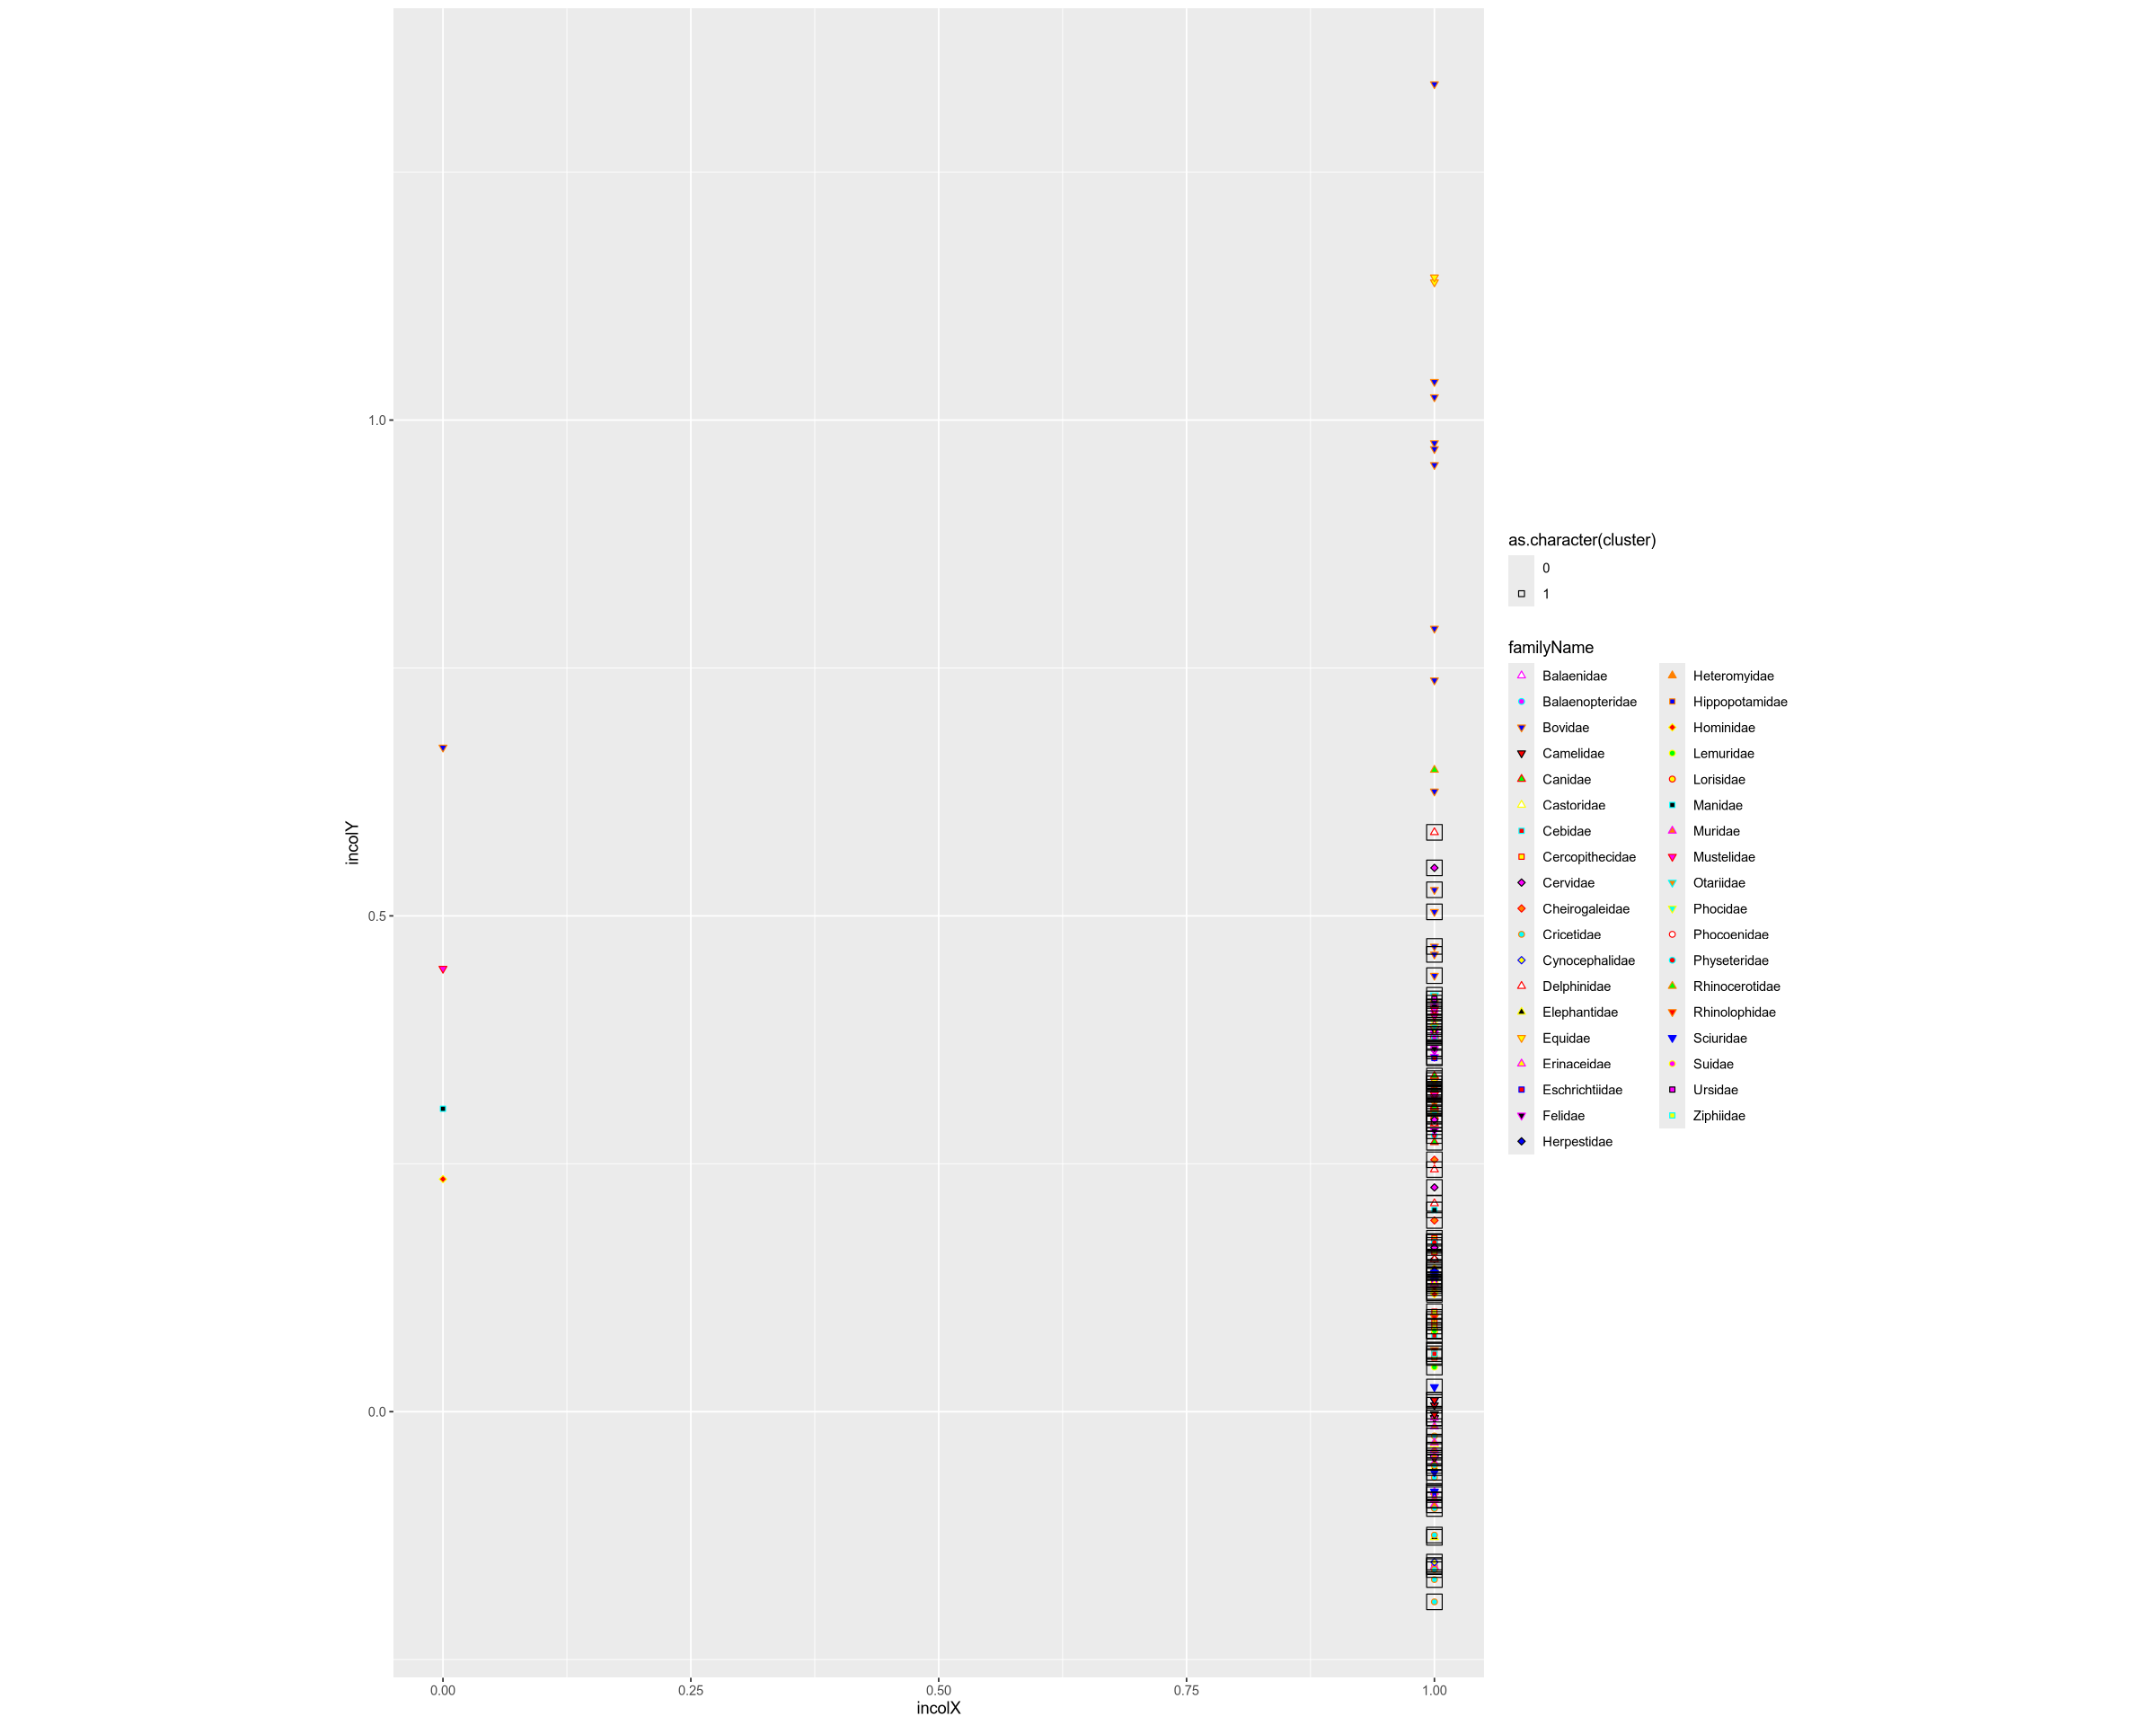

In [325]:
HMMstatsDT$incolX=as.integer(HMMstatsDT$DSlen>50000)#(HMMstatsDT$DSlen)^0.35
HMMstatsDT$incolY=2*(HMMstatsDT$asRMSKlen50K-HMMstatsDT$sRMSKlen50K)/50000#scale((HMMstatsDT$asRMSKlen50K-HMMstatsDT$sRMSKlen50K)/50000)#28*(HMMstatsDT$asRMSKlen50K-HMMstatsDT$sRMSKlen50K)/50000
colYthreshold=10
epsilon=0.1
minOddsRatio=2
HMMstatsDT=HMMstatsDT[ !(is.na(HMMstatsDT$incolX) | is.na(HMMstatsDT$incolY)) ,]

Dbscan_cl=dbscan(HMMstatsDT[, c("incolX", "incolY")], eps = epsilon, MinPts = 10) 
HMMstatsDT$cluster=Dbscan_cl$cluster

ggplot() + geom_point(data = HMMstatsDT, aes(y=incolY, x=incolX, color=familyName, fill=familyName, shape=familyName)) +
scale_shape_manual(values = shapeList)+
scale_colour_manual(values = colorList)+
scale_fill_manual(values = fillList) + # adding clusters
new_scale_colour()+new_scale_fill()+new_scale("shape")+
geom_point(data = HMMstatsDT, aes(y=incolY, x=incolX, shape=as.character(cluster), size=3))+
scale_shape_manual(values = shapeListClusters) + scale_size(guide = 'none') + coord_fixed()



In [316]:
HMMstatsDT[ HMMstatsDT$cluster==0,]

accession,ensembl_gene_id,geneName,singleGene,familyName,familyID,passedIndividualAnalysis,DSlen,GapLen,sRMSKlen,asRMSKlen,sRMSKlen10K,asRMSKlen10K,sRMSKlen50K,asRMSKlen50K,sRMSKlen100K,asRMSKlen100K,incolX,incolY,cluster
<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
GCA_022833125.2,ENSG00000170500,LONRF2,1,Hominidae,9604,1,15646,0,4102,3126,2022,2059,8233,14096,20103,28681,0,0.23452,0
GCF_000002305.2,ENSG00000170500,LONRF2,1,Equidae,9788,1,156197,629,26816,55739,205,5568,2779,31255,14053,43144,1,1.13904,0
GCF_002263795.3,ENSG00000170500,LONRF2,1,Bovidae,9895,1,178793,0,36208,67111,293,5699,8401,28145,17681,43328,1,0.78976,0
GCF_002742125.1,ENSG00000170500,LONRF2,1,Bovidae,9895,1,238070,0,46411,72191,764,5130,2764,18403,13433,34281,1,0.62556,0
GCF_002863925.1,ENSG00000170500,LONRF2,1,Equidae,9788,1,209920,0,42695,69953,205,5567,2734,31333,14403,43210,1,1.14396,0
GCF_003121395.1,ENSG00000170500,LONRF2,1,Bovidae,9895,1,192350,0,41566,70527,1786,4118,7543,31413,19150,45300,1,0.95480,0
GCF_003369695.1,ENSG00000170500,LONRF2,1,Bovidae,9895,1,232283,0,45895,75595,293,2066,3867,29831,15557,43331,1,1.03856,0
GCF_016772045.2,ENSG00000170500,LONRF2,1,Bovidae,9895,1,31982,0,764,11838,764,5130,2764,19510,13479,35197,0,0.66984,0
GCF_019923925.1,ENSG00000170500,LONRF2,1,Bovidae,9895,1,242536,0,53394,82153,1731,4068,8383,32803,18007,46099,1,0.97680,0


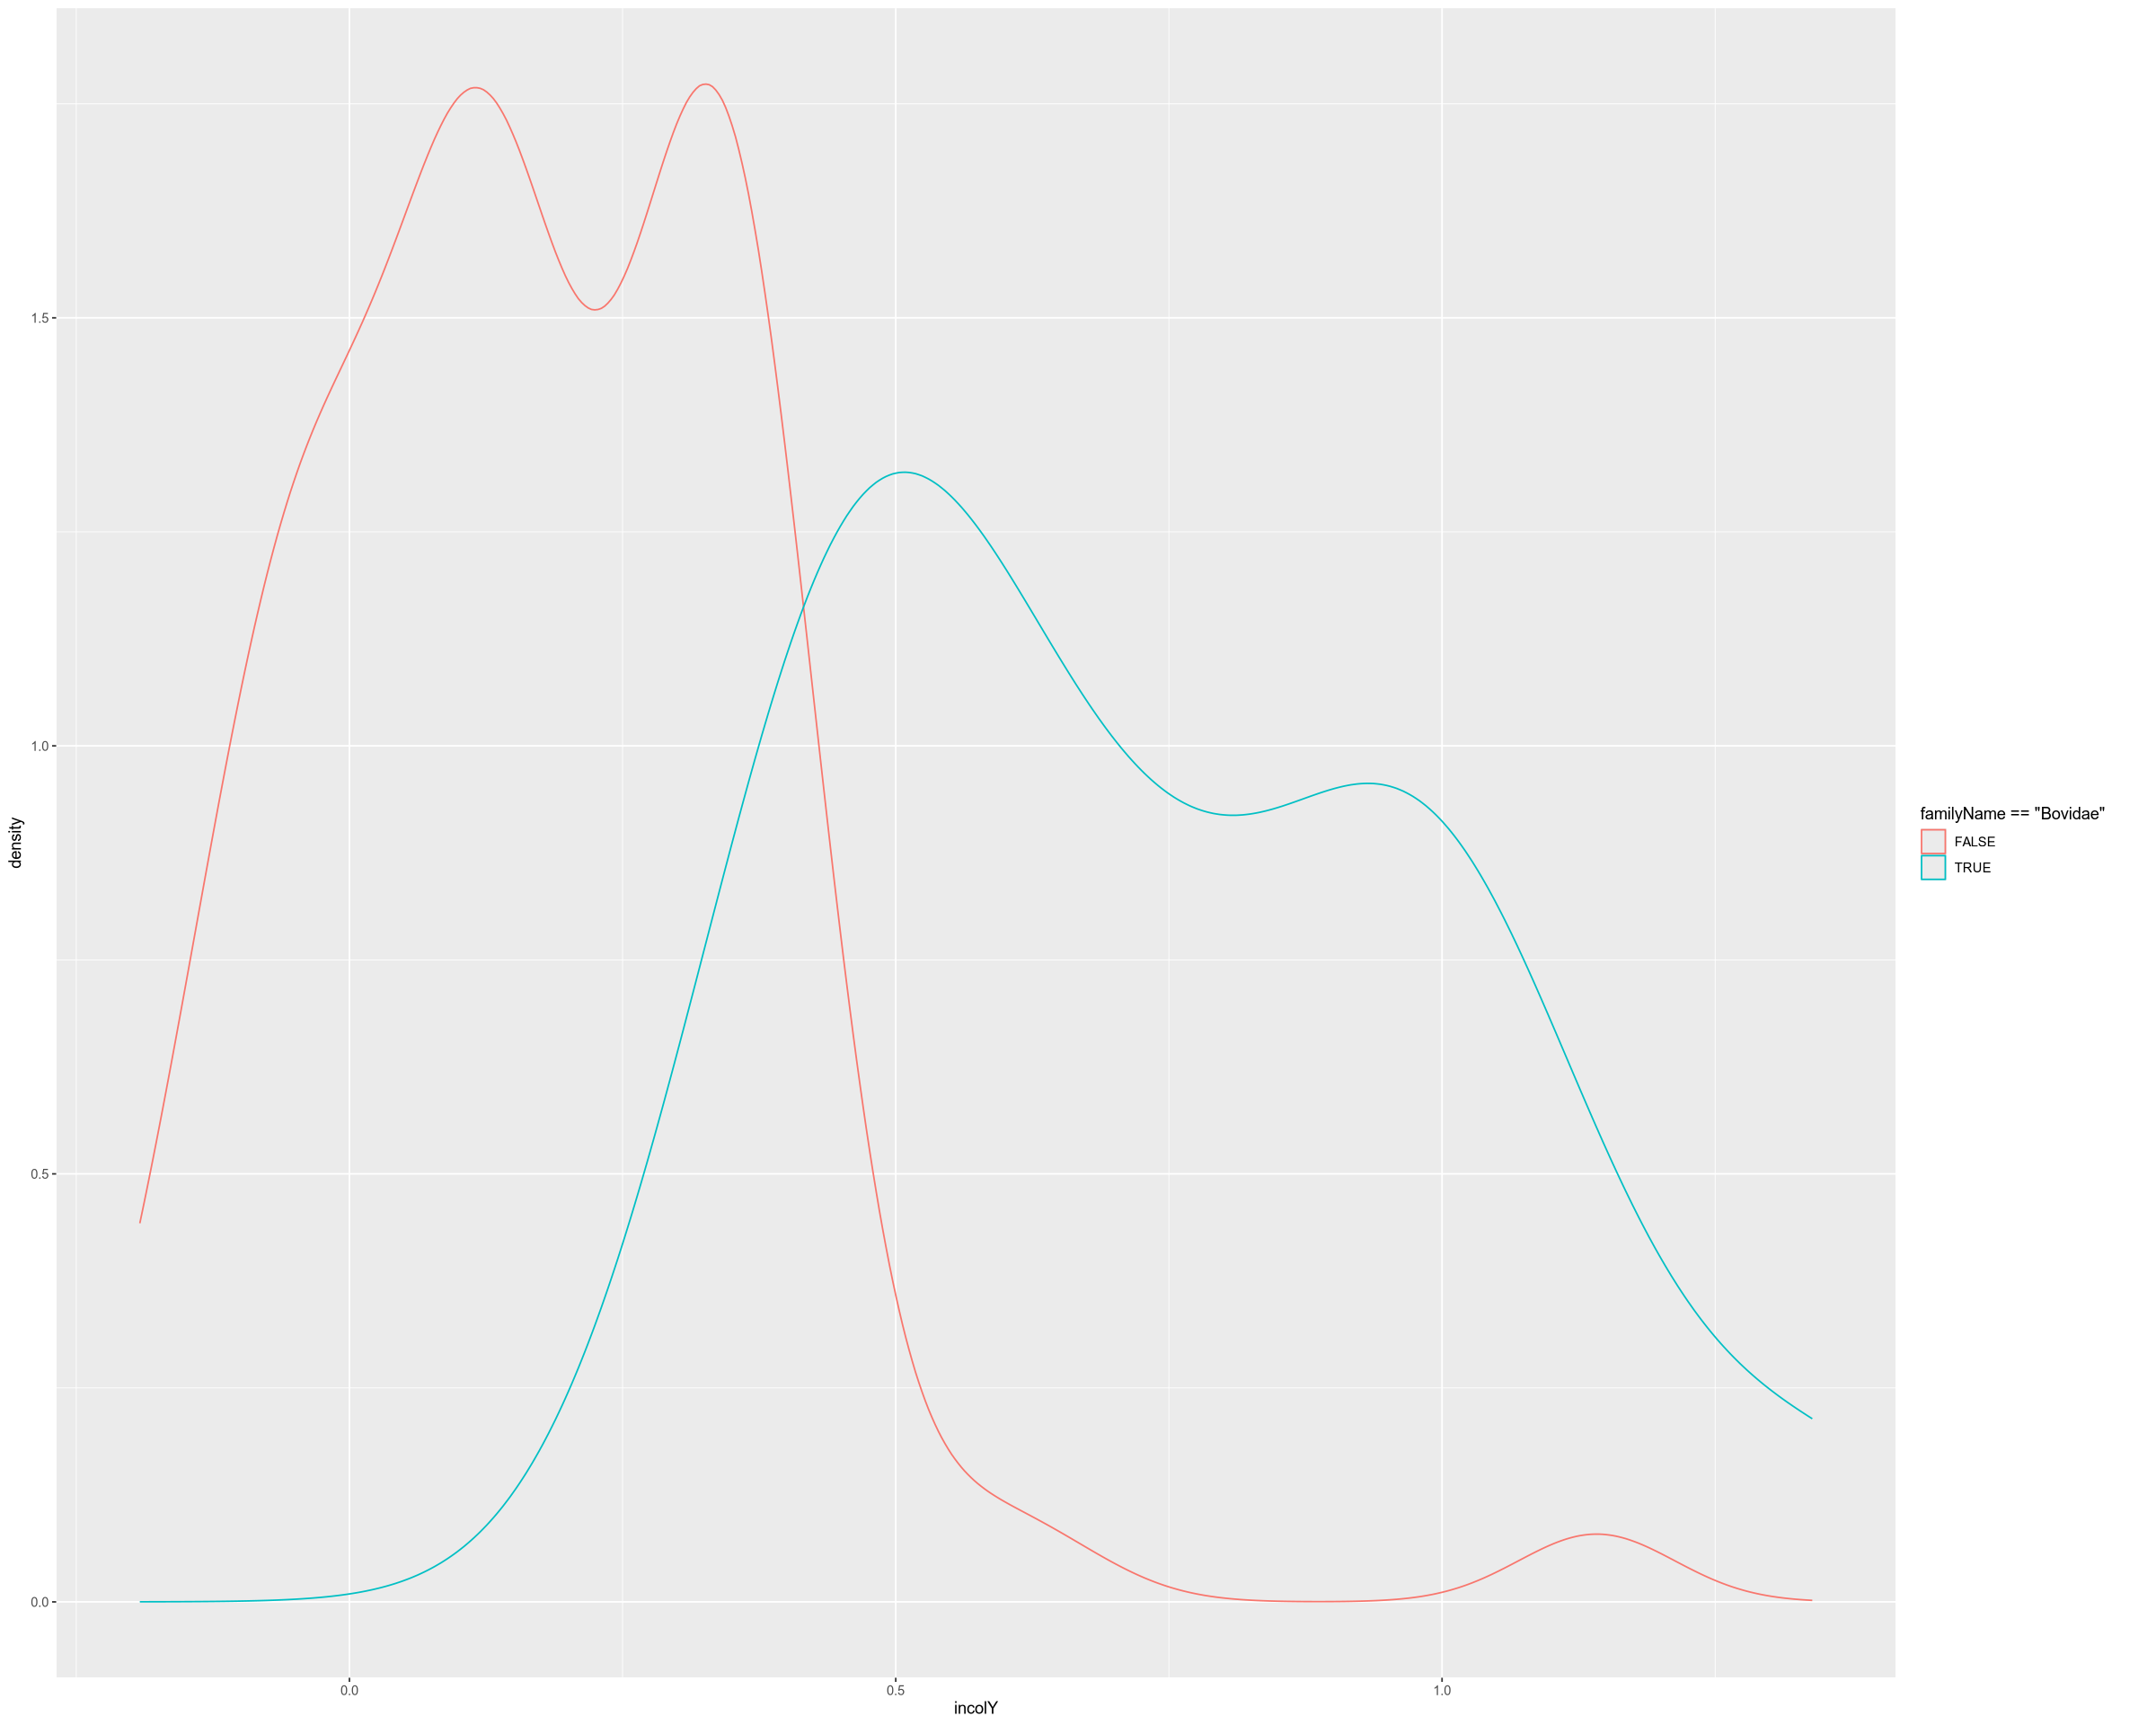

In [317]:
ggplot(HMMstatsDT, aes(x=incolY, color=familyName=='Bovidae')) + geom_density()

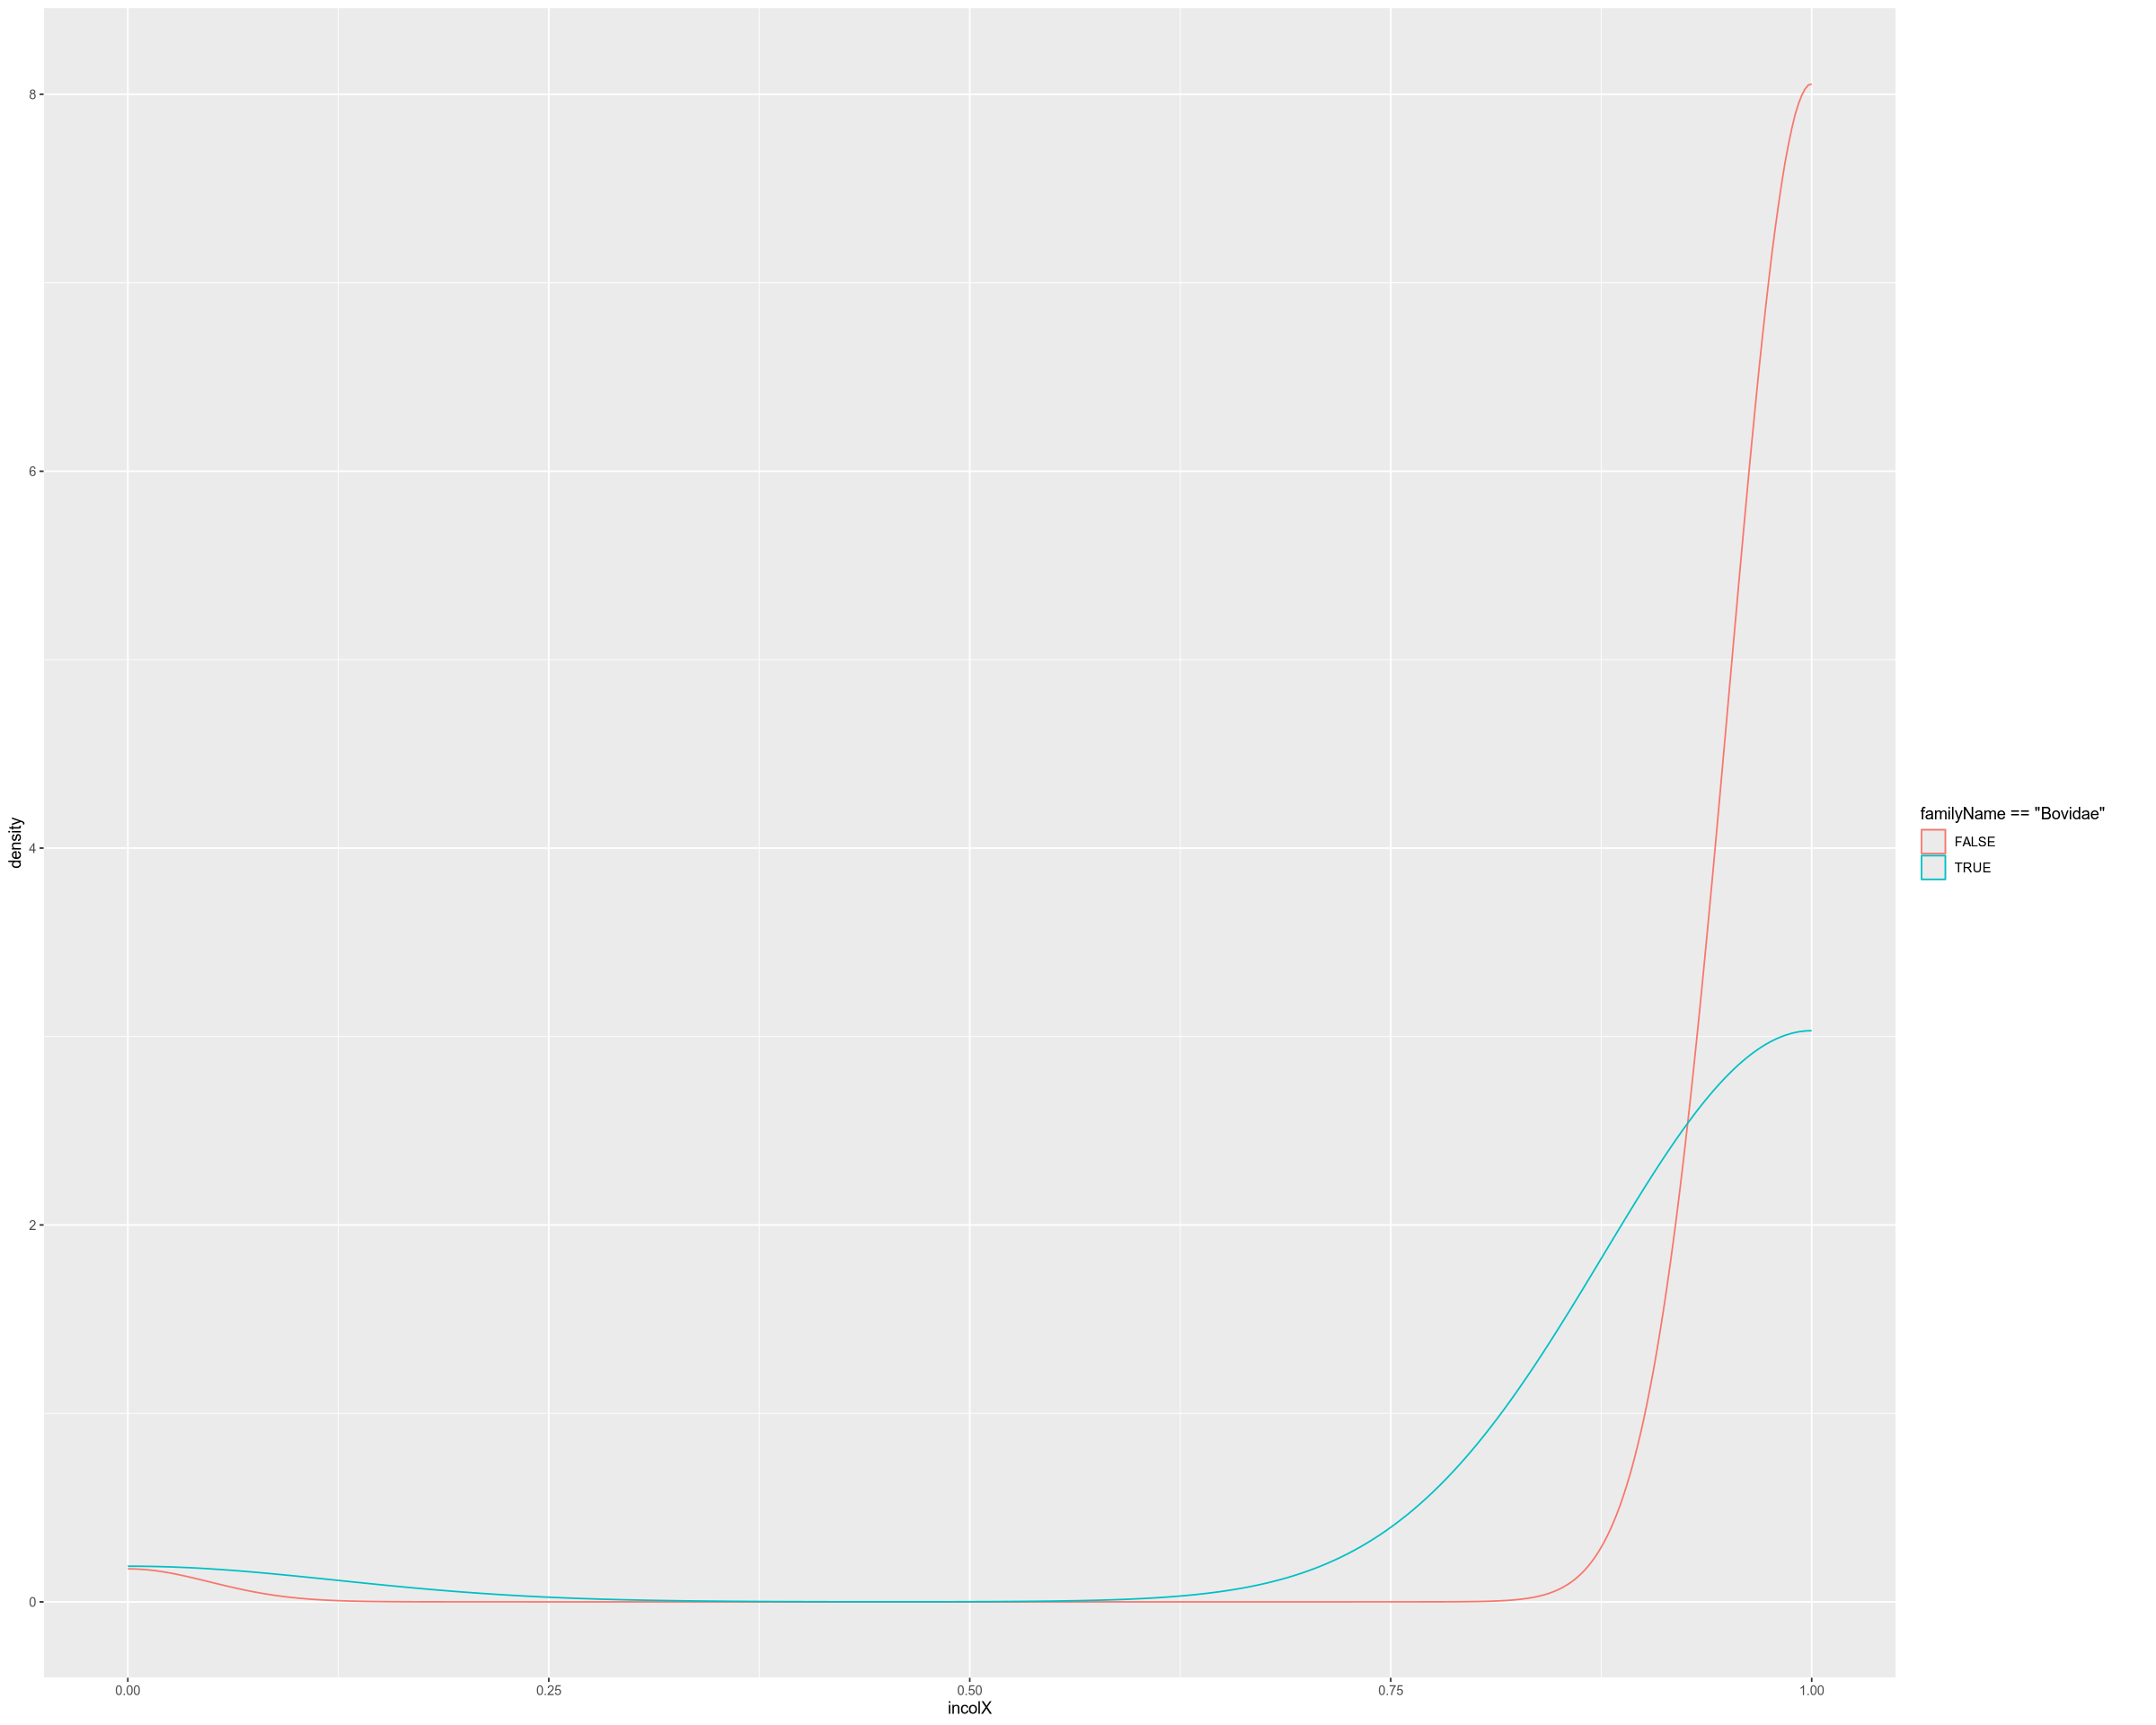

In [318]:
ggplot(HMMstatsDT, aes(x=incolX, color=familyName=='Bovidae')) + geom_density()

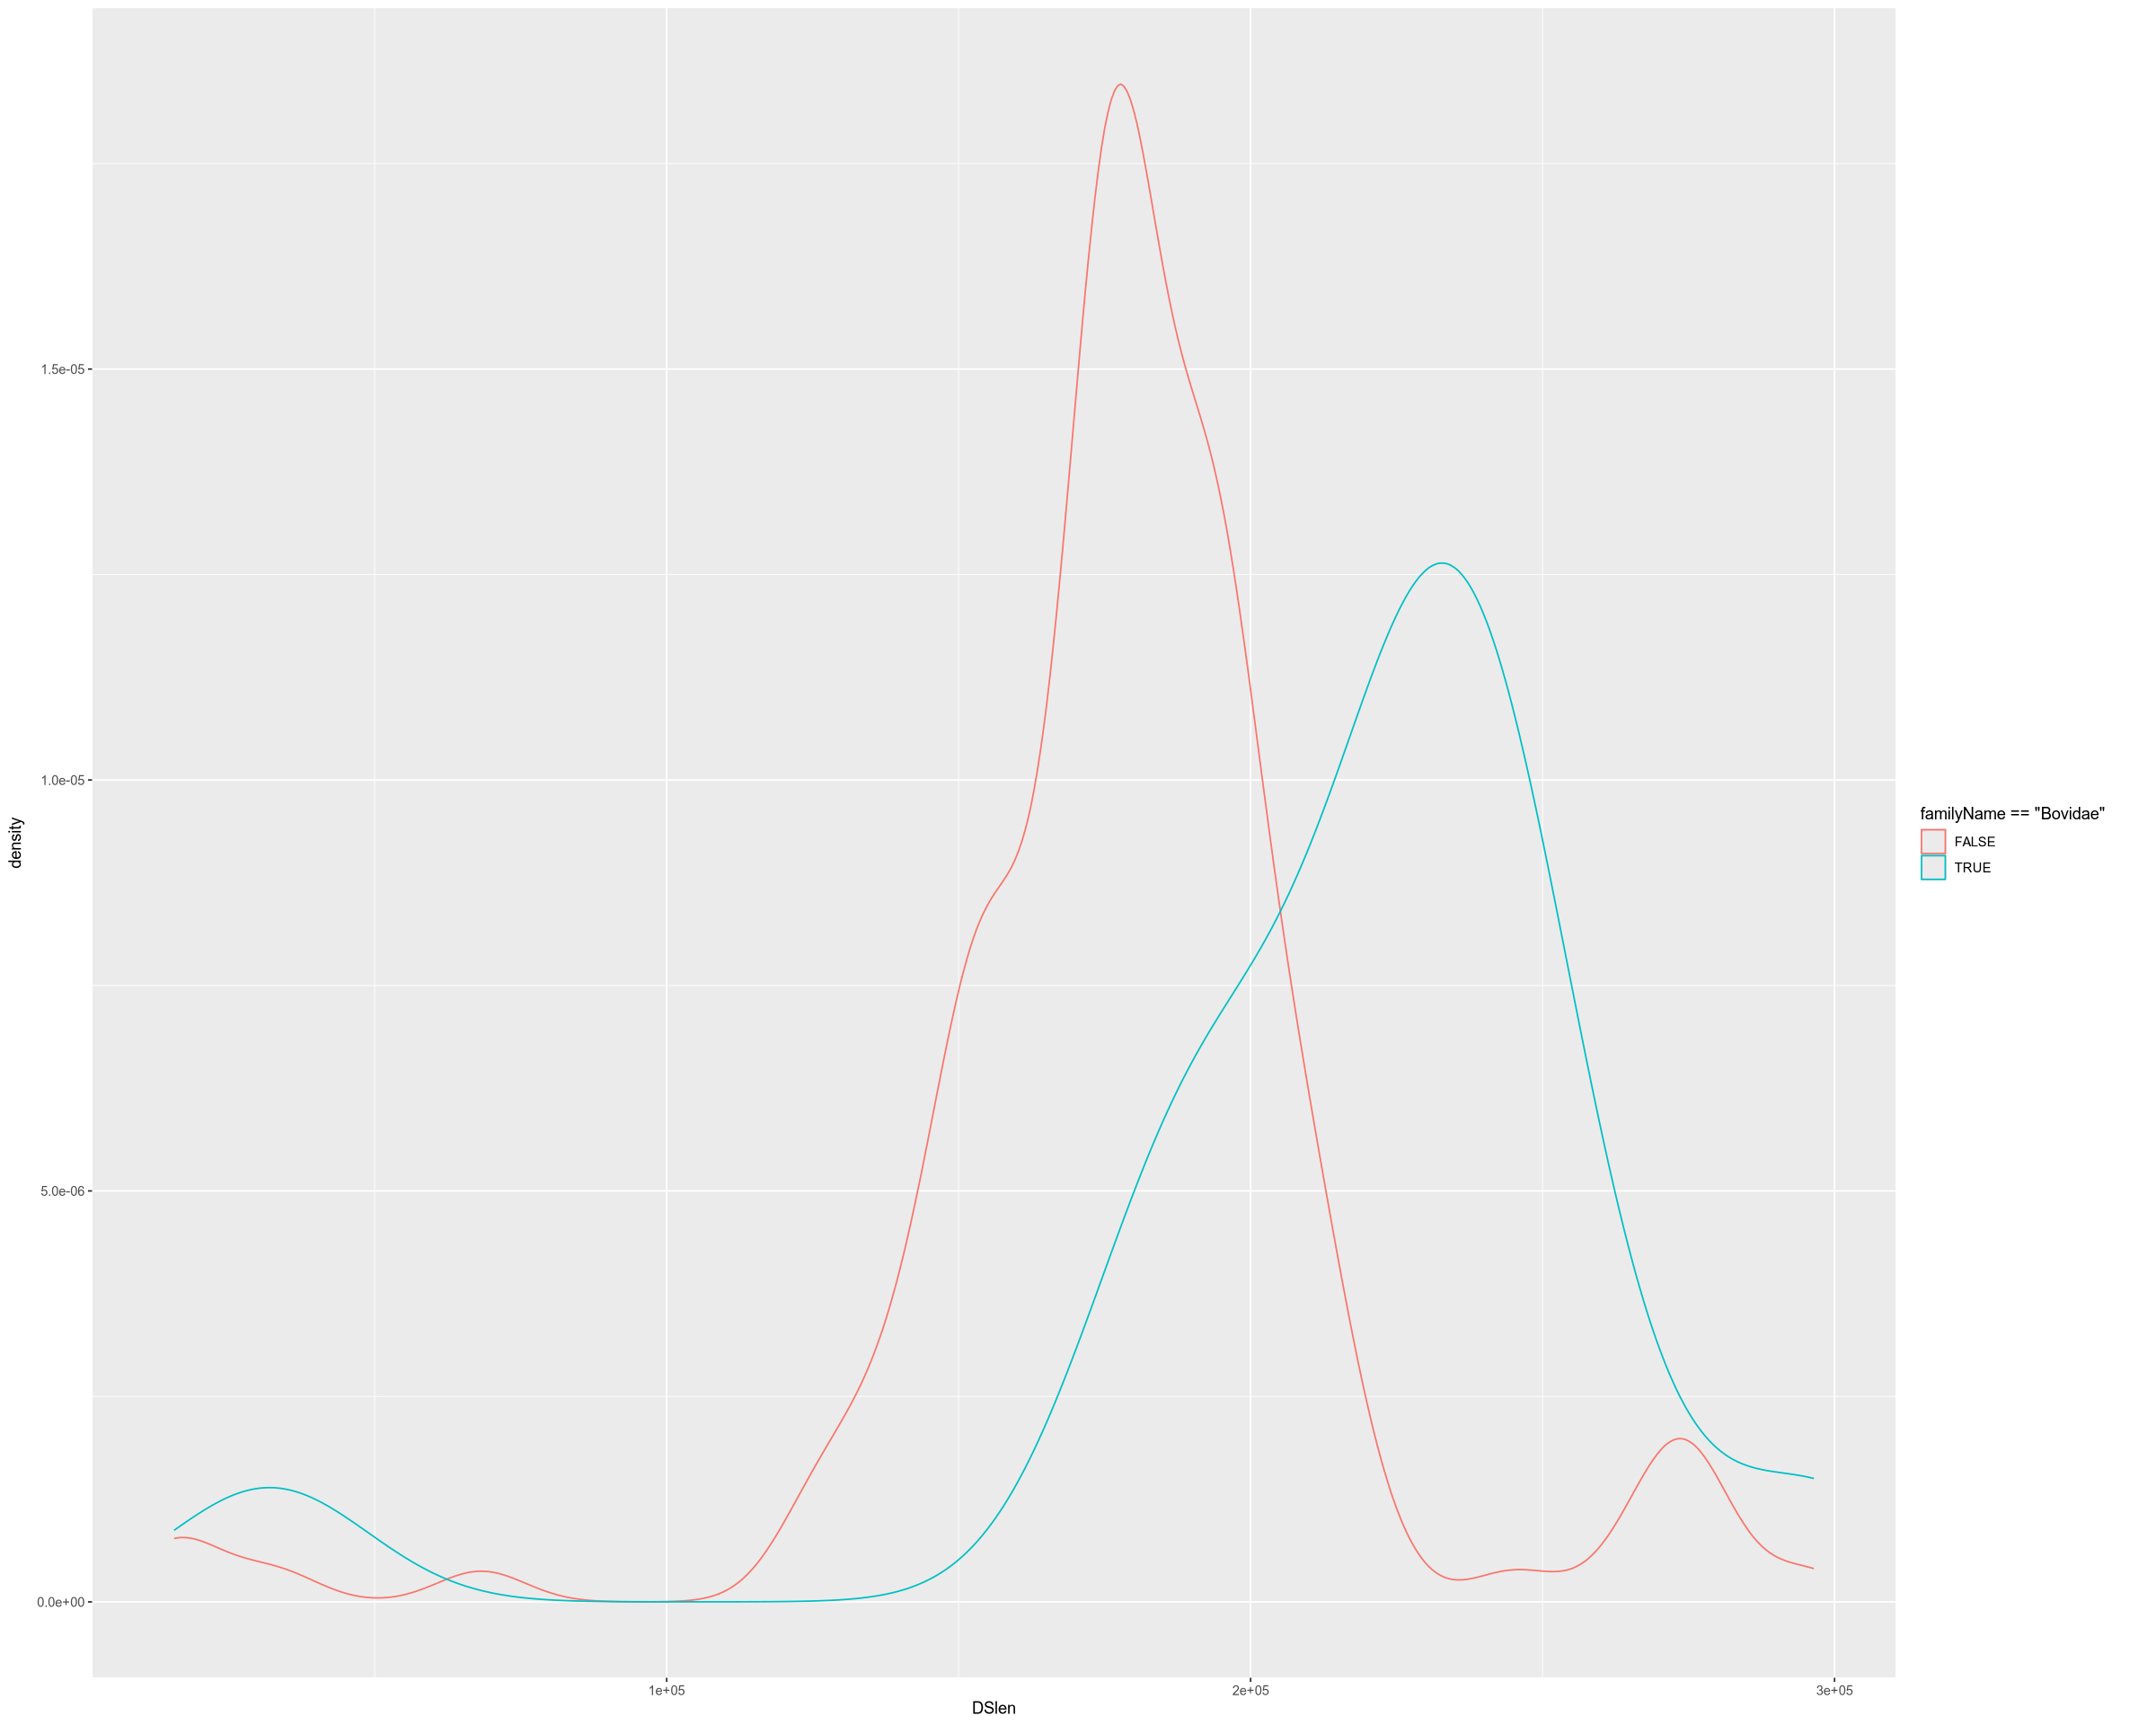

In [319]:
ggplot(HMMstatsDT, aes(x=DSlen, color=familyName=='Bovidae')) + geom_density()

In [326]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM HMMstats5MB'
HMMs=dbGetQuery(mydbRO, queryTxt)[[1]]
interestingGenes=NULL
Only50Kresults=NULL
i=1
HMMid='ENSG00000170500'#c('ENSG00000100554', "ENSG00000151131", "ENSG00000170500", "ENSG00000091651")

    if (i %% 200 ==0) message(i," / ",length(HMMs))
    i=i+1

    queryTxt=sprintf('SELECT * FROM HMMstats5MB WHERE ensembl_gene_id="%s"', HMMid)
    HMMstatsDT=as.data.table(dbGetQuery(mydbRO, queryTxt))
    statsDFtmp = HMMstatsDT %>% group_by(ensembl_gene_id, familyID) %>% filter(n()>2)
    normalTest=analyzeTheFamilies(statsDFtmp)
    message("normalTest: ",normalTest)
    message("sum(statsDFtmp$DSlen > 50000)/nrow(statsDFtmp): ",sum(statsDFtmp$DSlen > 50000)/nrow(statsDFtmp))
    if (sum(statsDFtmp$DSlen > 50000)/nrow(statsDFtmp) > 0.5){
        cut50KTest=analyzeTheFamilies(statsDFtmp, incolX = as.integer(statsDFtmp$DSlen>50000), incolY=2*(statsDFtmp$asRMSKlen50K-statsDFtmp$sRMSKlen50K)/50000, 
                   colYthreshold=0.7, epsilon = 0.1, verbose=TRUE)
        message('cut50KTest: ',cut50KTest)
         if (cut50KTest){
            interestingGenes=addToVec(interestingGenes, HMMid)
             Only50Kresults=addToVec(Only50Kresults, HMMid)
        }
    }


normalTest: FALSE

sum(statsDFtmp$DSlen > 50000)/nrow(statsDFtmp): 0.976190476190476

cut50KTest: TRUE



In [29]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM interestinggenes'
interestingGenes=dbGetQuery(mydbRO, queryTxt)[[1]]

system("mkdir -p ~/data/lambda/output/scratches/clustering", wait = TRUE)

swarmparams="#SWARM -t 1 -g 10 --time=00:40:00 --gres=lscratch:10"
sbatchscript="~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R"
swarmlines=paste(sbatchscript, interestingGenes)
swarmlines=c(swarmparams, swarmlines)
writeLines(text = swarmlines, con = "~/data/lambda/output/scratches/clustering/run.swarm")

In [30]:
swarmlines

[1] "#SWARM -t 1 -g 10 --time=00:40:00 --gres=lscratch:10"                                                                        
 [2] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000001626"
 [3] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000029559"
 [4] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000081014"
 [5] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000091651"
 [6] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000094841"
 [7] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000111701"
 [8] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000111879"
 [9] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000112167"
[10] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000114767"
[11] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000115085"
[12] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000115364"
[13] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000115840"
[14] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000115993"
[15] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000116793"
[16] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000118690"
[17] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000121621"
[18] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000123901"
[19] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000124370"
[20] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000124678"
[21] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000130119"
[22] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000130385"
[23] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000133997"
[24] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000135324"
[25] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000135355"
[26] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000136319"
[27] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000139921"
[28] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000140374"
[29] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000144644"
[30] "~/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh ~/data/lambda/notebooks/scratches_run_clustering_plot.R ENSG00000144848"
[31] "~/data/lambda/notebooks/Rscript.wra

In [83]:
analyzeTheFamilies_debug<-function(inDF, incolX=(inDF$DSlen)/median(inDF$DSlen),
                             incolY=2*(inDF$asRMSKlen-inDF$sRMSKlen)/inDF$DSlen, colYthreshold=0.75, Ymask=inDF$DSlen<(4000), epsilon=0.2,
                            minOddsRatio=2, minMedianDSforTopCluster=25000, minMedian_asRMSKlen10K=4000, MinPts = 10, minGenomesInTopCluster=5, verbose=FALSE){
    incolY[ Ymask] =0
    inDF$colX=incolX
    inDF$colY=incolY
    inDF=inDF[ !(is.na(incolX) | is.na(incolY)) ,]

    Dbscan_cl=dbscan(inDF[, c("colX", "colY")], eps = epsilon, MinPts = MinPts) 
    inDF$cluster=Dbscan_cl$cluster
    clustersNormDF=inDF %>% group_by(cluster) %>% summarize(numGenomes=n(), numFamilies=length(unique(familyID)), meanColY=mean(colY),
                                                           meanColX=mean(colX), meanDSlen=mean(DSlen), medianDSlen=median(DSlen), mean_asRMSKlen10K=mean(asRMSKlen10K), median_asRMSKlen10K=median(asRMSKlen10K))

    if (all(clustersNormDF$meanColY<colYthreshold)){
        if (verbose) message('all(clustersNormDF$meanColY<colYthreshold)')
        return(FALSE)
    }
    if (verbose) print(clustersNormDF, width = Inf)
    if (all(clustersNormDF$numGenomes[clustersNormDF$meanColY>=colYthreshold]<minGenomesInTopCluster)){
        if (verbose) message('all(clustersNormDF$numGenomes[clustersNormDF$meanColY>=colYthreshold]<minGenomesInTopCluster)')
        return(FALSE)
    }
    if (all(clustersNormDF$medianDSlen[ clustersNormDF$meanColY>=colYthreshold ]<minMedianDSforTopCluster)){
        if (verbose) message('all(clustersNormDF$meanDSlen<minMedianDSforTopCluster)')
        return(FALSE)
    }

    if (all(clustersNormDF$median_asRMSKlen10K[ clustersNormDF$medianDSlen>=minMedianDSforTopCluster ]<minMedian_asRMSKlen10K)){
        if (verbose) message('all(clustersNormDF$median_asRMSKlen10K[ clustersNormDF$medianDSlen>=minMedianDSforTopCluster ]<minMedian_asRMSKlen10K)')
        return(FALSE)
    }
    interestingGene=TRUE
    # 1) there should 2 or more clusters. 

    if (nrow(clustersNormDF)==1){
        if (verbose) message('nrow(clustersNormDF)==1')
        return(FALSE)
    }
    # probability that families are randomly distributed across clusters
    familyNormDF=inDF %>% group_by(familyID) %>% summarize(numGenomes=n(), weight=numGenomes/nrow(inDF), .groups="drop_last")
    familyVSclusterStat=inDF %>% group_by(familyID, cluster) %>% summarize(numGenomes=n(), .groups="drop_last")

    for (clusterID in clustersNormDF$cluster){
        familyNormDF[[paste0("cluster", clusterID,"weight")]]=0.0
    }
    
    for ( i in 1:nrow(familyNormDF)){
        famID=familyNormDF$familyID[i]
        familyTMP=inDF[ inDF$familyID==famID,]
        for (j in 1:nrow(clustersNormDF)){
            clustersNormDFtmp=clustersNormDF[ j,]
            familyClusterTMP=familyTMP[ familyTMP$cluster==clustersNormDFtmp$cluster,]
            tmpColname=paste0("cluster", clustersNormDFtmp$cluster,"weight")
            familyNormDF[i, colnames(familyNormDF)==tmpColname]=nrow(familyClusterTMP)/clustersNormDFtmp$numGenomes
        }
    }

    for ( colnum in which(grepl(pattern = "cluster\\d+weight$", colnames(familyNormDF))) ){
        familyNormDF[, ncol(familyNormDF)+1]=familyNormDF[, colnum]/familyNormDF$weight
        tmpColnames=colnames(familyNormDF)
        tmpColnames[ncol(familyNormDF)]=paste0(colnames(familyNormDF)[colnum], "ratio", collapse = "")
        colnames(familyNormDF)<-tmpColnames
    }
    #print(familyNormDF)

    # 2) At least one of the families should have more that 2x weight (odds) ratio in one of the clusters
    tmpDF=as.data.frame(familyNormDF[ ,grepl(pattern = "familyID|cluster\\d+weightratio", x = colnames(familyNormDF))]) %>% 
    rowwise() %>% filter(any(c_across(starts_with('cl'))>=minOddsRatio)) 
    
    if (nrow(tmpDF)==0){
        if (verbose) message('nrow(tmpDF)==0')
        return(FALSE)
    }
    
    overreppresentedFamiliesDF= data.frame(matrix(ncol = 2, nrow = 0))
    colnames(overreppresentedFamiliesDF) <- c("familyID", "cluster")
    #print(overreppresentedFamiliesDF)
    for (i in 1:nrow(tmpDF)){
        familyID=tmpDF$familyID[i]
        tmpDF2=tmpDF[i,grepl(pattern = "cluster\\d+weight", x = colnames(tmpDF))]
        clusterNames=colnames(tmpDF2)[tmpDF2[1,]>=minOddsRatio]
        clusterNames=str_remove_all(string = clusterNames, pattern = "[a-z]")
        for (clname in clusterNames){
            overreppresentedFamiliesDF[nrow(overreppresentedFamiliesDF)+1, ]=c(familyID, as.integer(clname))
        }
    }
    
    # 3) That family should have at least 50% of the members in that cluster
    fractionOfOverreprFamiliesInCorrCluster=NULL
    for (i in 1:nrow(overreppresentedFamiliesDF)){
        familyID=overreppresentedFamiliesDF$familyID[i]
        cluster=overreppresentedFamiliesDF$cluster[i]
        FamGenomesInCluster=familyVSclusterStat$numGenomes[ familyVSclusterStat$familyID==familyID & familyVSclusterStat$cluster==cluster]
        numGenomesInFamily=familyNormDF$numGenomes[ familyNormDF$familyID == familyID]
        fractionOfOverreprFamiliesInCorrCluster=addToVec(fractionOfOverreprFamiliesInCorrCluster, FamGenomesInCluster/numGenomesInFamily)
    }
    #print(fractionOfOverreprFamiliesInCorrCluster)
    if (!any(fractionOfOverreprFamiliesInCorrCluster>0.5)){
        if (verbose) message('!any(fractionOfOverreprFamiliesInCorrCluster>0.5)')
        return(FALSE)
    }
    return(TRUE)
}

In [85]:
interestingGenes=NULL
Only50Kresults=NULL
i=1

HMMid='ENSG00000140374'#c('ENSG00000100554', "ENSG00000151131", "ENSG00000170500", "ENSG00000091651")

    if (i %% 200 ==0) message(i," / ",length(HMMs))
    i=i+1

    queryTxt=sprintf('SELECT * FROM HMMstats5MB WHERE ensembl_gene_id="%s"', HMMid)
    HMMstatsDT=as.data.table(dbGetQuery(mydbRO, queryTxt))
    statsDFtmp = HMMstatsDT %>% group_by(ensembl_gene_id, familyID) %>% filter(n()>2)
    normalTest=analyzeTheFamilies_debug(statsDFtmp, verbose = TRUE)
    message(normalTest)
    if (normalTest){
        interestingGenes=addToVec(interestingGenes, HMMid)
        
    }
    if (sum(statsDFtmp$DSlen > 50000)/nrow(statsDFtmp) > 0.5){
        message("Trying 50K")
        cut50KTest=analyzeTheFamilies_debug(statsDFtmp, incolX = as.integer(statsDFtmp$DSlen>50000), incolY=2*(statsDFtmp$asRMSKlen50K-statsDFtmp$sRMSKlen50K)/50000, 
                   epsilon = 0.1, verbose = TRUE)
        message(cut50KTest)
         if (cut50KTest){
            interestingGenes=addToVec(interestingGenes, HMMid)
             Only50Kresults=addToVec(Only50Kresults, HMMid)
        }
    }


# A tibble: 3 × 9
  cluster numGenomes numFamilies meanColY meanColX meanDSlen medianDSlen
    <dbl>      <int>       <int>    <dbl>    <dbl>     <dbl>       <dbl>
1       0          2           2   0.831     3.51     39842.      39842.
2       1        122          17  -0.0457    1.06     12015.      11486.
3       2         12           2  -0.0228    0.456     5164.       5264.
  mean_asRMSKlen10K median_asRMSKlen10K
              <dbl>               <dbl>
1             6715                 6715
2              943.                1045
3              325.                   0


all(clustersNormDF$numGenomes[clustersNormDF$meanColY>=colYthreshold]<minGenomesInTopCluster)

FALSE



# Proteomics

In [2]:
library(tidyjson)


Attaching package: ‘tidyjson’


The following object is masked from ‘package:stats’:

    filter




In [3]:
samples_json_data <- read_json("~/data/lambda/data/proteomicsDB//api.samples.json")


In [4]:
process_a_sample=function(inrecord){
    outlist=list()
    for (fn in names(inrecord)){
        if (typeof(inrecord[[fn]]) != 'list'){
            outlist[[fn]]=inrecord[[fn]]
        }
    }
    return(as.data.frame(outlist))
}

In [5]:
all_samples_DF_list=lapply(X = samples_json_data$`..JSON`[[1]][['d']]$results, FUN = process_a_sample)

In [6]:
all_samples_DF = bind_rows(all_samples_DF_list)
all_samples_DF=all_samples_DF[ !is.na(all_samples_DF$SAMPLE_ID), ]
all_samples_DF=all_samples_DF[ !is.na(all_samples_DF$AFFINITY_PURIFICATION), ]
all_samples_DF=all_samples_DF[ !is.na(all_samples_DF$TISSUE), ]
all_samples_DF=all_samples_DF[ !is.na(all_samples_DF$CELL_EXTRACT), ]

In [7]:
all_samples_DF=all_samples_DF[ all_samples_DF$TAXCODE == 9606, ] # select for humans


In [8]:
all_samples_DF=all_samples_DF[ all_samples_DF$AFFINITY_PURIFICATION == "Not applicable/none" | nchar(all_samples_DF$AFFINITY_PURIFICATION) == 0, ] # no enritchment


In [9]:
all_samples_DF=all_samples_DF[ all_samples_DF$CELL_EXTRACT == "Whole", ] # no enritchment

#all_samples_DF=all_samples_DF[ all_samples_DF$DISEASE == "Not applicable/none", ] # no diseases

In [10]:
all_samples_DF=all_samples_DF[ ! grepl(pattern = " cell$", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = " cell line$", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "^[A-Z]{2,3}-\\d{1,4}$", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "^[A-Z]{2,3} \\d{1,4}$", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "\\d", x = all_samples_DF$TISSUE),]

all_samples_DF=all_samples_DF[ ! grepl(pattern = "fluid", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "juice", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "hES", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "iPS", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "NFF", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "Mixed", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "serum", x = all_samples_DF$TISSUE),]

all_samples_DF=all_samples_DF[ ! grepl(pattern = "COLO", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ grepl(pattern = "[a-z]", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "milk", x = all_samples_DF$TISSUE),]
all_samples_DF=all_samples_DF[ ! grepl(pattern = "saliva", x = all_samples_DF$TISSUE),]



In [11]:
boolmask = all_samples_DF$DISEASE == "Not applicable/none"
boolmask[ is.na(boolmask)] =TRUE
boolmask = boolmask | nchar(all_samples_DF$DISEASE) == 0
all_samples_DF=all_samples_DF[ boolmask,]

all_samples_DF=all_samples_DF[ !grepl("mouse", all_samples_DF$DESCRIPTION, ignore.case = TRUE),]
all_samples_DF=all_samples_DF[ !grepl("fetal", all_samples_DF$DESCRIPTION, ignore.case = TRUE),]

In [12]:
any(is.na(boolmask))

[1] FALSE

In [13]:
table(all_samples_DF$MASS_SPECTROMETER)


         Exactive Plus                 LTQ FT LTQ Orbitrap Discovery 
                    34                      1                      8 
    LTQ Orbitrap Elite     LTQ Orbitrap Velos        LTQ Orbitrap XL 
                    75                    110                     16 
       Orbitrap Fusion             Q Exactive          Q Exactive HF 
                     2                     10                      6 

In [14]:
length( all_samples_DF$SAMPLE_ID)

[1] 265

In [15]:
length(unique( all_samples_DF$SAMPLE_ID))

[1] 265

In [16]:
t(all_samples_DF[1:10,])

,1090,1092,1093,1094,1095,1097,1098,1099,1290,1459
SAMPLE_ID,1126,1128,1129,1130,1131,1133,1134,1135,1351,1532
EXPERIMENT_ID,89,91,92,93,94,96,97,98,123,145
NAME,Roche_human_breast,Roche_human_pancreas,Roche_human_bone,Roche_human_heart,Roche_human_ovary,Roche_human_platelets_lysate,Roche_human_adipocyte,Roche_human_lung,HSC,raw
DESCRIPTION,Roche_human_breast,Roche_human_pancreas,Roche_human_bone,Roche_human_heart,Roche_human_ovary,Roche_human_platelets_lysate,Roche_human_adipocyte,Roche_human_lung,HSC,raw
TAXCODE,9606,9606,9606,9606,9606,9606,9606,9606,9606,9606
TISSUE_ID,BTO:0000149,BTO:0000988,BTO:0000140,BTO:0000562,BTO:0000975,BTO:0000132,BTO:0000443,BTO:0000763,BTO:0000782,BTO:0001419
TISSUE,breast,pancreas,bone,heart,ovary,blood platelet,adipocyte,lung,T-lymphocyte,urine
TREATMENT,,,,,,,,,,
TREATMENT_DETAILS,,,,,,,,,,
TREATMENT_AGENT,,,,,,,,,,


## expression data

In [17]:
swarmlines=sprintf("wget -O 'api.expression_sample%d.json' 'https://www.proteomicsdb.org/proteomicsdb/logic/api_v2/api.xsodata/ProteinExpression?$format=json&$filter=SAMPLE_ID eq %d'",
                  all_samples_DF$SAMPLE_ID, all_samples_DF$SAMPLE_ID)
swarmparams="#SWARM -t 1 -g 1 --time=01:00:00 --gres=lscratch:2 --logdir /home/frimanav/data/lambda/data/proteomicsDB/slurm_logs/"

swarmlines=c(swarmparams, swarmlines)
writeLines(swarmlines, "/home/frimanav/data/lambda/data/proteomicsDB/get_expression.swarm")

In [18]:
all_samples_DF$NUM_PROTEINS=NA
for (sampleID in all_samples_DF$SAMPLE_ID){
    jsonfname=sprintf("~/data/lambda/data/proteomicsDB/api.expression_sample%d.json", sampleID)
    expr_json_data <- read_json(jsonfname)
    all_samples_DF$NUM_PROTEINS[ sampleID == all_samples_DF$SAMPLE_ID] = length(expr_json_data[['..JSON']][[1]][['d']][['results']])
}

In [19]:
all_samples_DF_prod= all_samples_DF[ all_samples_DF$NUM_PROTEINS>20000,]

## protein data

In [20]:
options(scipen = 999)
sbatchscript=paste0(normalizePath(path.expand(paste0(OutputDir,'../notebooks/'))),"/Rscript.wrapper.lambdaenv.sh ")

scriptdir=normalizePath(path.expand(paste0(OutputDir,'../notebooks/')))
swarmparams="#SWARM -t 1 -g 1 --time=01:00:00 --gres=lscratch:2 --logdir /home/frimanav/data/lambda/data/proteomicsDB/slurm_logs/"
jsonfnames=sprintf("~/data/lambda/data/proteomicsDB/api.expression_sample%d.json", all_samples_DF$SAMPLE_ID)
swarmlines=sprintf('%s %s/process_JSON_TO_DF.R %s /home/frimanav/data/lambda/data/proteomicsDB/expression/', sbatchscript, scriptdir, jsonfnames)

swarmlines=c(swarmparams, swarmlines)

writeLines(swarmlines, "~/data/lambda/data/proteomicsDB/process_expression.swarm")

In [21]:
expr_DFs_list=list()
for (f in list.files(path = "~/data/lambda/data/proteomicsDB/expression/", pattern = ".*csv", full.names = TRUE)){
    #message(f)
    if (file.info(f)$size>1000) expr_DFs_list[[length(expr_DFs_list)+1]]=read.csv(f)
}

In [22]:
expr_DF=bind_rows(expr_DFs_list)

In [23]:
max(expr_DF$PROTEIN_ID)

[1] 86836

### Protein ID DF

In [24]:
jsonfname="~/data/lambda/data/proteomicsDB/api.protein100Kskip0.json"
prot_json_data <- read_json(jsonfname)


In [25]:
prot_DF_list=lapply(X = prot_json_data[['..JSON']][[1]][['d']]$results, FUN = process_a_sample)

In [26]:
prot_DF=bind_rows(prot_DF_list)

In [27]:
all( 1:max(expr_DF$PROTEIN_ID) %in% prot_DF$PROTEIN_ID)

[1] TRUE

### UNIPROT to Ensembl gene ID

In [28]:
queryTxt='SELECT * FROM GeneNameSynonims'
synonymsDF=dbGetQuery(mydbRO, queryTxt)

In [29]:
prot_DF=merge(prot_DF, synonymsDF, by.x = "GENE_NAME", by.y="synonym", all.x = TRUE)


In [30]:
uniprotDF=read.table("~/data/tmp/homo_sapiens_core_115_38/HUMAN_9606_idmapping.dat", col.names = c("id", "source", "name"), sep = "\t", quote = NULL)

In [31]:
nrow(uniprotDF)

[1] 5403666

In [32]:
uniprotDF_ens=uniprotDF[ uniprotDF$source == "Ensembl",]

In [33]:
nrow(uniprotDF_ens)

[1] 130220

In [34]:
all(prot_DF$UNIQUE_IDENTIFIER %in% uniprotDF_ens$id)

[1] FALSE

In [35]:
sum(prot_DF$UNIQUE_IDENTIFIER %in% uniprotDF_ens$id)

[1] 457892

In [36]:
length(prot_DF$UNIQUE_IDENTIFIER)

[1] 770535

In [37]:
prot_DF_expr=prot_DF[ prot_DF$PROTEIN_ID<= max(expr_DF$PROTEIN_ID),]

In [38]:
all(prot_DF_expr$UNIQUE_IDENTIFIER %in% uniprotDF_ens$id)

[1] FALSE

In [39]:
sum(prot_DF_expr$UNIQUE_IDENTIFIER %in% uniprotDF_ens$id)

[1] 401710

In [40]:
length(prot_DF_expr$UNIQUE_IDENTIFIER)

[1] 669823

In [41]:
prot_DF_expr_not_found= prot_DF_expr[ ! prot_DF_expr$UNIQUE_IDENTIFIER %in% uniprotDF_ens$id,]

In [42]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM AllSpeciesFoundGeneNames5MB'
HMMs=dbGetQuery(mydbRO, queryTxt)[[1]]

In [43]:
uniprotDF_ens$name_short=gsub(pattern = "\\.\\d+$", replacement = "", x = uniprotDF_ens$name)

In [44]:
all(HMMs %in% uniprotDF_ens$name_short)

[1] FALSE

In [45]:
sum(HMMs %in% uniprotDF_ens$name_short)

[1] 9603

In [46]:
HMMs_not_found_in_uniprot= HMMs[ ! HMMs %in% uniprotDF_ens$name_short]

In [47]:
all(HMMs_not_found_in_uniprot %in% prot_DF$ensembl_gene_id)

[1] TRUE

In [48]:
HMMs_not_found_in_uniprot_not_in_synonyms= HMMs_not_found_in_uniprot[ ! HMMs_not_found_in_uniprot %in% prot_DF$ensembl_gene_id]

In [49]:
HMMs_not_found_in_uniprot_not_in_synonyms

character(0)

In [50]:
prot_DF=merge(prot_DF, uniprotDF_ens, by.x = "UNIQUE_IDENTIFIER", by.y="id", all.x = TRUE)


In [51]:
prot_DF_relevant=prot_DF[, c("PROTEIN_ID", "UNIQUE_IDENTIFIER", "GENE_NAME", "ensembl_gene_id", "name_short") ]

In [52]:
prot_DF_relevant_unique=unique(prot_DF_relevant)

In [53]:
prot_DF_relevant_unique[ prot_DF_relevant_unique$PROTEIN_ID==132,]

,PROTEIN_ID,UNIQUE_IDENTIFIER,GENE_NAME,ensembl_gene_id,name_short
,<int>,<chr>,<chr>,<chr>,<chr>
1881,132,A1L167,UBE2QL1,ENSG00000215218,ENSG00000215218
1882,132,A1L167,UBE2QL1,ENSG00000215218,ENSG00000291747


In [54]:
prot_DF_relevant_unique=prot_DF_relevant_unique[ ( prot_DF_relevant_unique$name_short %in% HMMs ) | ( prot_DF_relevant_unique$ensembl_gene_id %in% HMMs ), ]

In [55]:
prot_DF_relevant_unique = prot_DF_relevant_unique[ ! (( ! prot_DF_relevant_unique$name_short %in% HMMs) & (! is.na(prot_DF_relevant_unique$name_short))), ]

In [56]:
prot_DF_relevant_unique$ensembl_gene_id_united=prot_DF_relevant_unique$ensembl_gene_id

In [57]:
prot_DF_relevant_unique$ensembl_gene_id_united[ is.na(prot_DF_relevant_unique$ensembl_gene_id_united)] = prot_DF_relevant_unique$name_short[ is.na(prot_DF_relevant_unique$ensembl_gene_id_united)]

In [58]:
prot_DF_relevant_unique$ensembl_gene_id = NULL
prot_DF_relevant_unique$name_short = NULL

In [59]:
prot_DF_relevant_unique=unique(prot_DF_relevant_unique)

## Checking samples for fraction of my HMMs expressed

In [60]:
found_proteinsDF=NULL
for (i in 1:nrow(all_samples_DF) ){
    sample_id=all_samples_DF$SAMPLE_ID[i]
    tissue=all_samples_DF$TISSUE[i]
    expr_DF_tmp=expr_DF[ expr_DF$SAMPLE_ID==sample_id,]
    found_proteins=intersect(prot_DF_relevant_unique$PROTEIN_ID, expr_DF_tmp$PROTEIN_ID)
    found_ensembl_gene_ids=prot_DF_relevant_unique$ensembl_gene_id_united[ prot_DF_relevant_unique$PROTEIN_ID %in% found_proteins]
    found_HMMs = intersect( found_ensembl_gene_ids, HMMs)
    #message(paste(sample_id, tissue, length(found_proteins), length(found_HMMs)))
    tmpDF=data.frame(sample_id=sample_id, tissue=tissue, found_proteins=length(found_proteins), found_HMMs=length(found_HMMs))
    found_proteinsDF=addToDF(found_proteinsDF, tmpDF)
}

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”


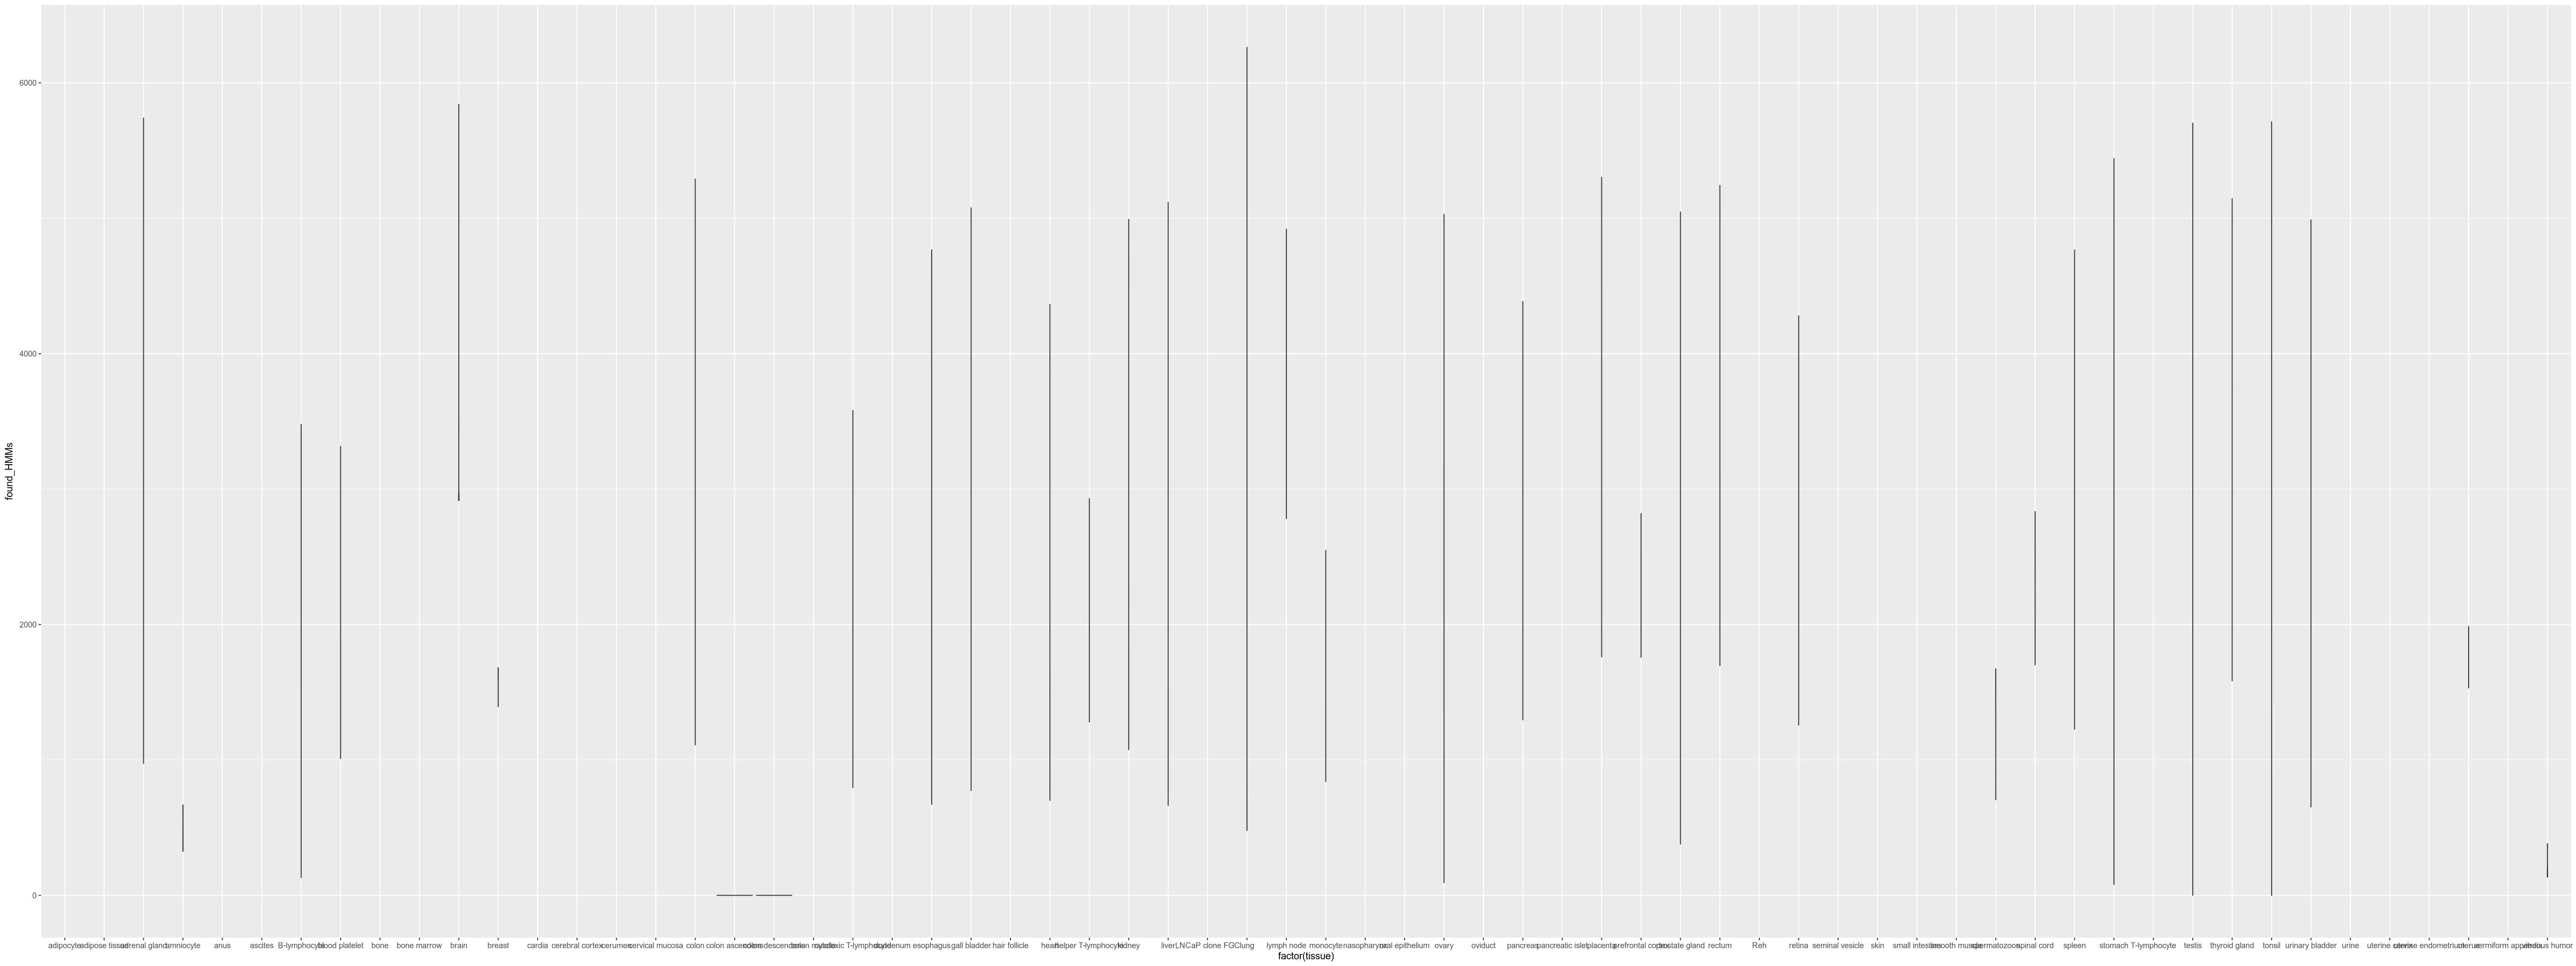

In [61]:
options(repr.plot.width=40, repr.plot.height=15 )

ggplot(found_proteinsDF, aes(y=found_HMMs, x=factor(tissue))) + geom_violin(drop = FALSE)

In [62]:
found_proteinsDF_good_detection = found_proteinsDF %>% group_by(tissue) %>% filter(found_HMMs==max(found_HMMs) & found_HMMs>0)

In [63]:
found_proteinsDF_good_detection$fraction_in_HMMs = found_proteinsDF_good_detection$found_HMMs / found_proteinsDF_good_detection$found_proteins

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


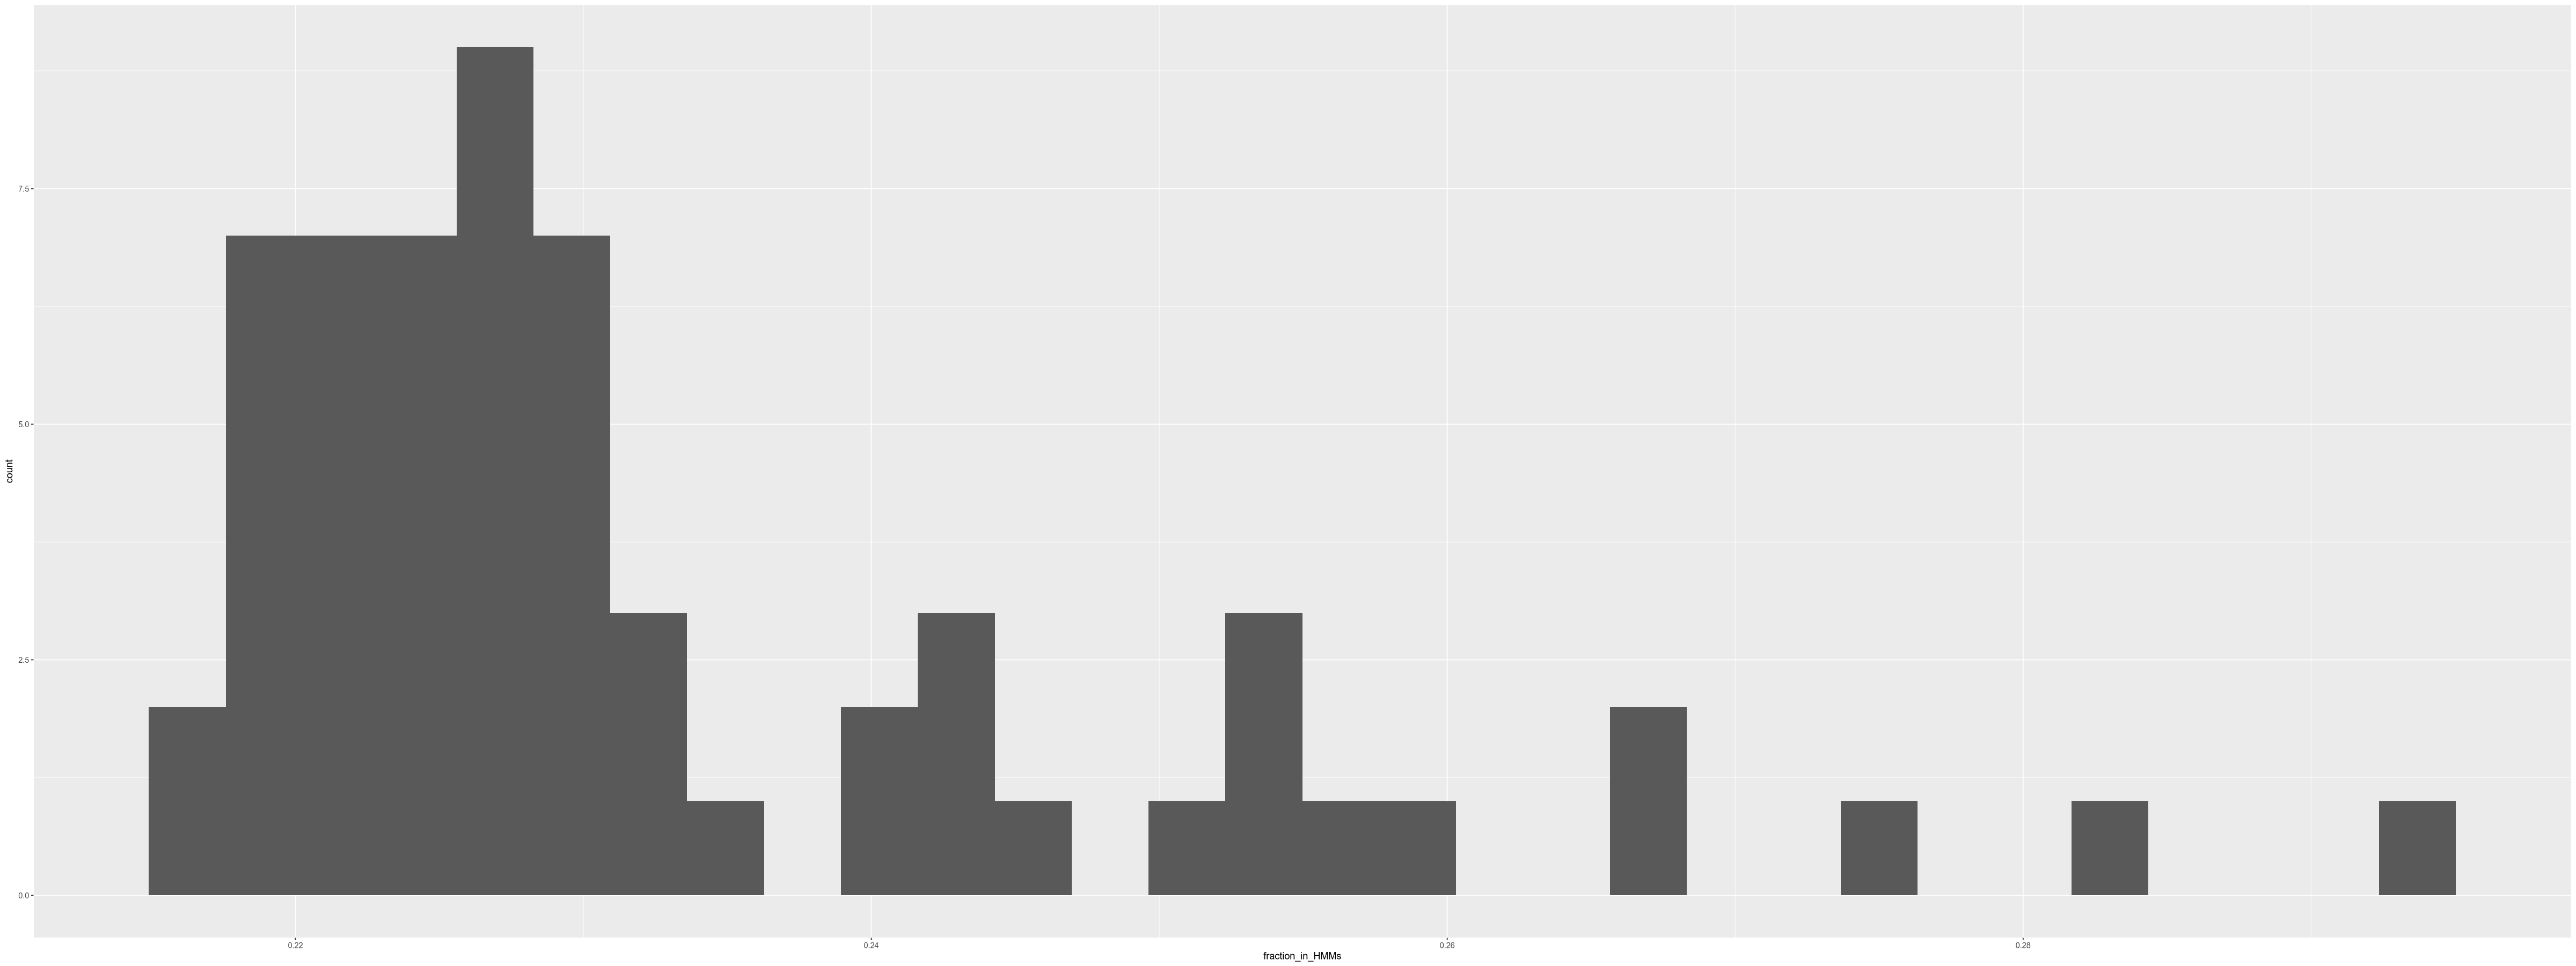

In [64]:
ggplot(found_proteinsDF_good_detection, aes(x=fraction_in_HMMs)) + geom_histogram()

In [138]:

expr_DF_good_detection=expr_DF[ expr_DF$SAMPLE_ID %in% found_proteinsDF_good_detection$sample_id, ]

In [77]:
HHMsFoundInSamples=data.frame(HMM=HMMs, found_in_samples=0, found_in_testis=0)
for (i in 1:nrow(found_proteinsDF_good_detection)){
    sample_id=found_proteinsDF_good_detection$sample_id[i]
    expr_DF_tmp=expr_DF[ expr_DF$SAMPLE_ID==sample_id,]
    found_proteins=intersect(prot_DF_relevant_unique$PROTEIN_ID, expr_DF_tmp$PROTEIN_ID)
    found_ensembl_gene_ids=prot_DF_relevant_unique$ensembl_gene_id_united[ prot_DF_relevant_unique$PROTEIN_ID %in% found_proteins]
    found_HMMs = intersect( found_ensembl_gene_ids, HMMs)
    HHMsFoundInSamples$found_in_samples[ HHMsFoundInSamples$HMM %in% found_HMMs] = HHMsFoundInSamples$found_in_samples[ HHMsFoundInSamples$HMM %in% found_HMMs] + 1
    tissue_tmp=found_proteinsDF_good_detection$tissue[i]
    if (tissue_tmp=="testis" || tissue_tmp=="spermatozoon"){
        HHMsFoundInSamples$found_in_testis[ HHMsFoundInSamples$HMM %in% found_HMMs] = HHMsFoundInSamples$found_in_testis[ HHMsFoundInSamples$HMM %in% found_HMMs] + 1
    }
}

In [78]:
sum(HHMsFoundInSamples$found_in_samples>0)

[1] 8854

In [79]:
sum(HHMsFoundInSamples$found_in_testis>0)

[1] 5933

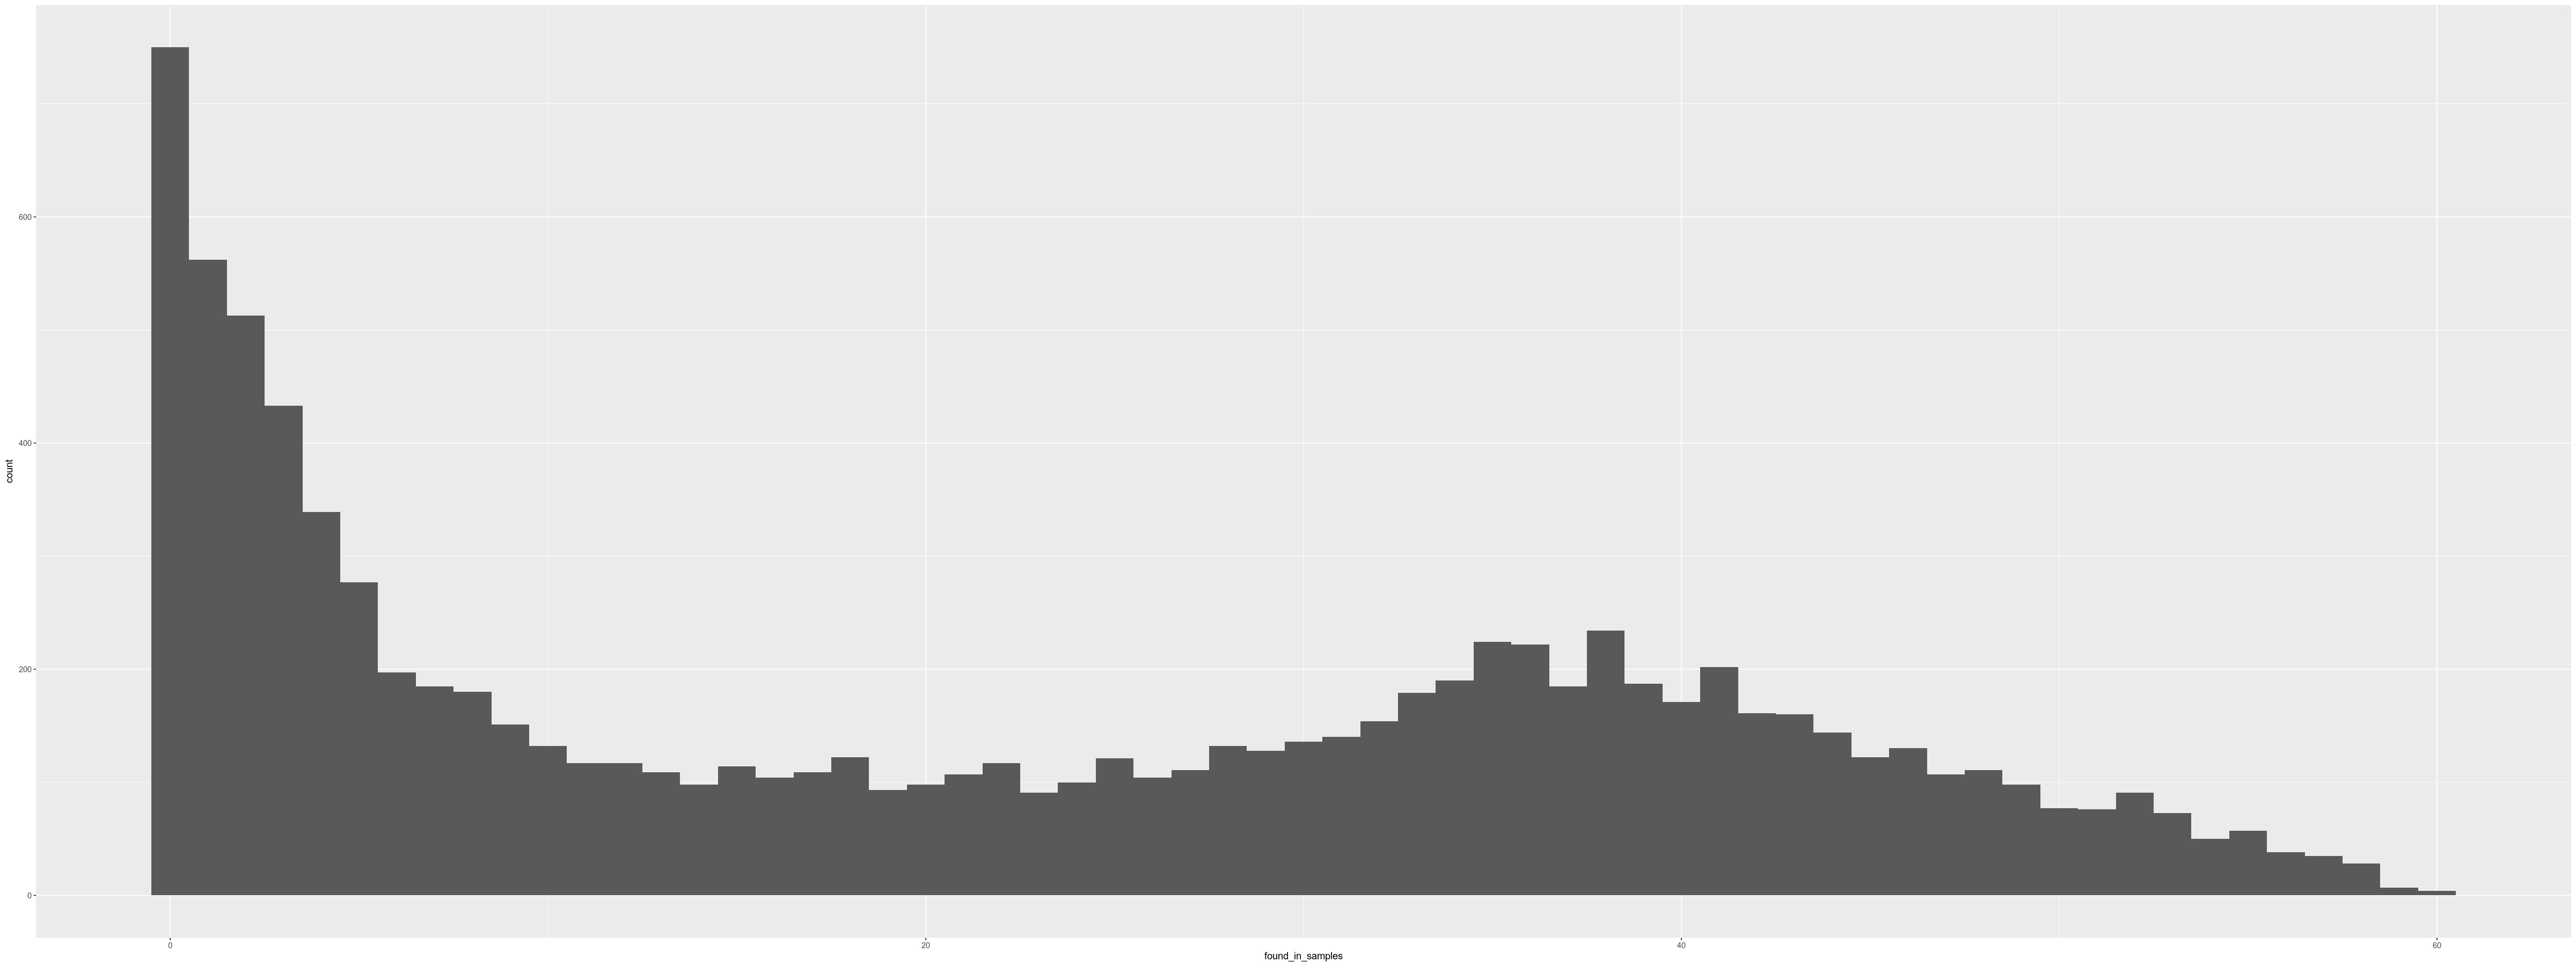

In [80]:
ggplot( HHMsFoundInSamples, aes(x=found_in_samples)) + geom_histogram(binwidth = 1)

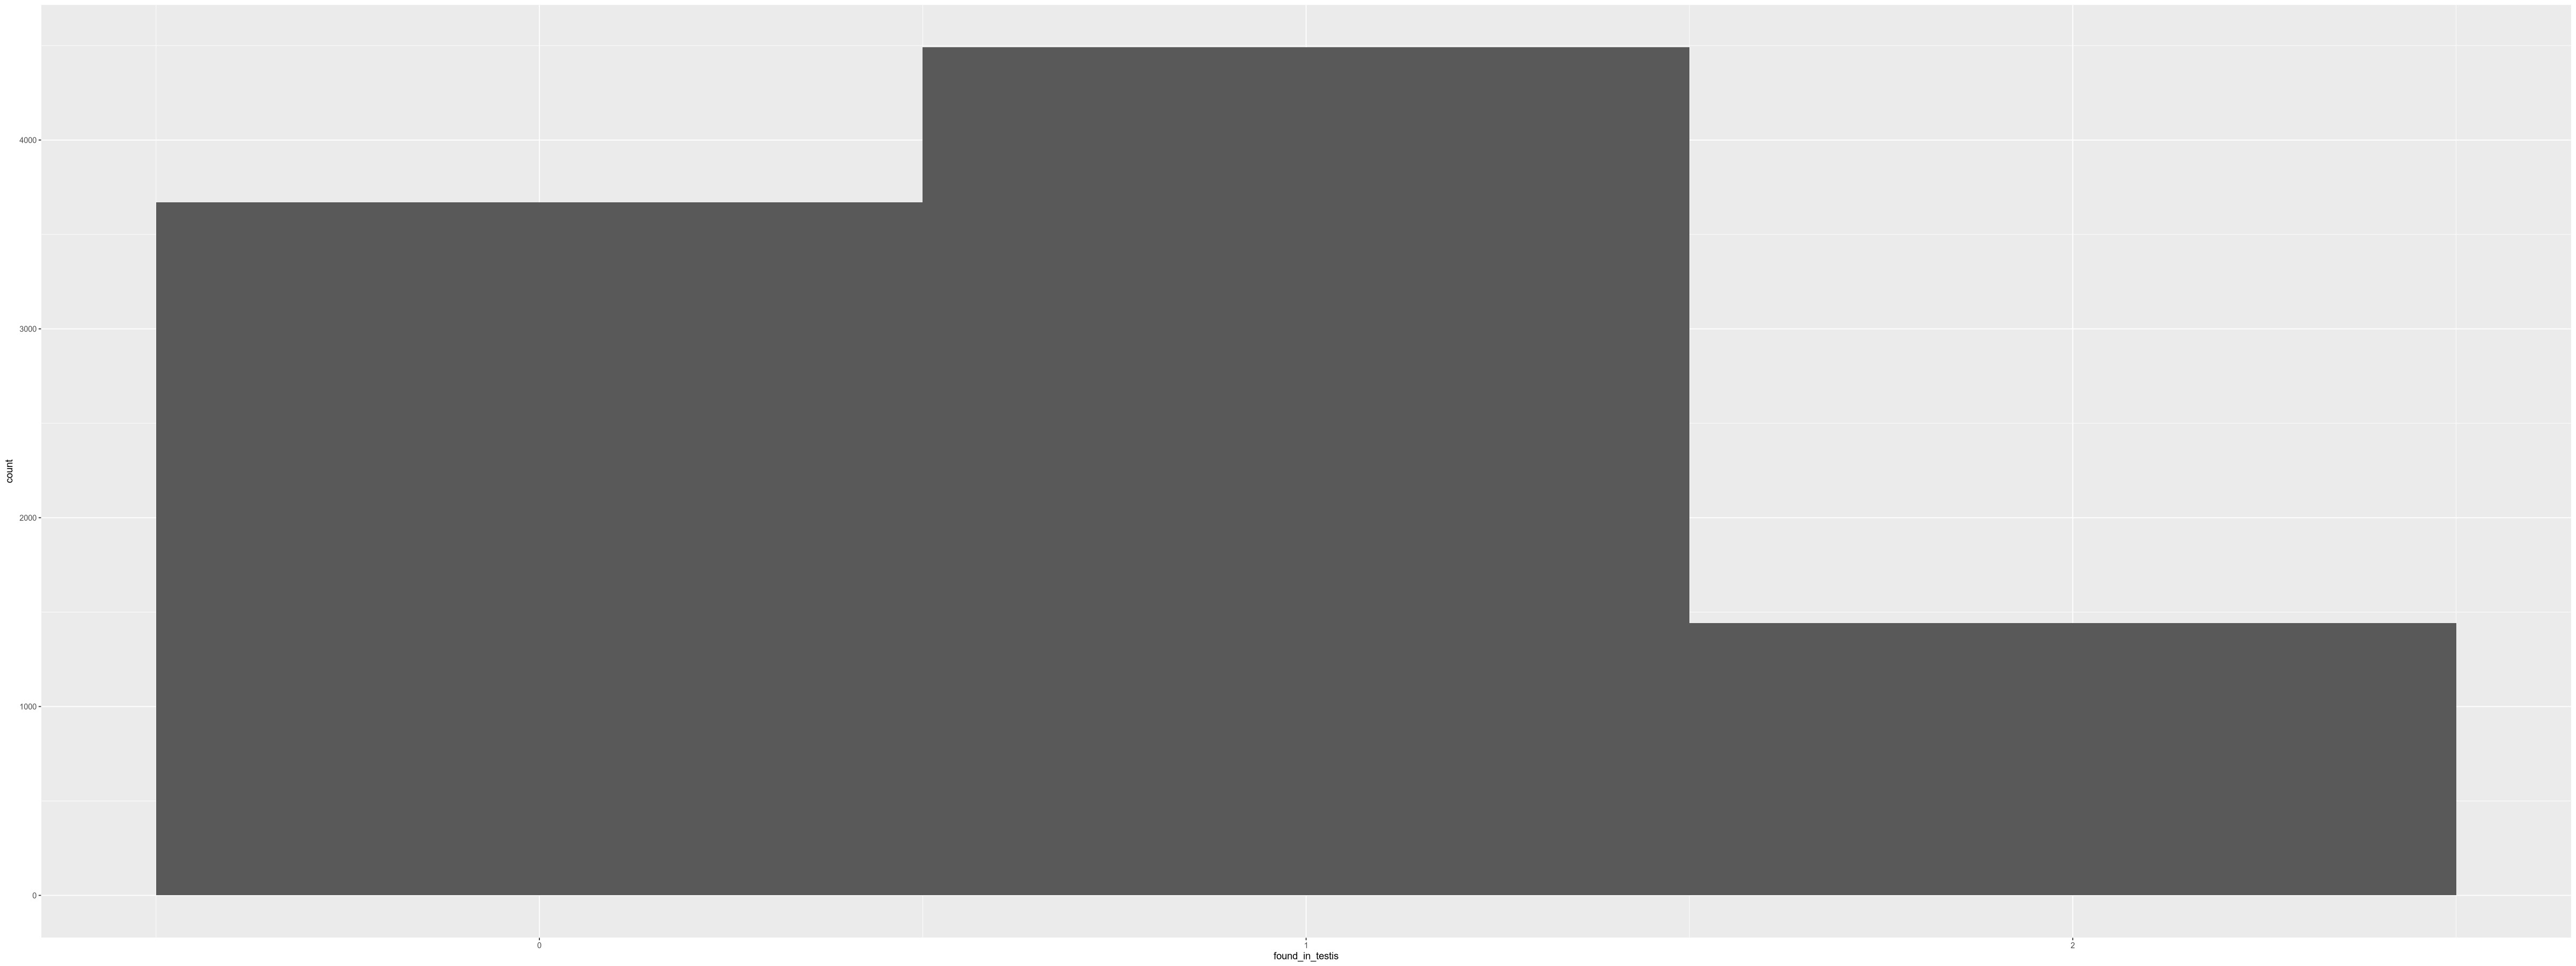

In [81]:
ggplot( HHMsFoundInSamples, aes(x=found_in_testis)) + geom_histogram(binwidth = 1)

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


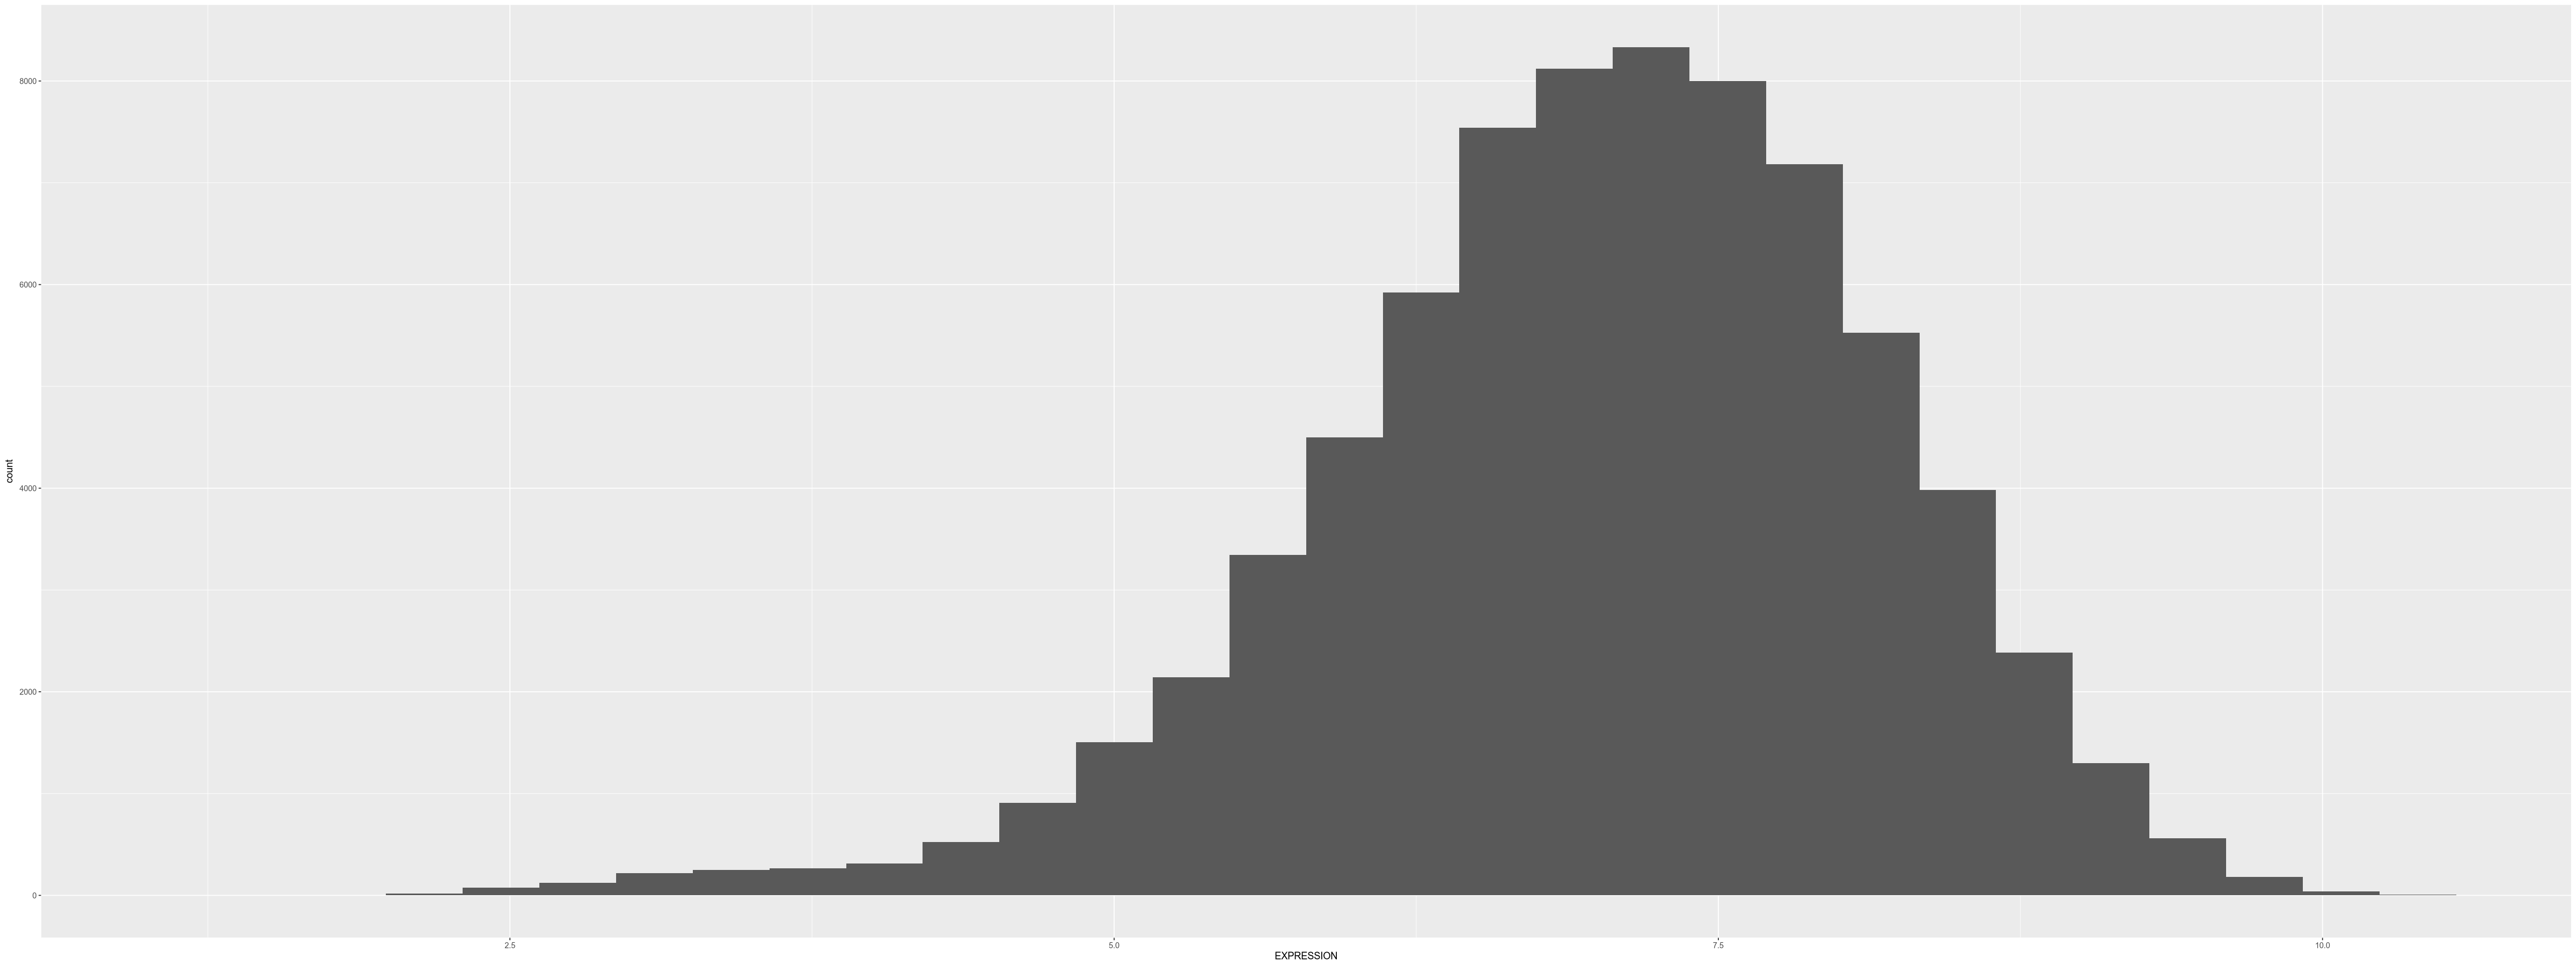

In [83]:
ggplot(expr_DF_tmp, aes(x=EXPRESSION)) + geom_histogram()

In [148]:
mycolors=c('#FF0000', '#0000FF', '#FFFF00', '#00FF00', '#FF00FF', '#FF8000', '#00FFFF', '#000000')
mylinetypes=1:5
mylinewidths=c(0.5, 1.5)
SamplesVisDF=expand.grid(color=mycolors, linetype=mylinetypes, linewidth=mylinewidths)
SamplesVisDF=SamplesVisDF[1:length(unique(expr_DF_good_detection$SAMPLE_ID)),]
SamplesVisDF$SAMPLE_ID=unique(expr_DF_good_detection$SAMPLE_ID)
SamplescolorList=as.list(setNames(as.character(SamplesVisDF$color),SamplesVisDF$SAMPLE_ID))
SampleLTList=as.list(setNames(SamplesVisDF$linetype,SamplesVisDF$SAMPLE_ID))
SampleLWList=as.list(setNames(SamplesVisDF$linewidth,SamplesVisDF$SAMPLE_ID))

SamplescolorVector=setNames(as.character(SamplesVisDF$color),SamplesVisDF$SAMPLE_ID)
SampleLTVector=setNames(SamplesVisDF$linetype,SamplesVisDF$SAMPLE_ID)
SampleLWVector=setNames(SamplesVisDF$linewidth,SamplesVisDF$SAMPLE_ID)


In [149]:
nrow(SamplesVisDF)

[1] 60

In [150]:
length(unique(expr_DF_good_detection$SAMPLE_ID))

[1] 60

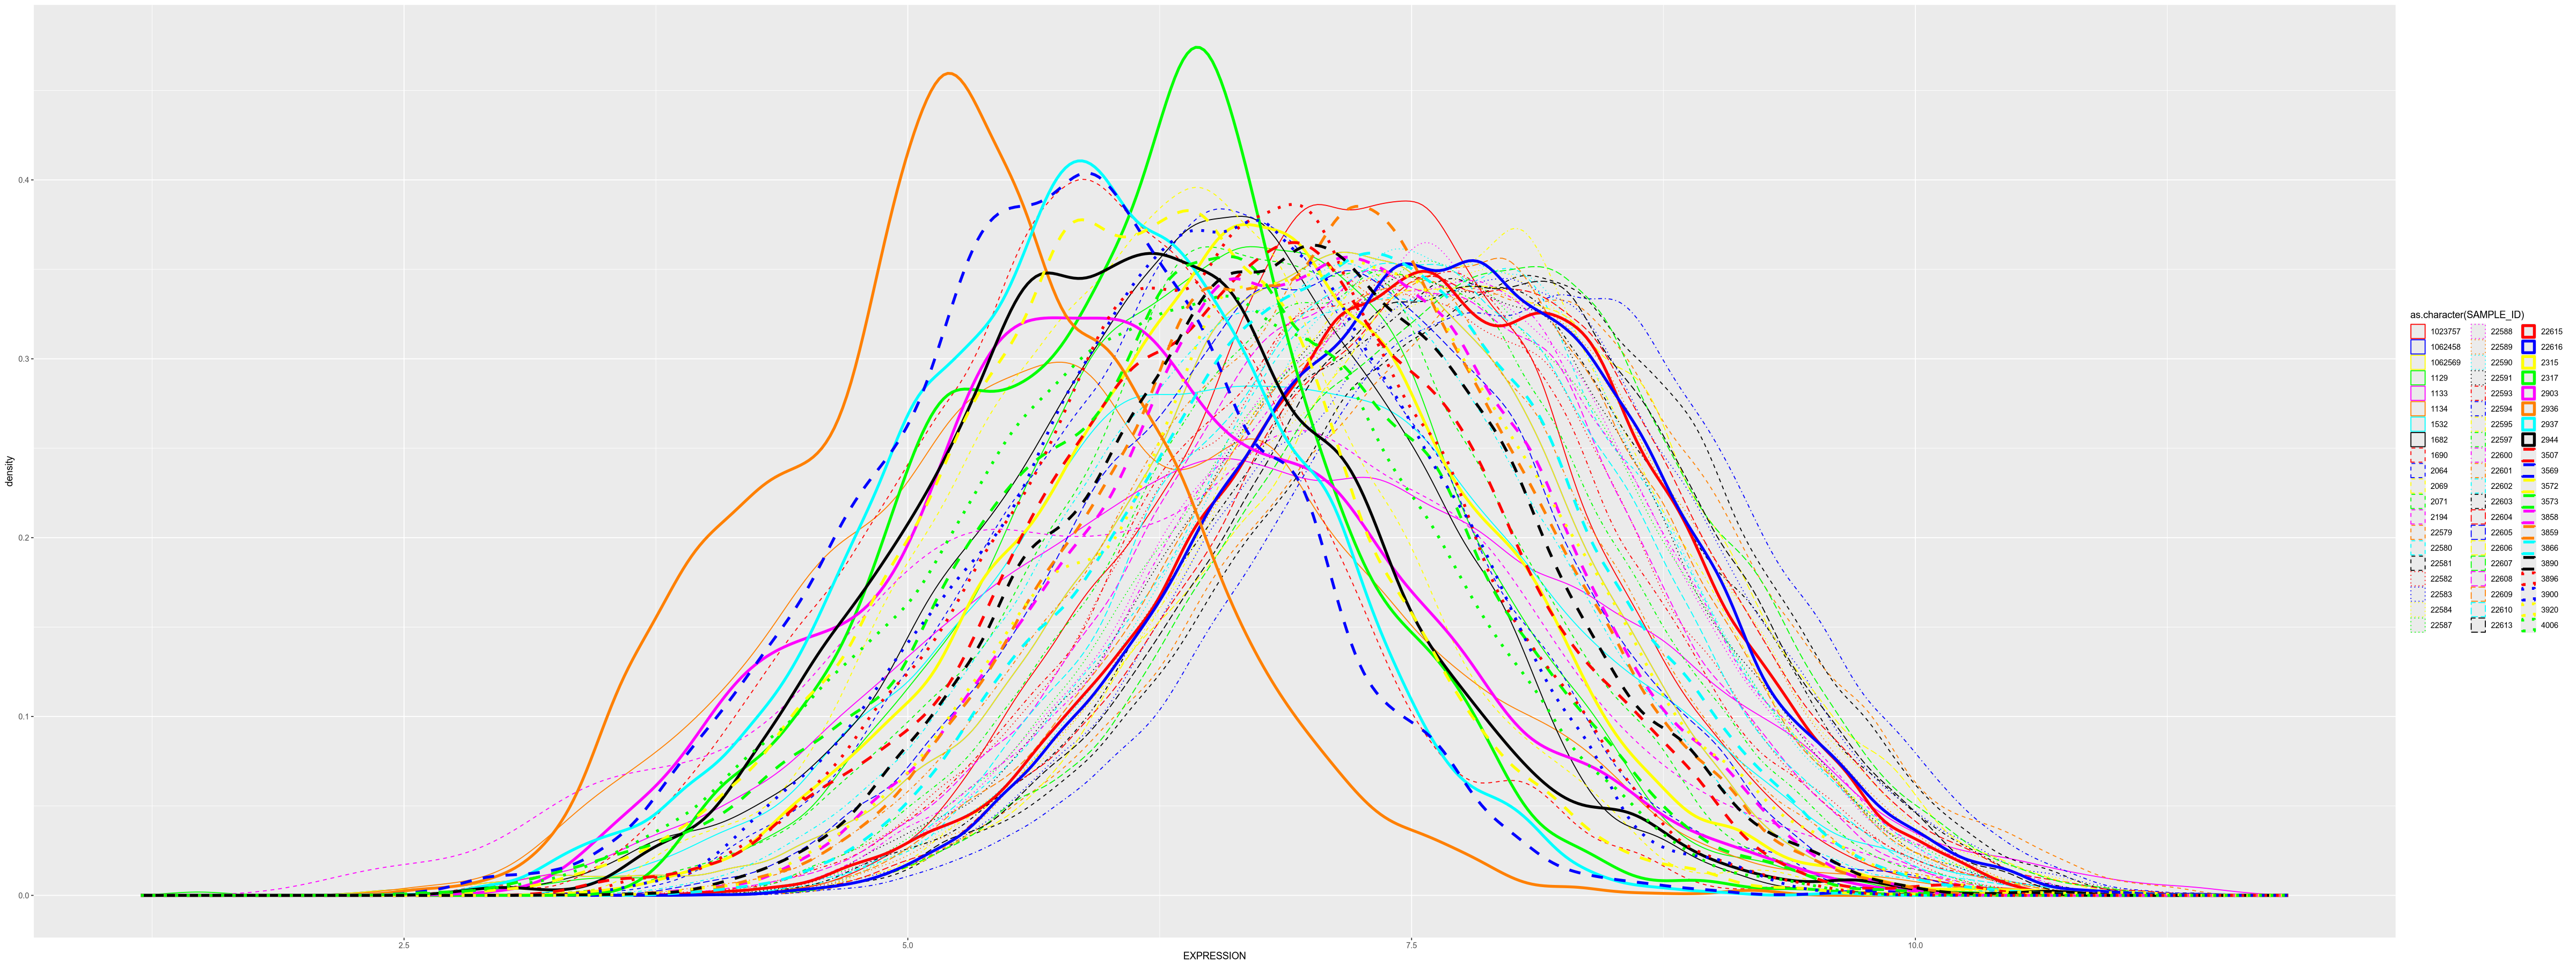

In [151]:
ggplot(expr_DF_good_detection, aes(x=EXPRESSION, color=as.character(SAMPLE_ID), linetype=as.character(SAMPLE_ID), linewidth=as.character(SAMPLE_ID) ))+
geom_density()+
scale_colour_manual(values = SamplescolorVector)+
scale_linetype_manual(values = SampleLTVector)+
scale_linewidth_manual(values = SampleLWVector)

In [152]:
tmp_df= expr_DF_good_detection %>% group_by(SAMPLE_ID) %>% summarise(meanExpr=mean(EXPRESSION)) %>% arrange(meanExpr)
tmp_df

SAMPLE_ID,meanExpr
<int>,<dbl>
2936,5.308185
3569,5.798688
2937,5.897265
1690,5.951175
1134,6.026041
2317,6.134934
2903,6.137229
3572,6.155467
2944,6.193998


In [135]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM interestinggenes'
interestingGenes=dbGetQuery(mydbRO, queryTxt)[[1]]

In [155]:
expr_DF_good_detection_TD=as.data.table(expr_DF_good_detection)
setkey(expr_DF_good_detection_TD, PROTEIN_ID)

In [157]:
expr_DF_good_detection_TD = merge(expr_DF_good_detection_TD, prot_DF_relevant_unique, by ="PROTEIN_ID" )


In [159]:
expr_DF_good_detection_TD = expr_DF_good_detection_TD[ expr_DF_good_detection_TD$ensembl_gene_id_united %in% HMMs, ]

In [164]:
setkey(expr_DF_good_detection_TD, SAMPLE_ID)

In [166]:
expr_DF_good_detection_TD = merge( expr_DF_good_detection_TD , found_proteinsDF_good_detection, by.x = "SAMPLE_ID", by.y="sample_id", all.x = TRUE, all.y = FALSE)


In [237]:
expr_DF_good_detection_TD_calc_m0 = expr_DF_good_detection_TD[ expr_DF_good_detection_TD$CALCULATION_METHOD==0,]
expr_DF_good_detection_TD_calc_m0 = expr_DF_good_detection_TD_calc_m0 %>% group_by(ensembl_gene_id_united) %>% filter(EXPRESSION == max(EXPRESSION)) %>% slice_sample(n = 1) %>% ungroup() %>% as.data.table()


In [238]:
setkey(expr_DF_good_detection_TD_calc_m0, SAMPLE_ID)

In [239]:
all_sample_IDS_tmp=unique(expr_DF_good_detection_TD_calc_m0$SAMPLE_ID)
for (tmp_sample_id in all_sample_IDS_tmp){
    message(tmp_sample_id)
    subset_TD=expr_DF_good_detection_TD_calc_m0[ expr_DF_good_detection_TD_calc_m0$SAMPLE_ID ==  tmp_sample_id,]
    tissue=subset_TD$tissue[1]
    tmp_not_found_HMMs=setdiff( HMMs,  subset_TD$ensembl_gene_id_united)
    message(paste("\t Adding rows: ", length(tmp_not_found_HMMs)))
    tmpColnames=colnames(subset_TD)
    tmpDT <- data.table(matrix(ncol = length(tmpColnames), nrow = length(tmp_not_found_HMMs)))
    colnames(tmpDT) <- tmpColnames
    tmpDT$ensembl_gene_id_united=tmp_not_found_HMMs
    tmpDT$EXPRESSION = 0
    tmpDT$SAMPLE_ID = rep( tmp_sample_id, nrow(tmpDT))
    tmpDT$tissue=rep( tissue, nrow(tmpDT))
    expr_DF_good_detection_TD_calc_m0 = rbind(expr_DF_good_detection_TD_calc_m0, tmpDT)

}

1129

	 Adding rows:  9594

1133

	 Adding rows:  9271

1134

	 Adding rows:  9589

1532

	 Adding rows:  9496

1682

	 Adding rows:  9599

1690

	 Adding rows:  9602

2069

	 Adding rows:  9600

2071

	 Adding rows:  9595

2194

	 Adding rows:  9603

2317

	 Adding rows:  9599

2903

	 Adding rows:  9586

2944

	 Adding rows:  9602

3507

	 Adding rows:  9600

3572

	 Adding rows:  9603

3573

	 Adding rows:  9602

3858

	 Adding rows:  9574

3859

	 Adding rows:  9573

3866

	 Adding rows:  9494

3890

	 Adding rows:  9591

3896

	 Adding rows:  9595

3900

	 Adding rows:  9593

3920

	 Adding rows:  9583

4006

	 Adding rows:  9596

22579

	 Adding rows:  9106

22580

	 Adding rows:  9487

22581

	 Adding rows:  8202

22582

	 Adding rows:  9559

22583

	 Adding rows:  9418

22584

	 Adding rows:  9503

22587

	 Adding rows:  9481

22588

	 Adding rows:  9418

22589

	 Adding rows:  9163

22590

	 Adding rows:  9249

22591

	 Adding rows:  9437

22593

	 Adding rows:  9529

22594

	

In [240]:
expr_DF_good_detection_TD_calc_m0$flagged_protein = FALSE
expr_DF_good_detection_TD_calc_m0$flagged_protein[ expr_DF_good_detection_TD_calc_m0$ensembl_gene_id_united %in% interestingGenes] = TRUE

In [248]:
myplots=list()
setkey(expr_DF_good_detection_TD_calc_m0, tissue)
for (tissue_tmp in unique(expr_DF_good_detection_TD_calc_m0$tissue)){
    message(tissue_tmp)
    tmpTD= expr_DF_good_detection_TD_calc_m0[ expr_DF_good_detection_TD_calc_m0$tissue == tissue_tmp, ]
    tmp_gg = ggplot(tmpTD, aes(x=flagged_protein, y=EXPRESSION)) + geom_violin() + ggtitle("tissue")
    myplots[[tissue]] = tmp_gg
    not_flagged=tmpTD$EXPRESSION[!tmpTD$flagged_protein]
    flagged=tmpTD$EXPRESSION[tmpTD$flagged_protein]
    ttestres_tmp=t.test(not_flagged, flagged)
    message(paste("\t", mean(not_flagged), mean(flagged),"p-val:", ttestres_tmp$p.value ))
}

B-lymphocyte

	 0.0213161963900999 0.0541296250888651 p-val: 0.546586281734365

LNCaP clone FGC

	 0.049305844206597 0.051324189201071 p-val: 0.968892512948383

Reh

	 0.0483988267415506 0 p-val: 0.000000000000000181597083334501

adipocyte

	 0.00858860320014619 0 p-val: 0.000154018781543979

adipose tissue

	 0.0996813882484651 0.135424357002782 p-val: 0.709828947910685

adrenal gland

	 0.128959948181777 0.126929781636826 p-val: 0.982103576202509

amniocyte

	 0.00323645543902211 0 p-val: 0.0458214761867069

ascites

	 0.00119481007613726 0 p-val: 0.162758284408471

blood platelet

	 0.247046398816413 0.270160641403663 p-val: 0.867780082701995

bone

	 0.00725171543411907 0 p-val: 0.00183504434409769

bone marrow

	 0.0963940328014189 0.0512949135725477 p-val: 0.387664144617351

brain

	 1.13402172864899 0.989711311139896 p-val: 0.553046609968475

breast

	 0.00291680645998495 0 p-val: 0.0272104772396186

cardia

	 0.000580089093164498 0 p-val: 0.317336023453481

cerumen

	 0.0027859

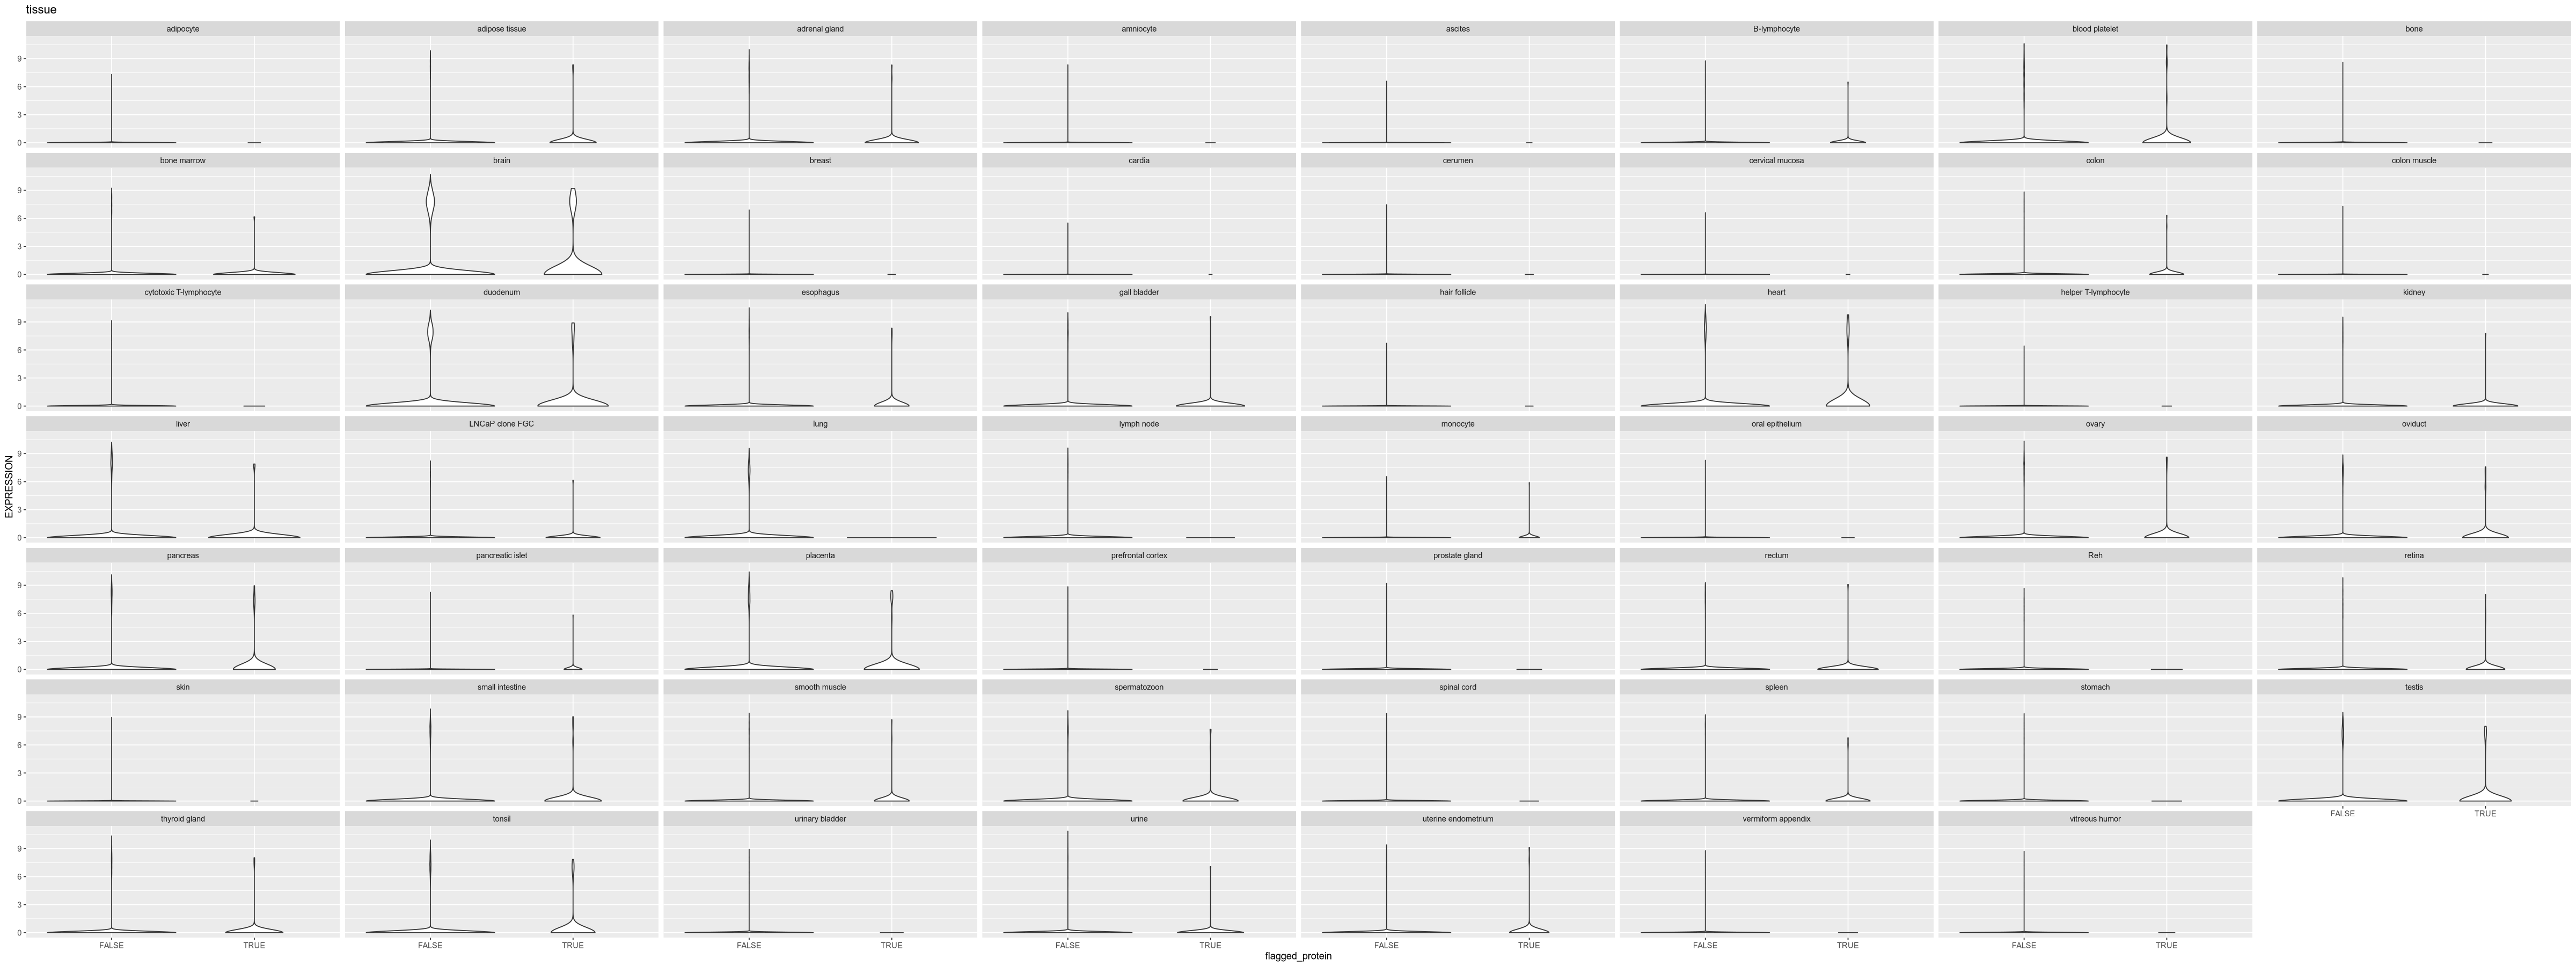

In [242]:
ggplot(expr_DF_good_detection_TD_calc_m0, aes(x=flagged_protein, y=EXPRESSION)) + geom_violin() + ggtitle("tissue") + facet_wrap(~tissue)

In [249]:
testis_expr=expr_DF_good_detection_TD_calc_m0[ expr_DF_good_detection_TD_calc_m0$tissue=="testis", ]

In [250]:
length(interestingGenes)

[1] 120

In [251]:
testis_expr_flag=testis_expr[ testis_expr$flagged_protein, ]

In [252]:
table(testis_expr_flag$ensembl_gene_id_united)


ENSG00000001626 ENSG00000029559 ENSG00000057935 ENSG00000079308 ENSG00000081014 
              1               1               1               1               1 
ENSG00000082805 ENSG00000085224 ENSG00000086205 ENSG00000091651 ENSG00000094841 
              1               1               1               1               1 
ENSG00000096696 ENSG00000100731 ENSG00000101040 ENSG00000101938 ENSG00000102038 
              1               1               1               1               1 
ENSG00000107863 ENSG00000107864 ENSG00000109184 ENSG00000110107 ENSG00000111701 
              1               1               1               1               1 
ENSG00000111879 ENSG00000112167 ENSG00000113240 ENSG00000113583 ENSG00000114544 
              1               1               1               1               1 
ENSG00000114648 ENSG00000114767 ENSG00000115085 ENSG00000115364 ENSG00000115806 
              1               1               1               1               1 
ENSG00000115840 ENSG0000011

In [260]:
message(paste0(paste0(testis_expr_flag$EXPRESSION[order(testis_expr_flag$ensembl_gene_id_united)], "\t", testis_expr_flag$ensembl_gene_id_united[order(testis_expr_flag$ensembl_gene_id_united)]), collapse = "\n"))

0	ENSG00000001626
0	ENSG00000029559
0	ENSG00000057935
0	ENSG00000079308
0	ENSG00000081014
0	ENSG00000082805
0	ENSG00000085224
0	ENSG00000086205
0	ENSG00000091651
7.9950041319674	ENSG00000094841
0	ENSG00000096696
0	ENSG00000100731
0	ENSG00000101040
0	ENSG00000101938
0	ENSG00000102038
0	ENSG00000107863
0	ENSG00000107864
0	ENSG00000109184
0	ENSG00000110107
0	ENSG00000111701
0	ENSG00000111879
0	ENSG00000112167
0	ENSG00000113240
0	ENSG00000113583
0	ENSG00000114544
0	ENSG00000114648
0	ENSG00000114767
0	ENSG00000115085
0	ENSG00000115364
0	ENSG00000115806
0	ENSG00000115840
0	ENSG00000115993
0	ENSG00000116147
0	ENSG00000116793
0	ENSG00000116871
0	ENSG00000117477
0	ENSG00000118690
0	ENSG00000119041
6.07119832409893	ENSG00000121621
0	ENSG00000122547
0	ENSG00000122591
0	ENSG00000122678
0	ENSG00000123901
0	ENSG00000124275
0	ENSG00000124370
0	ENSG00000124678
0	ENSG00000126947
0	ENSG00000127311
0	ENSG00000128731
0	ENSG00000129521
7.34279747875293	ENSG00000130119
0	ENSG00000130385
0	ENSG00000131067
0	

# Computer vision

In [69]:
queryTxt='SELECT * FROM interestinggenes'
interestingGenesDF=dbGetQuery(mydbRO, queryTxt)

In [70]:
library(xml2)

read_tree_svg=function(inHMMid){
    inSVG=sprintf("~/data/lambda/output/step9Trees/%s.svg", inHMMid)
    xml_svg=read_xml(inSVG)
    xml_ns_strip(xml_svg)
    rects <- xml_find_all(xml_svg, ".//rect")
    rect_df <- data.frame(x = as.numeric(xml_attr(rects, "x")), 
                          y = as.numeric(xml_attr(rects, "y")), 
                          width = as.numeric(xml_attr(rects, "width")), 
                          height = as.numeric(xml_attr(rects, "height")), 
                          style = xml_attr(rects, "style"), stringsAsFactors = FALSE )
    rect_df=rect_df[ ! ( is.na(rect_df$x) | is.na(rect_df$y) | is.na(rect_df$width) | is.na(rect_df$height) | is.na(rect_df$style)), ]
    popular_xs=table(rect_df$x)
    top3_xs=as.numeric(names(sort(popular_xs, decreasing = TRUE)[1:3]))
    relevant_rects=rect_df[ rect_df$x %in% top3_xs,]
    if (length(table(relevant_rects$width))!= 1 || length(table(relevant_rects$height))!=1) message("PROBLEM: ", inSVG)
    
    # shifting coords
    relevant_rects$x=relevant_rects$x-min(relevant_rects$x)+min(relevant_rects$width)/2
    relevant_rects$y=relevant_rects$y-min(relevant_rects$y)+min(relevant_rects$height)/2
    return(relevant_rects)
}

In [71]:
read_clusters_svg=function(inHMMid){
    inSVG=sprintf("~/data/lambda/output/scratches/clustering/%s.svg", inHMMid)
    xml_svg=read_xml(inSVG)
    xml_ns_strip(xml_svg)
    clusters_w=as.numeric(str_remove(xml_attr(xml_svg, 'width'), "pt"))
    clusters_h=as.numeric(str_remove(xml_attr(xml_svg, 'height'), "pt"))
    tmp_node=xml_svg
    clusters_SVG_content=as.character(xml_find_all(xml_svg, "//g[count(*) > 50]"))
    
    rects_df=read_tree_svg(inHMMid)
    rects_df$x=rects_df$x+clusters_w

    combined_w=max(rects_df$x) + max(rects_df$width)
    combined_h=max(max(rects_df$y + rects_df$height), clusters_h)
    message(combined_w,"x", combined_h)

    svg_header=sprintf("<?xml version='1.0' encoding='UTF-8' ?>
<svg xmlns='http://www.w3.org/2000/svg' xmlns:xlink='http://www.w3.org/1999/xlink' width='%fpt' height='%f.00pt' viewBox='0 0 %f %f'>
<g class='svglite'>
<defs>
  <style type='text/css'><![CDATA[
    .svglite line, .svglite polyline, .svglite polygon, .svglite path, .svglite rect, .svglite circle {
      fill: none;
      stroke: #000000;
      stroke-linecap: round;
      stroke-linejoin: round;
      stroke-miterlimit: 10.00;
    }
    .svglite text {
      white-space: pre;
    }
    .svglite g.glyphgroup path {
      fill: inherit;
      stroke: none;
    }
  ]]></style>
</defs>", combined_w, combined_h, combined_w, combined_h )

    rect_svg_lines=sprintf("<rect x='%f' y='%f' width='%f' height='%f' style='%s' />", rects_df$x, rects_df$y, rects_df$width, rects_df$height, rects_df$style )
    svg_tail="</g></svg>"
    svg_code=c(svg_header, clusters_SVG_content, rect_svg_lines, svg_tail)
    writeLines(svg_code, paste0("~/data/lambda/output/scratches/clustering_debug/", inHMMid, ".svg"))
}

In [72]:
system("mkdir -p ~/data/lambda/output/scratches/clustering_debug", wait = TRUE)

for (HHMid in interestingGenesDF$ensembl_gene_id){
    read_clusters_svg(HHMid)
}


Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
1879.68x2661.08

Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
1879.68x2660.61

Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
1879.68x2661.08

Warning message in data.frame(x = as.numeric(xml_attr(rects, "x")), y = as.numeric(xml_attr(rects, :
“NAs introduced by coercion”
Warning message in data.frame(x = as.nu

In [73]:
interestingGenesDF

ensembl_gene_id,is50Kresult
<chr>,<int>
ENSG00000001626,0
ENSG00000029559,0
ENSG00000081014,0
ENSG00000091651,0
ENSG00000094841,1
ENSG00000111701,0
ENSG00000111879,0
ENSG00000112167,0
ENSG00000114767,0


In [61]:
read_tree_svg('')

{xml_nodeset (2)}
[1] <g clip-path="url(#cpMzUuNTZ8MTEzNC44N3wyMy4xOHwxMDQ4LjUw)">\n  <rect x=" ...
[2] <g clip-path="url(#cpMC4wMHwxNDQwLjAwfDAuMDB8MTA4MC4wMA==)">\n  <text x=" ...

In [95]:
xml_svg

{xml_document}
<svg width="1440.00pt" height="1080.00pt" viewBox="0 0 1440.00 1080.00" xmlns:xlink="http://www.w3.org/1999/xlink">
[1] <g class="svglite">\n  <defs>\n    <style type="text/css"><![CDATA[\n     ...

In [2]:
interestingGenes

ERROR: Error: object 'interestingGenes' not found


# mRNA expression

In [2]:
queryTxt='SELECT COUNT( DISTINCT ensembl_gene_id ) FROM HomologyBijectiveWellDefined'
tmpDF=dbGetQuery(mydbRO, queryTxt)
tmpDF

COUNT( DISTINCT ensembl_gene_id )
<int>
9754


In [3]:
queryTxt='SELECT * FROM interestinggenes'
interestingGenesDF=dbGetQuery(mydbRO, queryTxt)

## Gene names as shown in human gtf

In [4]:
queryTxt='SELECT * FROM GeneNameSynonims WHERE ensembl_gene_id IN (SELECT ensembl_gene_id FROM interestinggenes)'
interestingGenesSynonyms=dbGetQuery(mydbRO, queryTxt)

In [5]:
length(unique(interestingGenesSynonyms$ensembl_gene_id))

[1] 42

In [6]:
hg38_gtf_data <- import("~/data/genomes/hg38/hg38.refGene.gtf")


In [7]:
found_gene_common_names=unique(hg38_gtf_data$gene_id)

In [8]:
interestingGenesSynonyms_hg38=interestingGenesSynonyms[ interestingGenesSynonyms$synonym %in% found_gene_common_names, ]

In [9]:
interestingGenesSynonyms_hg38= interestingGenesSynonyms_hg38[, c("synonym", "ensembl_gene_id")]

In [10]:
interestingGenesSynonyms_hg38=unique(interestingGenesSynonyms_hg38)

In [11]:
interestingGenesSynonyms_hg38=interestingGenesSynonyms_hg38[, c(2,1)]

In [12]:
interestingGenesSynonyms_hg38=interestingGenesSynonyms_hg38[ order(interestingGenesSynonyms_hg38$ensembl_gene_id),]

In [13]:
any(table(interestingGenesSynonyms_hg38$ensembl_gene_id)>1)

[1] FALSE

In [17]:
write.csv(interestingGenesSynonyms_hg38, "~/data/lambda/output/scratches/interestingGenesSynonyms_hg38.csv")

## GTEx

In [14]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM HMMstats5MB'
HMMs=dbGetQuery(mydbRO, queryTxt)[[1]]


In [15]:
GTExDF=read.table("~/data/lambda/output/scratches/GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct", header = TRUE, sep="\t", skip = 2)

In [16]:
GTExDF$Description=NULL

In [17]:
GTExDF$Name=gsub(pattern = "\\.\\d+$", replacement = "", x = GTExDF$Name)
rownames(GTExDF)=GTExDF$Name
GTExDF$Name=NULL

In [18]:
ncol(GTExDF)

[1] 68

In [19]:
colnames(GTExDF)

[1] "Adipose_Subcutaneous"                             
 [2] "Adipose_Visceral_Omentum"                         
 [3] "Adrenal_Gland"                                    
 [4] "Artery_Aorta"                                     
 [5] "Artery_Coronary"                                  
 [6] "Artery_Tibial"                                    
 [7] "Bladder"                                          
 [8] "Brain_Amygdala"                                   
 [9] "Brain_Anterior_cingulate_cortex_BA24"             
[10] "Brain_Caudate_basal_ganglia"                      
[11] "Brain_Cerebellar_Hemisphere"                      
[12] "Brain_Cerebellum"                                 
[13] "Brain_Cortex"                                     
[14] "Brain_Frontal_Cortex_BA9"                         
[15] "Brain_Hippocampus"                                
[16] "Brain_Hypothalamus"                               
[17] "Brain_Nucleus_accumbens_basal_ganglia"            
[18] "Brain_Putamen_basal_ganglia"                      
[19] "Brain_Spinal_cord_cervical_c.1"                   
[20] "Brain_Substantia_nigra"                           
[21] "Breast_Mammary_Tissue"                            
[22] "Cells_Cultured_fibroblasts"                       
[23] "Cells_EBV.transformed_lymphocytes"                
[24] "Cervix_Ectocervix"                                
[25] "Cervix_Endocervix"                                
[26] "Colon_Sigmoid"                                    
[27] "Colon_Transverse"                                 
[28] "Colon_Transverse_Mixed_Cell"                      
[29] "Colon_Transverse_Mucosa"                          
[30] "Colon_Transverse_Muscularis"                      
[31] "Esophagus_Gastroesophageal_Junction"              
[32] "Esophagus_Mucosa"                                 
[33] "Esophagus_Muscularis"                             
[34] "Fallopian_Tube"                                   
[35] "Heart_Atrial_Appendage"                           
[36] "Heart_Left_Ventricle"                             
[37] "Kidney_Cortex"                                    
[38] "Kidney_Medulla"                                   
[39] "Liver"                                            
[40] "Liver_Hepatocyte"                                 
[41] "Liver_Mixed_Cell"                                 
[42] "Liver_Portal_Tract"                               
[43] "Lung"                                             
[44] "Minor_Salivary_Gland"                             
[45] "Muscle_Skeletal"                                  
[46] "Nerve_Tibial"                                     
[47] "Ovary"                                            
[48] "Pancreas"                                         
[49] "Pancreas_Acini"                                   
[50] "Pancreas_Islets"                                  
[51] "Pancreas_Mixed_Cell"                              
[52] "Pituitary"                                        
[53] "Prostate"                                         
[54] "Skin_Not_Sun_Exposed_Suprapubic"                  
[55] "Skin_Sun_Exposed_Lower_leg"                       
[56] "Small_Intestine_Terminal_Ileum"                   
[57] "Small_Intestine_Terminal_Ileum_Lymphoid_Aggregate"
[58] "Small_Intestine_Terminal_Ileum_Mixed_Cell"        
[59] "Spleen"                                           
[60] "Stomach"                                          
[61] "Stomach_Mixed_Cell"                               
[62] "Stomach_Mucosa"                                   
[63] "Stomach_Muscularis"                               
[64] "Testis"                                           
[65] "Thyroid"                                          
[66] "Uterus"                                           
[67] "Vagina"                                           
[68] "Whole_Blood"

In [20]:
GTExDF_subset=GTExDF[HMMs, ]

In [21]:
nrow(GTExDF_subset)

[1] 9518

In [22]:
GTExDF_subset_t=t(GTExDF_subset)

In [23]:
GTExDF_subset_t_scaled=scale(GTExDF_subset_t)

In [24]:
GTExDF_testis = GTExDF_subset_t_scaled["Testis",]

In [25]:
GTExDF_testis_interesting = GTExDF_testis[ names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id]
GTExDF_testis_interesting_not50K = GTExDF_testis[ names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id[ interestingGenesDF$is50Kresult == 0]]

In [26]:
GTExDF_testis_interesting

ENSG00000001626 ENSG00000029559 ENSG00000081014 ENSG00000091651 ENSG00000094841 
   -0.220843312     0.054782498     0.435701020     3.545630865    -1.923746906 
ENSG00000111701 ENSG00000111879 ENSG00000112167 ENSG00000114767 ENSG00000115085 
   -0.171752713     4.558387106     7.592059721     0.392581151    -0.144663359 
ENSG00000115364 ENSG00000115840 ENSG00000115993 ENSG00000116793 ENSG00000118690 
   -0.230225068    -0.725282805    -0.651859943     2.965146358     7.045716904 
ENSG00000121621 ENSG00000123901 ENSG00000124370 ENSG00000124678 ENSG00000130119 
    5.052802192    -0.049528565    -0.992810496     8.124934114    -0.671262016 
ENSG00000130385 ENSG00000133997 ENSG00000135324 ENSG00000135355 ENSG00000136319 
    7.993853176     0.394188974    -0.125646419     8.124417468     2.861659404 
ENSG00000139921 ENSG00000144644 ENSG00000144848 ENSG00000151131 ENSG00000151876 
   -0.213171337     0.009304157     5.214161794     0.441717603     1.494761914 
ENSG00000152990 ENSG00000163012 ENSG00000164082 ENSG00000166133 ENSG00000167769 
   -0.304600700     8.014398104     5.649932897     1.146046215    -0.072617009 
ENSG00000170289 ENSG00000170500 ENSG00000177103 ENSG00000177575 ENSG00000183060 
    7.189826208    -0.378504631     0.463402104    -0.495569516     1.176994568 
ENSG00000188282 ENSG00000203760 
   -0.162380196     4.233220252

In [27]:
GTExDF_testis_other = GTExDF_testis[! names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id]

In [28]:
GTExDF_summary=data.frame(ensembl_gene_id=names(GTExDF_testis), zscore=GTExDF_testis, interesting=names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id, interesting_not50K= names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id[ interestingGenesDF$is50Kresult == 0]  )

In [29]:
table(GTExDF_summary$interesting)


FALSE  TRUE 
 9476    42 

In [30]:
nrow(GTExDF_summary)

[1] 9518

Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_ydensity()`).”


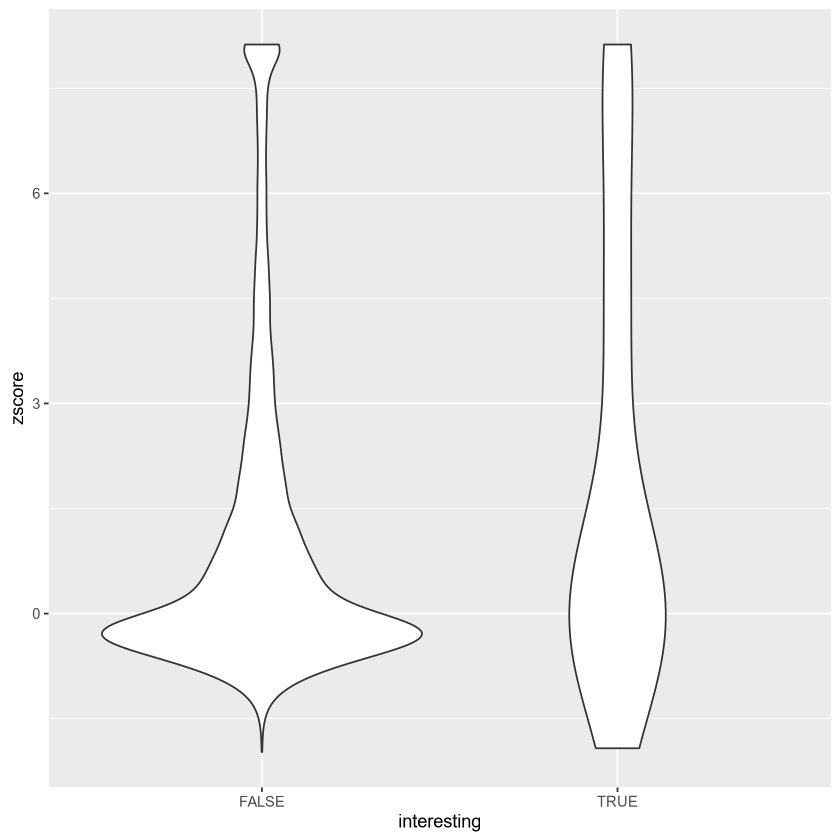

In [31]:
ggplot(GTExDF_summary, aes(x=interesting, y=zscore)) + geom_violin()

In [32]:
library(ggsignif)


Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_signif()`).”


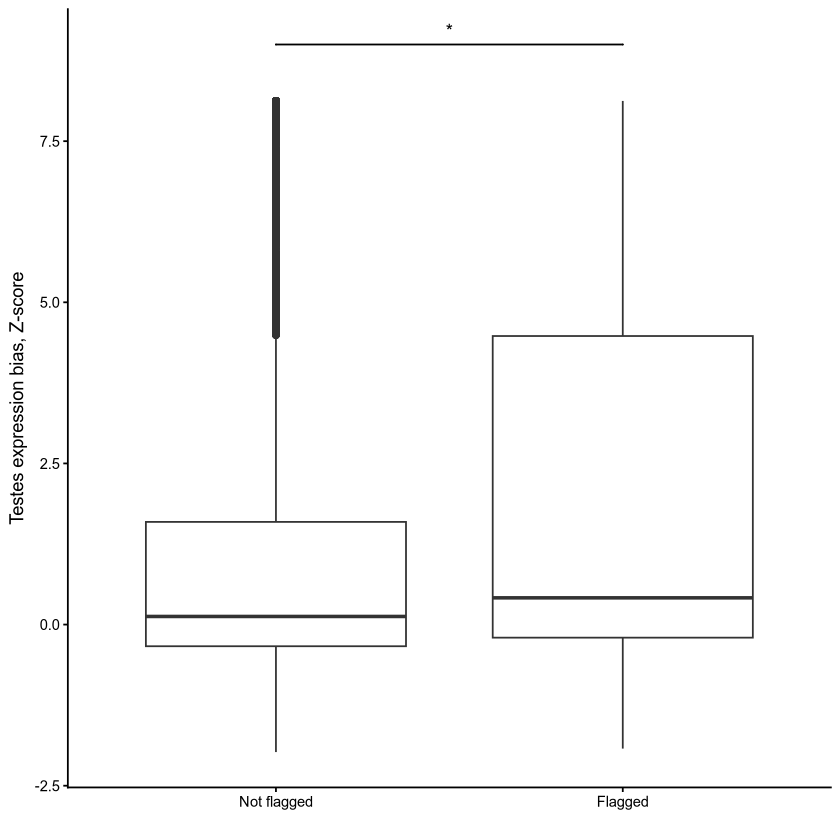

In [38]:
bplot=ggplot(GTExDF_summary, aes(x=interesting, y=zscore)) + geom_boxplot() + scale_x_discrete(labels=c("Not flagged", "Flagged"))+ ylab("Testes expression bias, Z-score") + xlab("") +
geom_signif(
    y_position = 9, xmin = 1, xmax = 2,
    annotation = "*", tip_length = 0
  ) + theme_classic()
bplot

In [39]:
source(here::here('MG3.functions9.R')) # reloading the get the handles created


In [40]:
saveFigurePlain(GGfigure = bplot, figName = "testes_expression_boxplot", outputDir = "~/data/lambda/output/", width.in = 8, height.in = 6)

Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_signif()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_signif()`).”
101296



Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_ydensity()`).”


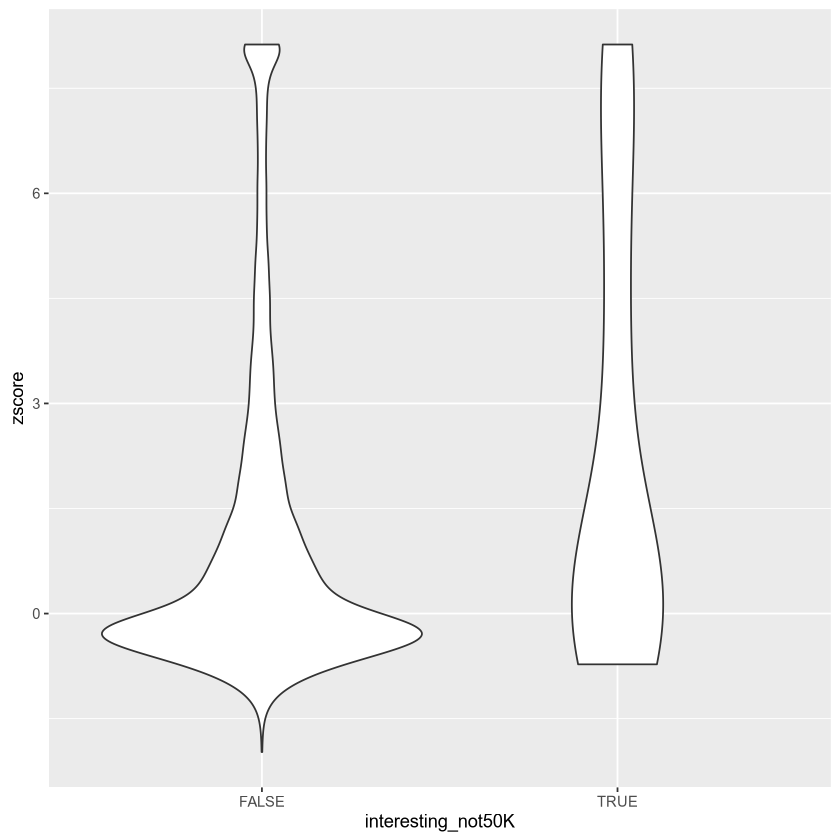

In [67]:
ggplot(GTExDF_summary, aes(x=interesting_not50K, y=zscore)) + geom_violin()

In [68]:
t.test(GTExDF_testis_interesting, GTExDF_testis_other)


	Welch Two Sample t-test

data:  GTExDF_testis_interesting and GTExDF_testis_other
t = 2.039, df = 41.185, p-value = 0.0479
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 0.009602951 1.972656223
sample estimates:
mean of x mean of y 
 2.062885  1.071755 


In [69]:
t.test(GTExDF_testis_interesting, GTExDF_testis_other, alternative = "greater")


	Welch Two Sample t-test

data:  GTExDF_testis_interesting and GTExDF_testis_other
t = 2.039, df = 41.185, p-value = 0.02395
alternative hypothesis: true difference in means is greater than 0
95 percent confidence interval:
 0.1731995       Inf
sample estimates:
mean of x mean of y 
 2.062885  1.071755 


In [114]:
t.test(GTExDF_testis_interesting_not50K, GTExDF_testis_other)


	Welch Two Sample t-test

data:  GTExDF_testis_interesting_not50K and GTExDF_testis_other
t = 2.2251, df = 30.098, p-value = 0.03371
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 0.1042104 2.4279061
sample estimates:
mean of x mean of y 
 2.335489  1.069430 


In [117]:
wilcox.test(GTExDF_testis_interesting_not50K, GTExDF_testis_other)


	Wilcoxon rank sum test with continuity correction

data:  GTExDF_testis_interesting_not50K and GTExDF_testis_other
W = 184373, p-value = 0.01826
alternative hypothesis: true location shift is not equal to 0


In [179]:
wilcox.test(GTExDF_testis_interesting_not50K, GTExDF_testis_other, alternative = "greater")


	Wilcoxon rank sum test with continuity correction

data:  GTExDF_testis_interesting_not50K and GTExDF_testis_other
W = 184373, p-value = 0.009131
alternative hypothesis: true location shift is greater than 0


In [119]:
wilcox.test(GTExDF_testis_interesting, GTExDF_testis_other)


	Wilcoxon rank sum test with continuity correction

data:  GTExDF_testis_interesting and GTExDF_testis_other
W = 231237, p-value = 0.08733
alternative hypothesis: true location shift is not equal to 0


In [180]:
wilcox.test(GTExDF_testis_interesting, GTExDF_testis_other, alternative = "greater")


	Wilcoxon rank sum test with continuity correction

data:  GTExDF_testis_interesting and GTExDF_testis_other
W = 231237, p-value = 0.04367
alternative hypothesis: true location shift is greater than 0


In [116]:
GTExDF_summary_interesting = GTExDF_summary[ GTExDF_summary$interesting,]

In [63]:
GTExDF_summary_interesting=GTExDF_summary_interesting[order(GTExDF_summary_interesting$ensembl_gene_id),]

In [64]:
write.csv(GTExDF_summary_interesting, "~/data/lambda/output/scratches/GTExDF_summary_interesting.csv")

In [65]:
GTExDF_interesting=GTExDF[interestingGenesDF$ensembl_gene_id, ]

In [66]:
GTExDF_interesting_only_testis=data.frame(ensembl_gene_id=rownames(GTExDF_interesting), TMP=GTExDF_interesting$Testis)

In [67]:
GTExDF_interesting_only_testis=GTExDF_interesting_only_testis[order(GTExDF_interesting_only_testis$ensembl_gene_id),]

In [68]:

write.csv(GTExDF_interesting_only_testis, "~/data/lambda/output/scratches/GTExDF_interesting_only_testis.csv")

# Extra sRNA seq 

In [122]:
library(xml2)

xml_sra=read_xml("~/data/lambda//verification//SraExperimentPackage-2.xml")

xml_ns_strip(xml_sra)

In [123]:
xml_sra

{xml_document}
<EXPERIMENT_PACKAGE_SET>
 [1] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32082351" alias="WNB-B ...
 [2] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32082350" alias="WNB-B ...
 [3] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32082349" alias="WNB-B ...
 [4] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32082348" alias="XMB-B ...
 [5] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32082345" alias="XMB-B ...
 [6] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32082344" alias="XMB-B ...
 [7] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32042779" alias="Young ...
 [8] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32042778" alias="Young ...
 [9] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32042777" alias="Young ...
[10] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32042776" alias="Aged3 ...
[11] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX32042773" alias="Aged2 ...
[12] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX320

In [135]:
EXPERIMENT_Ps <- xml_find_all(xml_sra, ".//EXPERIMENT_PACKAGE")

In [138]:
xml_children(xml_children(EXPERIMENT_Ps[[1]])[[7]])[[1]]

{xml_node}
<RUN accession="SRR37140349" alias="WNB-BF3.fq" total_spots="11346493" total_bases="567324650" size="192470745" load_done="true" published="2026-02-06 06:37:57" is_public="true" cluster_name="public" has_taxanalysis="1" static_data_available="1">
[1] <IDENTIFIERS>\n  <PRIMARY_ID>SRR37140349</PRIMARY_ID>\n  <SUBMITTER_ID na ...
[2] <EXPERIMENT_REF accession="SRX32082351">\n  <IDENTIFIERS>\n    <SUBMITTER ...
[3] <Pool>\n  <Member member_name="" accession="SRS28017568" sample_name="WNB ...
[4] <SRAFiles>\n  <SRAFile cluster="public" filename="WNB-BF3.fq" size="17932 ...
[5] <CloudFiles>\n  <CloudFile filetype="fastq" provider="s3" location="s3.us ...
[6] <Statistics nreads="1" nspots="11346493">\n  <Read index="0" count="11346 ...
[7] <Databases>\n  <Database>\n    <Table name="SEQUENCE">\n      <Statistics ...
[8] <Bases cs_native="false" count="567324650">\n  <Base value="A" count="138 ...

In [134]:
EXPERIMENTs[[1]]

{xml_node}
<EXPERIMENT accession="SRX32082351" alias="WNB-BF3-smallRNA">
[1] <IDENTIFIERS>\n  <PRIMARY_ID>SRX32082351</PRIMARY_ID>\n</IDENTIFIERS>
[2] <TITLE>Small RNA Transcriptome Sequencing of Testicular Tissue</TITLE>
[3] <STUDY_REF accession="SRP675116">\n  <IDENTIFIERS>\n    <PRIMARY_ID>SRP67 ...
[4] <DESIGN>\n  <DESIGN_DESCRIPTION>smallRNA</DESIGN_DESCRIPTION>\n  <SAMPLE_ ...
[5] <PLATFORM>\n  <ILLUMINA>\n    <INSTRUMENT_MODEL>Illumina NovaSeq 6000</IN ...

In [139]:
nodes_with_nspots <- xml_find_all(xml_sra, "//*[@nspots]")

In [166]:
prod_runs=nodes_with_nspots[ as.numeric(xml_attr(nodes_with_nspots, "nspots")) > 50e6]

In [167]:
prod_runs

{xml_nodeset (180)}
 [1] <Statistics nreads="1" nspots="120100088">\n  <Read index="0" count="120 ...
 [2] <Statistics nreads="1" nspots="83741307">\n  <Read index="0" count="8374 ...
 [3] <Statistics nreads="1" nspots="90654388">\n  <Read index="0" count="9065 ...
 [4] <Statistics nreads="1" nspots="517630295">\n  <Read index="0" count="517 ...
 [5] <Statistics nreads="1" nspots="517630295">\n  <Read index="0" count="517 ...
 [6] <Statistics nreads="1" nspots="487303411">\n  <Read index="0" count="487 ...
 [7] <Statistics nreads="1" nspots="487303411">\n  <Read index="0" count="487 ...
 [8] <Statistics nreads="1" nspots="487303411">\n  <Read index="0" count="487 ...
 [9] <Statistics nreads="1" nspots="487303411">\n  <Read index="0" count="487 ...
[10] <Statistics nreads="1" nspots="648723622">\n  <Read index="0" count="648 ...
[11] <Statistics nreads="1" nspots="648723622">\n  <Read index="0" count="648 ...
[12] <Statistics nreads="1" nspots="582855721">\n  <Read index="0" count="582 

In [168]:
library(purrr)

In [169]:
technical_paths <- xml_path(prod_runs)

In [170]:
packages_to_check=as.integer(str_match(technical_paths, "/EXPERIMENT_PACKAGE\\[(\\d+)\\]/")[,2])

In [171]:
EXPERIMENT_Ps[packages_to_check]

{xml_nodeset (164)}
 [1] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX31235147" alias="mGirT ...
 [2] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX26366284" alias="20230 ...
 [3] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX24220864" alias="BSP44 ...
 [4] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23608001" alias="P270_ ...
 [5] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23608000" alias="P270_ ...
 [6] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607999" alias="P180_ ...
 [7] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607998" alias="P180_ ...
 [8] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607997" alias="P180_ ...
 [9] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607996" alias="P180_ ...
[10] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607995" alias="P30_S ...
[11] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607994" alias="P30_S ...
[12] <EXPERIMENT_PACKAGE>\n  <EXPERIMENT accession="SRX23607993" alias="P540_ 

In [172]:
EXPERIMENT_Ps[[1]]

{xml_node}
<EXPERIMENT_PACKAGE>
[1] <EXPERIMENT accession="SRX32082351" alias="WNB-BF3-smallRNA">\n  <IDENTIF ...
[2] <SUBMISSION lab_name="College of Animal Science and Technology" center_na ...
[3] <Organization type="institute">\n  <Name>Anhui agricultural university</N ...
[4] <STUDY center_name="BioProject" alias="PRJNA1419575" accession="SRP675116 ...
[5] <SAMPLE alias="WNB-BF3" accession="SRS28017568">\n  <IDENTIFIERS>\n    <P ...
[6] <Pool>\n  <Member member_name="" accession="SRS28017568" sample_name="WNB ...
[7] <RUN_SET runs="1" bases="567324650" spots="11346493" bytes="192470745">\n ...

In [173]:
titles_list <- xml_find_first(EXPERIMENT_Ps[packages_to_check], ".//TITLE") %>% xml_text()

In [199]:
PRIMARY_ID_list <- xml_find_first(EXPERIMENT_Ps[packages_to_check], ".//PRIMARY_ID") %>% xml_text()
SCIENTIFIC_NAME_list <- xml_find_first(EXPERIMENT_Ps[packages_to_check], ".//SCIENTIFIC_NAME") %>% xml_text()



In [200]:
message(paste0(paste(titles_list, SCIENTIFIC_NAME_list, PRIMARY_ID_list), collapse = "\n"))

PacBio IsoSeq of Giraffa tippelskirchi: mGirTip1 testes Giraffa tippelskirchi SRX31235147
Sus scrofa Sus scrofa SRX26366284
RNAseq of Babraham pig testes Sus scrofa SRX24220864
RNA-Seq of sheep:270 days male testes Caprinae SRX23608001
RNA-Seq of sheep:27 0days male testes Caprinae SRX23608000
RNA-Seq of sheep:180 days male testes Caprinae SRX23607999
RNA-Seq of sheep:180 days male testes Caprinae SRX23607998
RNA-Seq of sheep:180 days male testes Caprinae SRX23607997
RNA-Seq of sheep:180 days male testes Caprinae SRX23607996
RNA-Seq of sheep:30days male testes Caprinae SRX23607995
RNA-Seq of sheep:30 days male testes Caprinae SRX23607994
RNA-Seq of sheep:540 days male testes Caprinae SRX23607993
RNA-Seq of sheep:540 days male testes Caprinae SRX23607992
RNA-Seq of sheep:540 days male testes Caprinae SRX23607991
RNA-Seq of sheep:540 days male testes Caprinae SRX23607990
RNA-Seq of sheep:360 days male testes Caprinae SRX23607989
RNA-Seq of sheep:360 days male testes Caprinae SRX23607988


### Dolphin genome

In [181]:
dolphin_gtf_data <- import("/home/frimanav/data/genomes/dolphin_mSteCoe1.1/GCA_951394435.1_mSteCoe1.1.xenoRefGene.gtf")


In [184]:
dolphin_gtf_tr=dolphin_gtf_data[ dolphin_gtf_data$type == "transcript",]

In [186]:
dolphin_xeno_ids=dolphin_gtf_tr$gene_id

In [187]:
dolphin_xeno_ids=unique(dolphin_xeno_ids)

In [188]:
length(dolphin_xeno_ids)

[1] 18595

In [191]:
writeLines(dolphin_xeno_ids, "~/data/tmp/dolphin_xeno_ids.txt")

# Supplementary files

In [435]:
SupplID="ENSG00000112167"
SupplName="SAYSD1"
SVGtext=readLines(paste0(OutputDir,'step9Trees/',SupplID,'.svg'))
SVGtext=paste0(SVGtext, collapse = "\n")

In [436]:
all_rect_X=str_match_all(SVGtext, "<rect x='([\\d\\.]+)'")[[1]][,2]

In [437]:
top_3 <- sort(table(all_rect_X), decreasing = TRUE)[1:3]

In [438]:
top_3

all_rect_X
2534.18 2644.10 2754.02 
    143     143     143 

In [439]:
top_3_Xrect=sort(as.numeric(names(top_3)))

In [440]:
top_3_Xrect=as.character(top_3_Xrect)

In [441]:
top_3_Xrect[2]

[1] "2644.1"

In [442]:
pattern1=gettextf("(<rect x=)'%s0{0,2}(' y='[\\d\\.]+' width='1[3-6]\\d.\\d{1,2}' height='[\\d\\.]+' style='stroke-width: 0.043; stroke: none; stroke-linecap: butt; stroke-linejoin: miter; fill: #[A-F\\d]{6};' />)", top_3_Xrect[1])
replacement1 <- "\\1'2721\\2"
SVGtext <- str_replace_all(SVGtext, pattern1, replacement1)

In [443]:
message(pattern1)

(<rect x=)'2534.180{0,2}(' y='[\d\.]+' width='1[3-6]\d.\d{1,2}' height='[\d\.]+' style='stroke-width: 0.043; stroke: none; stroke-linecap: butt; stroke-linejoin: miter; fill: #[A-F\d]{6};' />)



In [444]:
pattern2=gettextf("(<rect x=)'%s0{0,2}(' y='[\\d\\.]+' width='1[3-6]\\d.\\d{1,2}' height='[\\d\\.]+' style='stroke-width: 0.043; stroke: none; stroke-linecap: butt; stroke-linejoin: miter; fill: #[A-F\\d]{6};' />\n)", top_3_Xrect[2])
replacement2 <- "\\1'2876.8\\2"
SVGtext <- str_replace_all(SVGtext, pattern2, replacement2)

In [445]:
pattern3=gettextf("(<rect x=)'%s0{0,2}(' y='[\\d\\.]+' width='1[3-6]\\d.\\d{1,2}' height='[\\d\\.]+' style='stroke-width: 0.043; stroke: none; stroke-linecap: butt; stroke-linejoin: miter; fill: #[A-F\\d]{6};' />\n)", top_3_Xrect[3])
replacement3 <- "\\1'3032.6\\2"
SVGtext <- str_replace_all(SVGtext, pattern3, replacement3)

In [446]:
pattern4="<text x='2435.43' y='[^\n]+"
replacement4 <- ""
SVGtext <- str_replace_all(SVGtext, pattern4, replacement4)

In [447]:
pattern5="<text x='2990.70' y='"
replacement5 <- "<text x='2500' y='"
SVGtext <- str_replace_all(SVGtext, pattern5, replacement5)

In [448]:
pattern6="<rect x='0.00' y='0.00' width='3240.00' height='2880.00' style='stroke-width: 1.07; stroke: #FFFFFF; fill: #FFFFFF;' />"
replacement6 <- ""
SVGtext <- str_replace_all(SVGtext, pattern6, replacement6)

In [449]:
pattern7=regex("<clipPath.*</clipPath>", dotall = TRUE)
replacement7 <- ""
SVGtext <- str_replace_all(SVGtext, pattern7, replacement7)

In [450]:
pattern8="<rect x='[\\d\\.]+' y='[\\d\\.]+' width='[\\d\\.]+' height='[\\d\\.]+' style='stroke-width: [\\d\\.]+; stroke: none; fill: #FFFFFF;' />"
replacement8 <- ""
SVGtext <- str_replace_all(SVGtext, pattern8, replacement8)

In [451]:
pattern9=regex("<text x='[\\d\\.]+' y='[\\d\\.]+' style='font-size: 11.00px; font-family: .Arial.;' textLength='[\\d\\.]+px' lengthAdjust='spacingAndGlyphs'>asFraction<.text>.*(<text x='[\\d\\.]+' y='[\\d\\.]+' style='font-size: 11.00px; font-family: .Arial.;' textLength='[\\d\\.]+px' lengthAdjust='spacingAndGlyphs'>TE anti-sense<.text>)", dotall = TRUE)
replacement9 <- "\\1"
SVGtext <- str_replace_all(SVGtext, pattern9, replacement9)

In [452]:
pattern10='as.numeric\\(myTreeGG.data.DSlen\\)'
replacement10='        Downstream lendth, bp'
SVGtext <- str_replace_all(SVGtext, pattern10, replacement10)

In [453]:
## adding the Kb 
all_text_X=str_match_all(SVGtext, "<text x='([\\d\\.]+)' y='[\\d\\.]+' text-anchor='middle' style='font-size: 11.00px; font-family: .Arial.;' textLength='[\\d\\.]+px' lengthAdjust='spacingAndGlyphs'>[\\d\\.]+</text>")
all_text_X=all_text_X[[1]][,2]
top_1_text <- names(sort(table(all_text_X), decreasing = TRUE)[1])

### finding the Y coord
labels_Y=str_match_all(SVGtext, "<text x='[\\d\\.]+' y='([\\d\\.]+)' style='font-size: 11.00px; font-family: .Arial.;' textLength='[\\d\\.]+px' lengthAdjust='spacingAndGlyphs'>TE anti-sense</text>")
labels_Y=labels_Y[[1]][2]

pattern11='</svg>'
replacement11=gettextf("<text x='%s'  y='%s'  text-anchor='middle' style='font-size: 11.00px; font-family: \"Arial\";' lengthAdjust='spacingAndGlyphs'>Downstream length, Kb</text>\n</svg>", top_1_text, labels_Y )
SVGtext <- str_replace_all(SVGtext, pattern11, replacement11)



In [454]:
pattern12='</svg>'
replacement12=gettextf("<text x='2800'  y='%s'  text-anchor='middle' style='font-size: 11.00px; font-family: \"Arial\";' lengthAdjust='spacingAndGlyphs'>10 Kb</text>\n</svg>", labels_Y )
SVGtext <- str_replace_all(SVGtext, pattern12, replacement12)



In [455]:
pattern13='</svg>'
replacement13=gettextf("<text x='2950'  y='%s'  text-anchor='middle' style='font-size: 11.00px; font-family: \"Arial\";' lengthAdjust='spacingAndGlyphs'>50 Kb</text>\n</svg>", labels_Y )
SVGtext <- str_replace_all(SVGtext, pattern13, replacement13)

In [456]:
pattern14='</svg>'
replacement14=gettextf("<text x='3110'  y='%s'  text-anchor='middle' style='font-size: 11.00px; font-family: \"Arial\";' lengthAdjust='spacingAndGlyphs'>100 Kb</text>\n</svg>", labels_Y )
SVGtext <- str_replace_all(SVGtext, pattern14, replacement14)

In [457]:
SupplOUT=paste0(OutputDir,SupplName,'_',SupplID,'.svg')
if (file.exists(SupplOUT)) {
  #Delete file if it exists
  file.remove(SupplOUT)
}
writeLines(SVGtext, SupplOUT)